# Cross-City Transfer Learning for AQI Forecasting in Data-Scarce Indian Regions
Team Toxic (23): Arjun Srikanth, Ankit Umadi, Jayanth K.

**Research question:** With limited target fitting labels, do local models, pooled cross-city models, fine-tuning, or meta-learning yield better daily AQI forecasts? We compare each against persistence and retain negative findings.

This is a retrospective station-level study using original CPCB exports, not a city-average exposure model. The original 24–72-hour aim is implemented as nominal 1–3-day forecasts of the reported 4 PM daily AQI. Exact publication latency is unverified. Earlier seven-station pilot tests were inspected; these six target cities were chosen before this run's errors, but this is not a public preregistration.


# Expanded research: capacity, full MAML and controlled ablations
The compact comparison is a reference. This larger study was specified before its target forecast scores were inspected. We investigate five higher-capacity architectures, a matched explicit-gate GRU for true second-order MAML versus first-order MAML and Reptile, native SGD versus Adam adaptation, and six-city versus full donor pools.

The research contribution is the controlled evidence and interpretation. Compute and model count do not establish novelty or guarantee an improvement. Source/target cities, label budgets, permitted inputs, horizons and evaluation dates remain fixed. All searches and stopping decisions use donors only.


Execution note: the same frozen study can run on Kaggle CUDA or the Mac Apple GPU. This executed copy uses MPS, which passed a true second-order gradient check. The only changes are paths and device. Backend selection is based on availability/completion, before inspecting target results.


In [1]:
from pathlib import Path
import sys,os,json,hashlib,time,platform
import numpy as np,pandas as pd
from IPython.display import display,Markdown,Image
CODE_ROOT=Path('/Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source')
(CODE_ROOT/'scripts').mkdir(parents=True,exist_ok=True)
(CODE_ROOT/'scripts/__init__.py').write_text('')
sys.path.insert(0,str(CODE_ROOT))
INPUT_ROOT=Path('/Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/frozen_v1_cache')
OUT=Path('/Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research')
OUT.mkdir(parents=True,exist_ok=True)
print('Backend:',platform.system(),platform.python_version())


Backend: Darwin 3.12.15


## Reproducible implementation
The following cells write the exact reviewed source modules. They are visible in the notebook and travel with the run. The original compact module supplies validated feature/budget construction and simple controls. The research module contains the larger networks, donor-only searches and full differentiable meta-updates. No external repository code is fetched at execution time.


In [2]:
%%writefile /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/final_model_engine.py
#!/usr/bin/env python3
"""Frozen, donor-selected residual forecasting engine for the final AQI study.

Public API: ``predictions, fit_log = train_all(bundle, outdir, config)``.
The canonical frame has station_id, city, date (label date), issue_date,
horizon (1/2/3), y, last, and x0..x6 (oldest to newest daily AQI).
Each selected city has one representative station and complete horizon triples.

Target ``validation`` is an evaluation-only 2024 period. It is never supplied to
any fitting or selection function. All choices use held-out donor cities.
Outputs are continuous, unbounded AQI. Source scaling is fixed, not fitted.
Run ``python final_model_engine.py --smoke --out /tmp/aqi-engine-smoke`` to test
all architectures, first-order meta updates, resume, and prediction alignment
on artificial data (no project outcome data).
"""
from __future__ import annotations

import argparse
import copy
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import random
import re
import sys
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Callable

import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from torch import nn
from torch.nn import functional as F


ENGINE_VERSION = "final-residual-v1.1"
ARCHITECTURES = ("gru", "lstm", "tcn", "transformer", "mlp")
BASELINES = ("persistence", "seasonal7", "mean7", "ridge_local", "histgb_local", "randomforest_local")
METHODS = (*BASELINES, *(f"{a}_{m}" for a in ARCHITECTURES for m in ("local", "pooled_zero", "finetune")),
           "reptile_gru", "fomaml_gru")
REQUIRED = ("station_id", "city", "date", "issue_date", "horizon", "y", "last", *(f"x{i}" for i in range(7)))
PREDICTION_COLUMNS = ("station_id", "city", "date", "issue_date", "horizon", "budget", "seed",
                      "method", "y_true", "y_pred", "last", "period")
DEFAULTS: dict[str, Any] = {
    "seeds": [17, 43, 71], "budgets": [30, 90, 180],
    "architectures": list(ARCHITECTURES), "hidden_size": 32,
    "batch_size": 128, "num_threads": 2, "device": "auto",
    "pooled_steps": 600, "pooled_lr": 0.001, "eval_every": 60,
    "weight_decay": 0.0001, "grad_clip": 1.0,
    # Scratch and fine-tuning get independent choices from equally sized grids.
    "adaptation_presets": [{"lr": 0.001, "steps": 100}, {"lr": 0.0003, "steps": 100}],
    "scratch_presets": [{"lr": 0.001, "steps": 100}, {"lr": 0.003, "steps": 250}],
    "pseudo_budgets": None, "pseudo_query_days": None,
    "meta_steps": 360, "meta_tasks": 3, "meta_inner_steps": 3,
    "meta_inner_lr": 0.01, "meta_outer_lr": 0.001,
    "reptile_outer_lr": 0.1, "meta_query_days": 14,
    "meta_validation_budget": 90, "purge_days": 9,
    "dev_cities": ["Chandigarh", "Dewas", "Jalandhar", "Ajmer"],
    "ridge_alpha": 10.0, "histgb_iterations": 100, "rf_trees": 128,
    "ridge_presets": [{"alpha": 1.0}, {"alpha": 100.0}],
    "histgb_presets": [{"min_samples_leaf": 5, "l2_regularization": 1.0},
                        {"min_samples_leaf": 15, "l2_regularization": 10.0}],
    "randomforest_presets": [{"min_samples_leaf": 1, "max_depth": None},
                              {"min_samples_leaf": 3, "max_depth": 6}],
    "resume": True, "save_target_states": True, "smoke": False,
}


def _jsonable(x: Any) -> Any:
    if isinstance(x, dict):
        return {str(k): _jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v) for v in x]
    if isinstance(x, (np.integer, np.floating)):
        return x.item()
    if isinstance(x, (Path, pd.Timestamp)):
        return str(x)
    if isinstance(x, float) and not math.isfinite(x):
        return None
    return x


def _atomic_json(path: Path, value: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(_jsonable(value), indent=2, sort_keys=True), encoding="utf-8")
    os.replace(temp, path)


def _atomic_csv(path: Path, frame: pd.DataFrame) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".tmp")
    frame.to_csv(temp, index=False, compression="gzip" if path.name.endswith(".gz") else None)
    os.replace(temp, path)


def _torch_save(path: Path, payload: dict[str, Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temp)
    os.replace(temp, path)


def _torch_load(path: Path, device: str | torch.device = "cpu") -> dict[str, Any]:
    # These are locally generated, trusted experiment checkpoints, never input data.
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:  # PyTorch before the weights_only argument.
        return torch.load(path, map_location=device)


def _slug(s: str) -> str:
    return re.sub(r"[^a-zA-Z0-9_-]+", "_", s).strip("_") + "_" + hashlib.sha256(s.encode()).hexdigest()[:8]


def _seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _config(config: dict[str, Any] | None) -> dict[str, Any]:
    c = copy.deepcopy(DEFAULTS)
    c.update(config or {})
    for key in ("seeds", "budgets"):
        c[key] = [int(v) for v in c[key]]
        if not c[key] or len(set(c[key])) != len(c[key]):
            raise ValueError(f"{key} must be a nonempty list without duplicates")
    if any(b < 1 for b in c["budgets"]):
        raise ValueError("Budgets must be positive")
    if not set(c["architectures"]).issubset(ARCHITECTURES):
        raise ValueError("Unknown neural architecture")
    if int(c["purge_days"]) < 9:
        raise ValueError("Meta/pseudo-task purge must have at least nine intervening calendar days")
    for grid in ("adaptation_presets", "scratch_presets"):
        if len(c[grid]) != 2 and not c["smoke"]:
            raise ValueError(f"{grid} must contain exactly two donor-tested presets")
        if not c[grid] or any(float(p["lr"]) <= 0 or int(p["steps"]) < 1 for p in c[grid]):
            raise ValueError(f"Invalid {grid}")
    if len(c["adaptation_presets"]) != len(c["scratch_presets"]):
        raise ValueError("Scratch and fine-tuning must have equally sized tuning grids")
    for k in ("batch_size", "eval_every", "num_threads", "meta_tasks", "meta_inner_steps", "meta_query_days"):
        if int(c[k]) < 1:
            raise ValueError(f"{k} must be positive")
    return c


def canonical_frame(frame: pd.DataFrame, name: str = "data") -> pd.DataFrame:
    """Validate, copy and sort without silently dropping or imputing a row."""
    if not isinstance(frame, pd.DataFrame):
        raise TypeError(f"{name} must be a pandas DataFrame")
    missing = set(REQUIRED) - set(frame)
    if missing:
        raise ValueError(f"{name}: missing columns {sorted(missing)}")
    d = frame.copy()
    if len(d) == 0:
        raise ValueError(f"{name}: empty frame")
    for col in ("station_id", "city"):
        if d[col].isna().any():
            raise ValueError(f"{name}: null {col}")
        d[col] = d[col].astype(str)
    for col in ("date", "issue_date"):
        d[col] = pd.to_datetime(d[col], errors="raise").dt.normalize()
    for col in ("horizon", "y", "last", *(f"x{i}" for i in range(7))):
        d[col] = pd.to_numeric(d[col], errors="raise")
        if not np.isfinite(d[col].to_numpy(float)).all():
            raise ValueError(f"{name}: nonfinite {col}")
    if not d.horizon.isin([1, 2, 3]).all():
        raise ValueError(f"{name}: horizons must be 1/2/3")
    d["horizon"] = d.horizon.astype(int)
    if not ((d.date - d.issue_date).dt.days == d.horizon).all():
        raise ValueError(f"{name}: label date must equal issue date plus horizon")
    if not np.allclose(d["last"], d.x6, rtol=0, atol=1e-6):
        raise ValueError(f"{name}: last must equal newest observed lag x6")
    if d.duplicated(["city", "date", "horizon"]).any():
        raise ValueError(f"{name}: duplicate city/date/horizon; exactly one representative station is required")
    if (d.groupby("city").station_id.nunique() != 1).any():
        raise ValueError(f"{name}: more than one station per city")
    triples = d.groupby(["city", "date"]).horizon.agg(["count", "nunique"])
    if not ((triples["count"] == 3) & (triples["nunique"] == 3)).all():
        raise ValueError(f"{name}: every label date must contain all three horizons")
    for col, expected in (("feature_date_min", d.issue_date - pd.Timedelta(days=6)),
                          ("feature_date_max", d.issue_date)):
        if col in d:
            actual = pd.to_datetime(d[col], errors="raise").dt.normalize()
            if not (actual == expected).all():
                raise ValueError(f"{name}: {col} does not match the seven-day past-only input")
            d[col] = actual
    if "issue_doy" in d and not (pd.to_numeric(d.issue_doy) == d.issue_date.dt.day_of_year).all():
        raise ValueError(f"{name}: inconsistent issue_doy")
    if "issue_dow" in d and not (pd.to_numeric(d.issue_dow) == d.issue_date.dt.day_of_week).all():
        raise ValueError(f"{name}: inconsistent issue_dow (Monday must be zero)")
    return d.sort_values(["city", "date", "horizon"]).reset_index(drop=True)


def select_budget(frame: pd.DataFrame, budget: int) -> pd.DataFrame:
    """Last B common label dates, exactly 3B rows; caller supplies one city."""
    if frame.city.nunique() != 1:
        raise ValueError("select_budget requires exactly one city")
    dates = np.sort(frame.date.unique())
    if len(dates) < budget:
        raise ValueError(f"Only {len(dates)} label dates available for budget {budget}")
    d = frame[frame.date.isin(dates[-budget:])].copy().reset_index(drop=True)
    if len(d) != 3 * budget or d.date.nunique() != budget:
        raise AssertionError("Budget must be exactly B labels and 3B examples")
    return d


def feature_array(frame: pd.DataFrame) -> np.ndarray:
    """7x6 fixed-scale features. Calendar phases use the forecast issue day."""
    n = len(frame)
    x = np.empty((n, 7, 6), dtype=np.float32)
    x[:, :, 0] = frame[[f"x{i}" for i in range(7)]].to_numpy(np.float32) / 500.0
    doy = frame.issue_date.dt.day_of_year.to_numpy(float)
    dow = frame.issue_date.dt.day_of_week.to_numpy(float)
    calendar = np.column_stack((np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25),
                                np.sin(2 * np.pi * dow / 7.0), np.cos(2 * np.pi * dow / 7.0),
                                frame.horizon.to_numpy(float) / 3.0))
    x[:, :, 1:] = calendar[:, None, :]
    return x


class ResidualForecaster(nn.Module):
    def __init__(self, architecture: str, hidden: int = 32):
        super().__init__()
        self.architecture = architecture
        self.hidden = hidden
        if architecture == "gru":
            self.body = nn.GRU(6, hidden, batch_first=True)
        elif architecture == "lstm":
            self.body = nn.LSTM(6, hidden, batch_first=True)
        elif architecture == "tcn":
            self.conv1 = nn.Conv1d(6, hidden, 3)
            self.conv2 = nn.Conv1d(hidden, hidden, 3, dilation=2)
        elif architecture == "transformer":
            if hidden % 4:
                raise ValueError("Transformer hidden size must be divisible by four")
            self.embed = nn.Linear(6, hidden)
            layer = nn.TransformerEncoderLayer(hidden, 4, hidden * 2, dropout=0.0, activation="gelu",
                                                batch_first=True, norm_first=False)
            self.body = nn.TransformerEncoder(layer, 1, enable_nested_tensor=False)
            positions = torch.arange(7).float()[:, None]
            div = torch.exp(torch.arange(0, hidden, 2).float() * (-math.log(10000.0) / hidden))
            pos = torch.zeros(7, hidden)
            pos[:, 0::2] = torch.sin(positions * div)
            pos[:, 1::2] = torch.cos(positions * div)
            self.register_buffer("positions", pos[None, :, :])
        elif architecture == "mlp":
            self.body = nn.Sequential(nn.Flatten(), nn.Linear(42, hidden), nn.ReLU(),
                                      nn.Linear(hidden, hidden), nn.ReLU())
        else:
            raise ValueError(f"Unknown architecture {architecture}")
        self.head = nn.Linear(hidden, 1)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.architecture in ("gru", "lstm"):
            z = self.body(x)[0][:, -1]
        elif self.architecture == "tcn":
            z = F.relu(self.conv1(F.pad(x.transpose(1, 2), (2, 0))))
            z = F.relu(self.conv2(F.pad(z, (4, 0))))[:, :, -1]
        elif self.architecture == "transformer":
            z = self.body(self.embed(x) + self.positions)[:, -1]
        else:
            z = self.body(x)
        return self.head(z).squeeze(-1)


def _new_model(architecture: str, seed: int, c: dict[str, Any], device: torch.device) -> ResidualForecaster:
    _seed(seed)
    return ResidualForecaster(architecture, int(c["hidden_size"])).to(device)


def _state(model: nn.Module) -> dict[str, torch.Tensor]:
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


@dataclass
class ArrayData:
    x: torch.Tensor
    residual: torch.Tensor
    cities: np.ndarray
    dates: np.ndarray


def _arrays(frame: pd.DataFrame, device: torch.device) -> ArrayData:
    return ArrayData(torch.as_tensor(feature_array(frame), device=device),
                     torch.as_tensor((frame.y.to_numpy(np.float32) - frame["last"].to_numpy(np.float32)) / 100.0,
                                     device=device),
                     frame.city.to_numpy(str), frame.date.to_numpy())


class CitySampler:
    """Uniform city, then uniform example within city, using a local RNG."""
    def __init__(self, cities: np.ndarray, seed: int):
        self.groups = [np.flatnonzero(cities == city) for city in sorted(set(cities))]
        self.rng = np.random.default_rng(seed)
        self.n = len(cities)

    def sample(self, batch_size: int) -> np.ndarray:
        groups = self.rng.integers(len(self.groups), size=min(batch_size, self.n))
        result = np.empty(len(groups), dtype=np.int64)
        for k in np.unique(groups):
            pos = np.flatnonzero(groups == k)
            result[pos] = self.rng.choice(self.groups[int(k)], size=len(pos), replace=True)
        return result


def predict_neural(model: nn.Module, frame: pd.DataFrame, device: torch.device, batch_size: int = 2048) -> np.ndarray:
    model.eval()
    x = feature_array(frame)
    parts = []
    with torch.inference_mode():
        for start in range(0, len(x), batch_size):
            parts.append(model(torch.as_tensor(x[start:start + batch_size], device=device)).cpu().numpy())
    residual = np.concatenate(parts).astype(float)
    result = frame["last"].to_numpy(float) + residual * 100.0
    if not np.isfinite(result).all():
        raise FloatingPointError("Neural predictions are nonfinite")
    return result


def _macro_mae(model: nn.Module, frame: pd.DataFrame, device: torch.device) -> float:
    errors = frame[["city", "horizon"]].copy()
    errors["error"] = np.abs(predict_neural(model, frame, device) - frame.y.to_numpy(float))
    return float(errors.groupby(["city", "horizon"]).error.mean().mean())


@dataclass
class FitResult:
    model: ResidualForecaster
    selected_step: int
    validation_mae: float | None
    history: list[dict[str, Any]]
    elapsed: float
    episodes: list[dict[str, Any]] | None = None


def fit_neural(model: ResidualForecaster, train: pd.DataFrame, *, steps: int, lr: float, seed: int,
               c: dict[str, Any], device: torch.device, validation: pd.DataFrame | None = None,
               checkpoint: Path | None = None, select_best: bool = False) -> FitResult:
    """City-balanced Adam/MSE; checkpoints selected only by uncapped donor MAE."""
    start = time.perf_counter()
    data = _arrays(train, device)
    sampler = CitySampler(data.cities, seed + 991)
    opt = torch.optim.Adam(model.parameters(), lr=float(lr), weight_decay=float(c["weight_decay"]))
    history: list[dict[str, Any]] = []
    first_step, elapsed_before = 0, 0.0
    best_mae = float("inf")
    best_state, best_step = _state(model), 0
    if checkpoint is not None and checkpoint.exists() and c["resume"]:
        saved = _torch_load(checkpoint, device)
        if int(saved["requested_steps"]) != steps or float(saved["lr"]) != float(lr):
            raise ValueError(f"Checkpoint training settings differ: {checkpoint}")
        model.load_state_dict(saved["state_dict"])
        opt.load_state_dict(saved["optimizer"])
        sampler.rng.bit_generator.state = saved["sampler_rng"]
        first_step = int(saved["step"])
        history = saved["history"]
        best_state, best_step, best_mae = saved["best_state"], int(saved["best_step"]), float(saved["best_mae"])
        elapsed_before = float(saved["elapsed"])
    elif validation is not None:
        best_mae = _macro_mae(model, validation, device)
        history.append({"step": 0, "loss": None, "validation_mae": best_mae})
    if select_best and validation is None:
        raise ValueError("Best-checkpoint selection requires a donor validation frame")
    for step in range(first_step + 1, int(steps) + 1):
        idx = torch.as_tensor(sampler.sample(int(c["batch_size"])), device=device)
        model.train()
        opt.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(data.x[idx]), data.residual[idx])
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Nonfinite training loss at step {step}")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), float(c["grad_clip"]))
        opt.step()
        if step % int(c["eval_every"]) == 0 or step == steps:
            mae = _macro_mae(model, validation, device) if validation is not None else None
            history.append({"step": step, "loss": float(loss.detach().cpu()), "validation_mae": mae})
            if mae is not None and mae < best_mae - 1e-9:
                best_mae, best_step, best_state = mae, step, _state(model)
            if checkpoint is not None:
                _torch_save(checkpoint, {"state_dict": _state(model), "optimizer": opt.state_dict(),
                    "step": step, "requested_steps": steps, "lr": lr, "sampler_rng": sampler.rng.bit_generator.state,
                    "history": history, "best_state": best_state, "best_step": best_step, "best_mae": best_mae,
                    "elapsed": elapsed_before + time.perf_counter() - start})
    elapsed = elapsed_before + time.perf_counter() - start
    if select_best:
        model.load_state_dict(best_state)
    else:
        best_step = int(steps)
    return FitResult(model, best_step, best_mae if validation is not None else None, history, elapsed)


def _pseudo_tasks(train: pd.DataFrame, query: pd.DataFrame, cities: list[str], budgets: list[int],
                  c: dict[str, Any]) -> list[tuple[str, int, pd.DataFrame, pd.DataFrame]]:
    tasks = []
    for city in cities:
        q = query[query.city == city].copy()
        if q.empty:
            raise ValueError(f"No donor pseudo-query for {city}")
        if c["pseudo_query_days"] is not None:
            dates = np.sort(q.date.unique())[:int(c["pseudo_query_days"])]
            q = q[q.date.isin(dates)].copy()
        # Nine *intervening* days is stricter than just a nine-day date difference.
        latest_support = q.date.min() - pd.Timedelta(days=int(c["purge_days"]) + 1)
        support = train[(train.city == city) & (train.date <= latest_support)]
        for budget in budgets:
            s = select_budget(support, int(budget))
            if (q.date.min() - s.date.max()).days <= int(c["purge_days"]):
                raise AssertionError("Pseudo-task temporal purge violated")
            tasks.append((city, int(budget), s, q))
    return tasks


def _adapt(model: ResidualForecaster, support: pd.DataFrame, preset: dict[str, Any], seed: int,
           c: dict[str, Any], device: torch.device) -> FitResult:
    return fit_neural(model, support, steps=int(preset["steps"]), lr=float(preset["lr"]), seed=seed,
                      c=c, device=device)


def tune_presets(architecture: str, base: ResidualForecaster | None,
                 tasks: list[tuple[str, int, pd.DataFrame, pd.DataFrame]], presets: list[dict[str, Any]],
                 *, seed: int, c: dict[str, Any], device: torch.device, label: str,
                 out: Path) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    cache = out / "selection" / f"{label}.json"
    if cache.exists() and c["resume"]:
        saved = json.loads(cache.read_text())
        return saved["selected_preset"], saved["scores"]
    scores = []
    for candidate, preset in enumerate(presets):
        for task_idx, (city, budget, support, query) in enumerate(tasks):
            model = _new_model(architecture, seed, c, device) if base is None else copy.deepcopy(base).to(device)
            result = _adapt(model, support, preset, seed + task_idx * 37, c, device)
            scores.append({"selection": label, "candidate": candidate, "lr": float(preset["lr"]),
                "steps": int(preset["steps"]), "city": city, "budget": budget,
                "macro_horizon_mae": _macro_mae(result.model, query, device), "seed": seed,
                "support_first": support.date.min(), "support_last": support.date.max(),
                "query_first": query.date.min(), "query_last": query.date.max(),
                "purge_intervening_days": (query.date.min() - support.date.max()).days - 1,
                "fit_seconds": result.elapsed, "support_examples": len(support),
                "query_examples": len(query), "architecture": architecture,
                "parameters": sum(p.numel() for p in result.model.parameters())})
            del model, result
    table = pd.DataFrame(scores)
    # Equal weight for each held-out city, label budget and horizon; strict tie-break by grid order.
    ranking = table.groupby("candidate", sort=True).macro_horizon_mae.mean()
    chosen = int(ranking.idxmin())
    selected = copy.deepcopy(presets[chosen])
    _atomic_json(cache, {"selected_candidate": chosen, "selected_preset": selected,
        "mean_macro_mae": ranking.to_dict(), "scores": scores,
        "selection_source": "held-out donor-city 2023 pseudo-query; targets entirely excluded"})
    return selected, scores


class EpisodeSampler:
    """Uniform donor-city tasks with disjoint, chronological support/query labels."""
    def __init__(self, train: pd.DataFrame, budgets: list[int], query_days: int, purge_days: int, seed: int):
        self.rng = np.random.default_rng(seed)
        self.groups: dict[str, dict[str, Any]] = {}
        self.budgets, self.query_days, self.purge_days = budgets, query_days, purge_days
        for city in sorted(train.city.unique()):
            g = train[train.city == city]
            dates = np.sort(g.date.unique())
            index = {date: g.index[g.date == date].to_numpy() for date in dates}
            # Require the largest budget for every sampled city; no city is silently underweighted.
            starts = []
            for j in range(len(dates) - query_days + 1):
                cutoff = dates[j] - np.timedelta64(purge_days + 1, "D")
                n_support = int(np.searchsorted(dates, cutoff, side="right"))
                if n_support >= max(budgets):
                    starts.append((j, n_support))
            if not starts:
                raise ValueError(f"Donor {city} cannot form a purged {max(budgets)}-label meta episode")
            self.groups[str(city)] = {"dates": dates, "index": index, "starts": starts}
        self.cities = sorted(self.groups)

    def sample(self) -> tuple[np.ndarray, np.ndarray, dict[str, Any]]:
        city = self.cities[int(self.rng.integers(len(self.cities)))]
        g = self.groups[city]
        budget = int(self.rng.choice(self.budgets))
        j, count = g["starts"][int(self.rng.integers(len(g["starts"])))]
        sd = g["dates"][count - budget:count]
        qd = g["dates"][j:j + self.query_days]
        support = np.concatenate([g["index"][date] for date in sd])
        query = np.concatenate([g["index"][date] for date in qd])
        gap = int((qd[0] - sd[-1]) / np.timedelta64(1, "D")) - 1
        if gap < self.purge_days or np.intersect1d(sd, qd).size:
            raise AssertionError("Meta support/query leakage")
        return support, query, {"city": city, "budget": budget, "support_first": str(sd[0])[:10],
            "support_last": str(sd[-1])[:10], "query_first": str(qd[0])[:10], "query_last": str(qd[-1])[:10],
            "purge_intervening_days": gap, "support_examples": len(support), "query_examples": len(query)}


def _inner_updates(model: ResidualForecaster, data: ArrayData, indices: np.ndarray, rng: np.random.Generator,
                   steps: int, lr: float, c: dict[str, Any], device: torch.device) -> None:
    # No differentiable optimizer is used: query gradients for FOMAML are explicitly first order.
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    model.train()
    for _ in range(steps):
        selected = rng.choice(indices, size=min(int(c["batch_size"]), len(indices)), replace=True)
        idx = torch.as_tensor(selected, device=device)
        opt.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(data.x[idx]), data.residual[idx])
        if not torch.isfinite(loss):
            raise FloatingPointError("Nonfinite meta inner loss")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), float(c["grad_clip"]))
        opt.step()


def _meta_validation(model: ResidualForecaster, tasks: list[tuple[str, int, pd.DataFrame, pd.DataFrame]],
                      c: dict[str, Any], device: torch.device, seed: int) -> float:
    errors = []
    for i, (_, _, support, query) in enumerate(tasks):
        adapted = copy.deepcopy(model).to(device)
        data = _arrays(support, device)
        _inner_updates(adapted, data, np.arange(len(support)), np.random.default_rng(seed + i),
                       int(c["meta_inner_steps"]), float(c["meta_inner_lr"]), c, device)
        errors.append(_macro_mae(adapted, query, device))
        del adapted, data
    return float(np.mean(errors))


def fit_meta(algorithm: str, train: pd.DataFrame, *, steps: int, seed: int, c: dict[str, Any],
             device: torch.device, validation_tasks: list | None = None,
             checkpoint: Path | None = None, select_best: bool = False) -> FitResult:
    if algorithm not in ("reptile", "fomaml"):
        raise ValueError(algorithm)
    start = time.perf_counter()
    model = _new_model("gru", seed, c, device)
    train = train.reset_index(drop=True)
    data = _arrays(train, device)
    sampler = EpisodeSampler(train, list(c["budgets"]), int(c["meta_query_days"]), int(c["purge_days"]), seed + 177)
    rng = np.random.default_rng(seed + 7919)
    outer = torch.optim.Adam(model.parameters(), lr=float(c["meta_outer_lr"])) if algorithm == "fomaml" else None
    history, episodes = [], []
    best_state, best_step, best_mae = _state(model), 0, float("inf")
    first_step, elapsed_before = 0, 0.0
    if checkpoint is not None and checkpoint.exists() and c["resume"]:
        saved = _torch_load(checkpoint, device)
        if saved["algorithm"] != algorithm or int(saved["requested_steps"]) != steps:
            raise ValueError("Meta checkpoint settings differ")
        model.load_state_dict(saved["state_dict"])
        if outer is not None:
            outer.load_state_dict(saved["optimizer"])
        sampler.rng.bit_generator.state, rng.bit_generator.state = saved["sampler_rng"], saved["inner_rng"]
        first_step, history, episodes = int(saved["step"]), saved["history"], saved["episodes"]
        best_state, best_step, best_mae = saved["best_state"], int(saved["best_step"]), float(saved["best_mae"])
        elapsed_before = float(saved["elapsed"])
    elif validation_tasks is not None:
        best_mae = _meta_validation(model, validation_tasks, c, device, seed)
        history.append({"step": 0, "query_mse": None, "validation_adapted_mae": best_mae})
    if select_best and validation_tasks is None:
        raise ValueError("Meta checkpoint selection needs donor validation tasks")
    for step in range(first_step + 1, steps + 1):
        accum = [torch.zeros_like(p) for p in model.parameters()]
        query_losses = []
        for task_number in range(int(c["meta_tasks"])):
            si, qi, audit = sampler.sample()
            audit.update({"step": step, "task": task_number, "algorithm": algorithm, "seed": seed})
            episodes.append(audit)
            adapted = copy.deepcopy(model).to(device)
            _inner_updates(adapted, data, si, rng, int(c["meta_inner_steps"]), float(c["meta_inner_lr"]), c, device)
            query_idx = torch.as_tensor(qi, device=device)
            if algorithm == "fomaml":
                adapted.zero_grad(set_to_none=True)
                query_loss = F.mse_loss(adapted(data.x[query_idx]), data.residual[query_idx])
                if not torch.isfinite(query_loss):
                    raise FloatingPointError("Nonfinite FOMAML query loss")
                query_loss.backward()
                for total, p in zip(accum, adapted.parameters()):
                    if p.grad is not None:
                        total.add_(p.grad.detach())
            else:
                with torch.no_grad():
                    query_loss = F.mse_loss(adapted(data.x[query_idx]), data.residual[query_idx])
                    if not torch.isfinite(query_loss):
                        raise FloatingPointError("Nonfinite Reptile query loss")
                    for total, p in zip(accum, adapted.parameters()):
                        total.add_(p.detach())
            query_losses.append(float(query_loss.detach().cpu()))
            del adapted
        tasks = int(c["meta_tasks"])
        if algorithm == "fomaml":
            outer.zero_grad(set_to_none=True)
            # Copy gradients at adapted parameters to theta. No Hessian/inner-graph terms.
            for p, total in zip(model.parameters(), accum):
                p.grad = total.div_(tasks)
            nn.utils.clip_grad_norm_(model.parameters(), float(c["grad_clip"]))
            outer.step()
        else:
            epsilon = float(c["reptile_outer_lr"])  # fixed schedule also usable in fixed-step final refit
            with torch.no_grad():
                for p, total in zip(model.parameters(), accum):
                    p.add_(epsilon * (total.div_(tasks) - p))
        if step % int(c["eval_every"]) == 0 or step == steps:
            mae = _meta_validation(model, validation_tasks, c, device, seed) if validation_tasks is not None else None
            history.append({"step": step, "query_mse": float(np.mean(query_losses)), "validation_adapted_mae": mae})
            if mae is not None and mae < best_mae - 1e-9:
                best_mae, best_step, best_state = mae, step, _state(model)
            if checkpoint is not None:
                _torch_save(checkpoint, {"algorithm": algorithm, "state_dict": _state(model),
                    "optimizer": outer.state_dict() if outer is not None else None,
                    "step": step, "requested_steps": steps, "sampler_rng": sampler.rng.bit_generator.state,
                    "inner_rng": rng.bit_generator.state, "history": history, "episodes": episodes,
                    "best_state": best_state, "best_step": best_step, "best_mae": best_mae,
                    "elapsed": elapsed_before + time.perf_counter() - start})
    elapsed = elapsed_before + time.perf_counter() - start
    if select_best:
        model.load_state_dict(best_state)
    else:
        best_step = steps
    return FitResult(model, best_step, best_mae if validation_tasks is not None else None,
                     history, elapsed, episodes)


def _bundle(bundle: dict[str, Any], c: dict[str, Any]) -> dict[str, Any]:
    d = {key: canonical_frame(bundle[key], key) for key in ("donor_train", "donor_val", "donor_full")}
    d["targets"] = {str(city): {part: canonical_frame(value[part], f"{city}/{part}")
                              for part in ("adapt", "validation", "test")}
                    for city, value in bundle["targets"].items()}
    if not d["targets"]:
        raise ValueError("No target cities")
    donors = set(d["donor_full"].city)
    if donors & set(d["targets"]):
        raise ValueError("Selected target cities must be globally excluded from donors")
    if set(d["donor_train"].city) != donors or set(d["donor_val"].city) != donors:
        raise ValueError("Donor train/validation/full must contain the same cities")
    d["dev_cities"] = [str(v) for v in bundle.get("dev_cities", c["dev_cities"])]
    if not d["dev_cities"] or not set(d["dev_cities"]).issubset(donors):
        raise ValueError("dev_cities must be a nonempty subset of donor cities")
    if set(d["dev_cities"]) == donors:
        raise ValueError("Need donor cities outside development pseudo-tasks")
    for key, lo, hi in (("donor_train", "2020-01-01", "2022-12-31"),
                        ("donor_val", "2023-01-01", "2023-12-31"),
                        ("donor_full", "2020-01-01", "2023-12-31")):
        if not d[key].date.between(lo, hi).all():
            raise ValueError(f"{key}: label date outside declared window")
    if (d["donor_val"].issue_date < pd.Timestamp("2023-01-01")).any():
        raise ValueError("Donor validation issue dates must follow the 2022 fitting cutoff")
    # Final refit may also use the early-Jan-2023 labels excluded from the strict
    # donor-validation issue-date boundary; it must contain every source row unchanged.
    cols = list(REQUIRED)
    union = pd.concat([d["donor_train"], d["donor_val"]], ignore_index=True).sort_values(["city", "date", "horizon"])
    full = d["donor_full"].sort_values(["city", "date", "horizon"])
    union_hash = pd.util.hash_pandas_object(union[cols], index=False).to_numpy()
    full_hash = pd.util.hash_pandas_object(full[cols], index=False).to_numpy()
    if not np.isin(union_hash, full_hash).all():
        raise ValueError("donor_full must contain every donor_train and donor_val row unchanged")
    for city in donors:
        if len({str(d[key].loc[d[key].city == city, "station_id"].iloc[0])
                for key in ("donor_train", "donor_val", "donor_full")}) != 1:
            raise ValueError(f"{city}: donor station identity changes across periods")
    for city, parts in d["targets"].items():
        for part, frame in parts.items():
            if set(frame.city) != {city}:
                raise ValueError(f"{city}/{part}: city key and rows differ")
        if len({str(frame.station_id.iloc[0]) for frame in parts.values()}) != 1:
            raise ValueError(f"{city}: target station identity changes across periods")
        if not (parts["adapt"].date <= pd.Timestamp("2023-12-31")).all():
            raise ValueError("Target adaptation labels must be <= 2023-12-31")
        select_budget(parts["adapt"], max(c["budgets"]))
        for part, year in (("validation", 2024), ("test", 2025)):
            if not (parts[part].date.dt.year == year).all():
                raise ValueError(f"{city}/{part}: expected {year} labels")
            if (parts[part].issue_date < pd.Timestamp("2024-01-01")).any():
                raise ValueError(f"{city}/{part}: issue date must follow the actual 2023 fitting cutoff")
    return d


def _fingerprint(data: dict[str, Any], c: dict[str, Any]) -> str:
    digest = hashlib.sha256(ENGINE_VERSION.encode())
    # Resume and output preferences do not change scientific results.
    settings = {k: v for k, v in c.items() if k not in ("resume", "save_target_states")}
    digest.update(json.dumps(_jsonable(settings), sort_keys=True).encode())
    digest.update(json.dumps(data["dev_cities"]).encode())
    frames = [(key, data[key]) for key in ("donor_train", "donor_val", "donor_full")]
    frames += [(f"{city}/{part}", frame) for city, parts in sorted(data["targets"].items())
               for part, frame in sorted(parts.items())]
    for name, frame in frames:
        digest.update(name.encode())
        digest.update(pd.util.hash_pandas_object(frame[list(REQUIRED)], index=False).to_numpy().tobytes())
    return digest.hexdigest()


def _fit_row(result: FitResult, *, stage: str, method: str, seed: int, train: pd.DataFrame,
              lr: float | None, requested_steps: int, city: str = "", budget: int | None = None) -> dict[str, Any]:
    return {"stage": stage, "method": method, "seed": seed, "city": city, "budget": budget,
        "architecture": result.model.architecture, "parameters": sum(p.numel() for p in result.model.parameters()),
        "train_examples": len(train), "train_label_dates": train.date.nunique(), "train_cities": train.city.nunique(),
        "train_first_label": train.date.min(), "train_last_label": train.date.max(), "lr": lr,
        "requested_steps": requested_steps, "selected_step": result.selected_step,
        "donor_validation_mae": result.validation_mae, "fit_seconds": result.elapsed,
        "selection_at_step_limit": (result.selected_step == requested_steps) if "selection" in stage else None,
        "selection_kept_persistence_initialization": (result.selected_step == 0) if "selection" in stage else None,
        "convergence_claimed": False,
        "selection_data": "donors only" if stage != "target_fit" else "preset frozen on donor pseudo-tasks",
        "target_validation_used": False}


def _save_fit(out: Path, name: str, result: FitResult, row: dict[str, Any]) -> None:
    _atomic_json(out / "fit_records" / f"{name}.json", row)
    _atomic_csv(out / "histories" / f"{name}.csv", pd.DataFrame(result.history))
    if result.episodes is not None:
        _atomic_csv(out / "meta_episodes" / f"{name}.csv.gz", pd.DataFrame(result.episodes))


def _prediction_rows(frame: pd.DataFrame, y_pred: np.ndarray, *, method: str, budget: int, seed: int,
                      period: str) -> pd.DataFrame:
    result = frame[["station_id", "city", "date", "issue_date", "horizon", "last"]].copy()
    result["budget"], result["seed"], result["method"] = budget, seed, method
    result["y_true"], result["y_pred"], result["period"] = frame.y.to_numpy(float), y_pred, period
    if len(y_pred) != len(result) or not np.isfinite(y_pred).all():
        raise ValueError("Prediction length/finiteness failure")
    for col in ("date", "issue_date"):
        result[col] = result[col].dt.strftime("%Y-%m-%d")
    return result[list(PREDICTION_COLUMNS)]


def _baseline(method: str, support: pd.DataFrame, queries: list[pd.DataFrame], seed: int,
              c: dict[str, Any], preset: dict[str, Any] | None = None
              ) -> tuple[list[np.ndarray], int | None, Any, float]:
    preset = preset or {}
    if method == "persistence":
        return [q["last"].to_numpy(float) for q in queries], 0, None, 0.0
    if method == "seasonal7":
        return [q[[f"x{i}" for i in range(7)]].to_numpy(float)[np.arange(len(q)), q.horizon.to_numpy(int) - 1]
                for q in queries], 0, None, 0.0
    if method == "mean7":
        return [q[[f"x{i}" for i in range(7)]].to_numpy(float).mean(axis=1) for q in queries], 0, None, 0.0
    if method == "ridge_local":
        model = Ridge(alpha=float(preset.get("alpha", c["ridge_alpha"])), solver="cholesky")
    elif method == "histgb_local":
        model = HistGradientBoostingRegressor(max_iter=int(c["histgb_iterations"]), learning_rate=0.05,
            max_leaf_nodes=7, min_samples_leaf=int(preset.get("min_samples_leaf", 10)),
            l2_regularization=float(preset.get("l2_regularization", 1.0)), early_stopping=False, random_state=seed)
    elif method == "randomforest_local":
        model = RandomForestRegressor(n_estimators=int(c["rf_trees"]), max_depth=preset.get("max_depth", 6),
                                      min_samples_leaf=int(preset.get("min_samples_leaf", 3)),
                                      max_features=1.0, n_jobs=int(c["num_threads"]), random_state=seed)
    else:
        raise ValueError(method)
    x = feature_array(support).reshape(len(support), -1)
    y = (support.y.to_numpy(float) - support["last"].to_numpy(float)) / 100.0
    start = time.perf_counter()
    model.fit(x, y)
    fit_seconds = time.perf_counter() - start
    return [q["last"].to_numpy(float) + 100.0 * model.predict(feature_array(q).reshape(len(q), -1))
            for q in queries], (x.shape[1] + 1 if method == "ridge_local" else None), model, fit_seconds


def tune_baselines(tasks: list[tuple[str, int, pd.DataFrame, pd.DataFrame]], seed: int,
                    c: dict[str, Any], out: Path) -> dict[str, dict[str, Any]]:
    """Cheap, equally bounded donor-only tuning for the three local regressors."""
    settings = {}
    for method, grid in (("ridge_local", c["ridge_presets"]), ("histgb_local", c["histgb_presets"]),
                         ("randomforest_local", c["randomforest_presets"])):
        cache = out / "selection" / f"{method}.json"
        if cache.exists() and c["resume"]:
            settings[method] = json.loads(cache.read_text())["selected_preset"]
            continue
        scores = []
        for candidate, preset in enumerate(grid):
            for city, budget, support, query in tasks:
                predictions, parameters, _, seconds = _baseline(method, support, [query], seed, c, preset)
                errors = query[["horizon"]].copy()
                errors["error"] = np.abs(predictions[0] - query.y.to_numpy(float))
                scores.append({"selection": method, "candidate": candidate, "preset": json.dumps(preset, sort_keys=True),
                    "city": city, "budget": budget, "seed": seed, "architecture": method.removesuffix("_local"),
                    "parameters": parameters, "macro_horizon_mae": float(errors.groupby("horizon").error.mean().mean()),
                    "fit_seconds": seconds, "support_examples": len(support), "query_examples": len(query),
                    "support_first": support.date.min(), "support_last": support.date.max(),
                    "query_first": query.date.min(), "query_last": query.date.max(),
                    "purge_intervening_days": (query.date.min() - support.date.max()).days - 1})
        ranking = pd.DataFrame(scores).groupby("candidate", sort=True).macro_horizon_mae.mean()
        chosen = int(ranking.idxmin())
        settings[method] = copy.deepcopy(grid[chosen])
        _atomic_json(cache, {"selected_candidate": chosen, "selected_preset": settings[method],
            "mean_macro_mae": ranking.to_dict(), "scores": scores,
            "selection_source": "held-out donor-city 2023 pseudo-query; targets entirely excluded"})
    return settings


def _save_candidate_table(out: Path) -> None:
    scores = []
    for path in sorted((out / "selection").glob("*.json")):
        value = json.loads(path.read_text())
        for score in value["scores"]:
            row = {**score, "stage": "donor_pseudo_candidate", "method": score["selection"],
                   "selected_candidate": value["selected_candidate"],
                   "candidate_selected": int(score["candidate"]) == int(value["selected_candidate"]),
                   "target_validation_used": False}
            scores.append(row)
            name = f"candidate_{score['selection']}_c{score['candidate']}_{_slug(score['city'])}_b{score['budget']}_s{score['seed']}"
            _atomic_json(out / "fit_records" / f"{name}.json", row)
    _atomic_csv(out / "donor_candidate_scores.csv", pd.DataFrame(scores))


def _metadata(out: Path, data: dict[str, Any], c: dict[str, Any], device: torch.device) -> str:
    fingerprint = _fingerprint(data, c)
    path = out / "engine_metadata.json"
    if path.exists():
        previous = json.loads(path.read_text())
        if previous["fingerprint"] != fingerprint:
            raise ValueError("Output directory belongs to a different bundle/config; choose a new output directory")
        if not c["resume"]:
            raise ValueError("Output directory already contains a run; use resume or a new output directory")
        return fingerprint
    versions = {package: importlib.metadata.version(package) for package in ("numpy", "pandas", "scikit-learn", "torch")}
    _atomic_json(path, {"engine_version": ENGINE_VERSION, "fingerprint": fingerprint, "config": c,
        "python": sys.version, "platform": platform.platform(), "versions": versions,
        "device": str(device), "cuda_version": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
        "deterministic_algorithms": True, "methods": METHODS, "dev_cities": data["dev_cities"],
        "donor_cities": sorted(data["donor_full"].city.unique()), "target_cities": sorted(data["targets"]),
        "scaling": {"aqi_inputs": "AQI / 500 (fixed)", "residual_target": "(y-last)/100 (fixed)",
                    "target_fitted_scalers": False, "output_clipping": False},
        "protocol": {"budget": "last B common label dates, three horizons, exactly 3B supervised examples",
            "past_context_outside_budget": "allowed; seven genuinely observed days ending at issue date",
            "source_selection": "non-development donor 2020-22 fitting; non-development donor 2023 uncapped MAE",
            "adaptation_selection": "held-out donor cities; 2020-22 support, purged 2023 queries; separate equal grids for scratch/fine-tuning",
            "source_refit": "all donor cities 2020-23, fixed number of steps selected on donors",
            "target_fitting": "labels <=2023-12-31; no target outcome-based stopping or tuning",
            "meta_selection": "donor 2023 MAE after fixed training-algorithm inner updates",
            "meta_first_order": "FOMAML averages query gradients at independently adapted parameter copies; no second derivatives",
            "meta_purge": "at least nine full intervening calendar days between support and query labels",
            "secondary_2024": "evaluation only, with issue dates >=2024-01-01",
            "test_2025": "frozen end-2023 weights with rolling observed inputs; model-aging evaluation"}})
    return fingerprint


def train_all(bundle: dict[str, Any], outdir: str | Path, config: dict[str, Any] | None = None
              ) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Run all fixed methods, resumably; target queries never influence fitting.

    ``config`` may also carry runner metadata, retained verbatim in the frozen
    settings. Neural settings recognized here are listed in ``DEFAULTS``.
    Completed prediction blocks and source optimizer checkpoints are atomic.
    A failure is written to failure.json and re-raised; it never removes a method.
    """
    c = _config(config)
    out = Path(outdir)
    out.mkdir(parents=True, exist_ok=True)
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    torch.set_num_threads(int(c["num_threads"]))
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    if hasattr(torch.backends.cuda.matmul, "allow_tf32"):
        torch.backends.cuda.matmul.allow_tf32 = False
    choice = c["device"]
    device = torch.device("cuda" if choice == "auto" and torch.cuda.is_available() else "cpu" if choice == "auto" else choice)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA requested but unavailable")
    data = _bundle(bundle, c)
    fingerprint = _metadata(out, data, c, device)
    started = time.perf_counter()
    try:
        return _run(data, out, c, device, fingerprint, started)
    except Exception as exc:
        _atomic_json(out / "failure.json", {"type": type(exc).__name__, "error": str(exc),
            "fingerprint": fingerprint, "elapsed_seconds_this_invocation": time.perf_counter() - started})
        raise


def _run(data: dict[str, Any], out: Path, c: dict[str, Any], device: torch.device,
          fingerprint: str, started: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    dev = data["dev_cities"]
    preliminary_train = data["donor_train"][~data["donor_train"].city.isin(dev)].reset_index(drop=True)
    preliminary_val = data["donor_val"][~data["donor_val"].city.isin(dev)].reset_index(drop=True)
    seed0 = int(c["seeds"][0])
    pseudo_budgets = list(c["pseudo_budgets"] or c["budgets"])
    dev_tasks = _pseudo_tasks(data["donor_train"], data["donor_val"], dev, pseudo_budgets, c)
    meta_validation_tasks = _pseudo_tasks(data["donor_train"], data["donor_val"],
        sorted(preliminary_train.city.unique()), [int(c["meta_validation_budget"])], c)
    settings: dict[str, dict[str, Any]] = tune_baselines(dev_tasks, seed0, c, out)
    source_models: dict[tuple[str, int], ResidualForecaster] = {}
    stage = "source_models"
    for architecture in c["architectures"]:
        for seed in c["seeds"]:
            name = f"pooled_selection_{architecture}_s{seed}"
            print(f"[engine] donor selection {architecture} seed={seed}", flush=True)
            initial = _new_model(architecture, seed, c, device)
            selected = fit_neural(initial, preliminary_train, steps=int(c["pooled_steps"]),
                lr=float(c["pooled_lr"]), seed=seed, c=c, device=device, validation=preliminary_val,
                checkpoint=out / "checkpoints" / f"{name}.pt", select_best=True)
            _save_fit(out, name, selected, _fit_row(selected, stage="donor_checkpoint_selection", method=f"{architecture}_pooled",
                seed=seed, train=preliminary_train, lr=float(c["pooled_lr"]), requested_steps=int(c["pooled_steps"])))
            if seed == seed0:
                settings[f"{architecture}_local"], _ = tune_presets(architecture, None, dev_tasks,
                    c["scratch_presets"], seed=seed, c=c, device=device, label=f"{architecture}_local", out=out)
                settings[f"{architecture}_finetune"], _ = tune_presets(architecture, selected.model, dev_tasks,
                    c["adaptation_presets"], seed=seed, c=c, device=device, label=f"{architecture}_finetune", out=out)
            final_name = f"pooled_refit_{architecture}_s{seed}"
            final = fit_neural(_new_model(architecture, seed, c, device), data["donor_full"],
                steps=selected.selected_step, lr=float(c["pooled_lr"]), seed=seed, c=c, device=device,
                checkpoint=out / "checkpoints" / f"{final_name}.pt")
            row = _fit_row(final, stage="donor_fixed_refit", method=f"{architecture}_pooled", seed=seed,
                train=data["donor_full"], lr=float(c["pooled_lr"]), requested_steps=selected.selected_step)
            row["selected_source_validation_mae"] = selected.validation_mae
            _save_fit(out, final_name, final, row)
            _torch_save(out / "source_states" / f"{architecture}_s{seed}.pt", {"state_dict": _state(final.model),
                "architecture": architecture, "seed": seed, "parameters": row["parameters"],
                "selected_steps": selected.selected_step, "fingerprint": fingerprint})
            source_models[(architecture, seed)] = final.model.cpu()
            del initial, selected, final
    for algorithm in ("reptile", "fomaml"):
        for seed in c["seeds"]:
            name = f"{algorithm}_selection_s{seed}"
            print(f"[engine] donor meta selection {algorithm} seed={seed}", flush=True)
            selected = fit_meta(algorithm, preliminary_train, steps=int(c["meta_steps"]), seed=seed, c=c,
                device=device, validation_tasks=meta_validation_tasks,
                checkpoint=out / "checkpoints" / f"{name}.pt", select_best=True)
            _save_fit(out, name, selected, _fit_row(selected, stage="donor_meta_checkpoint_selection",
                method=f"{algorithm}_gru", seed=seed, train=preliminary_train,
                lr=float(c["meta_outer_lr"] if algorithm == "fomaml" else c["reptile_outer_lr"]), requested_steps=int(c["meta_steps"])))
            if seed == seed0:
                settings[f"{algorithm}_gru"], _ = tune_presets("gru", selected.model, dev_tasks,
                    c["adaptation_presets"], seed=seed, c=c, device=device, label=f"{algorithm}_gru", out=out)
            final_name = f"{algorithm}_refit_s{seed}"
            final = fit_meta(algorithm, data["donor_full"], steps=selected.selected_step, seed=seed, c=c,
                device=device, checkpoint=out / "checkpoints" / f"{final_name}.pt")
            row = _fit_row(final, stage="donor_meta_fixed_refit", method=f"{algorithm}_gru", seed=seed,
                train=data["donor_full"], lr=float(c["meta_outer_lr"] if algorithm == "fomaml" else c["reptile_outer_lr"]),
                requested_steps=selected.selected_step)
            row["selected_source_validation_mae"] = selected.validation_mae
            _save_fit(out, final_name, final, row)
            _torch_save(out / "source_states" / f"{algorithm}_s{seed}.pt", {"state_dict": _state(final.model),
                "architecture": "gru", "algorithm": algorithm, "seed": seed,
                "selected_steps": selected.selected_step, "fingerprint": fingerprint})
            source_models[(algorithm, seed)] = final.model.cpu()
            del selected, final
    _atomic_json(out / "frozen_adaptation_settings.json", settings)
    _save_candidate_table(out)
    methods = [*BASELINES, *(f"{a}_{m}" for a in c["architectures"] for m in ("local", "pooled_zero", "finetune")),
               "reptile_gru", "fomaml_gru"]
    _atomic_json(out / "progress.json", {"stage": "target_fits", "completed_blocks": 0, "methods": methods})
    completed, block_paths = 0, []
    for city, parts in sorted(data["targets"].items()):
        queries = [parts["validation"], parts["test"]]
        for budget in c["budgets"]:
            support = select_budget(parts["adapt"], budget)
            for seed in c["seeds"]:
                for method in methods:
                    name = f"{_slug(city)}_b{budget}_s{seed}_{method}"
                    path = out / "prediction_blocks" / f"{name}.csv.gz"
                    record = out / "fit_records" / f"target_{name}.json"
                    block_paths.append(path)
                    if path.exists() and record.exists() and c["resume"]:
                        completed += 1
                        continue
                    print(f"[engine] {city} B={budget} seed={seed} {method}", flush=True)
                    began = time.perf_counter()
                    model, fitted, params, preset = None, None, 0, None
                    fit_seconds = 0.0
                    if method in BASELINES:
                        predictions, params, fitted, fit_seconds = _baseline(method, support, queries, seed, c,
                            settings.get(method))
                    else:
                        if method in ("reptile_gru", "fomaml_gru"):
                            algorithm = method.removesuffix("_gru")
                            model = copy.deepcopy(source_models[(algorithm, seed)]).to(device)
                            preset = settings[method]
                        else:
                            architecture, mode = method.split("_", 1)
                            model = (_new_model(architecture, seed, c, device) if mode == "local" else
                                     copy.deepcopy(source_models[(architecture, seed)]).to(device))
                            preset = settings[method] if mode != "pooled_zero" else None
                        if preset is not None:
                            fitted = _adapt(model, support, preset, seed, c, device)
                            model = fitted.model
                            fit_seconds = fitted.elapsed
                        predictions = [predict_neural(model, q, device) for q in queries]
                        params = sum(p.numel() for p in model.parameters())
                    result = pd.concat([_prediction_rows(q, p, method=method, budget=budget, seed=seed, period=period)
                        for q, p, period in zip(queries, predictions, ("secondary_2024", "test_2025"))], ignore_index=True)
                    row = {"stage": "target_fit", "method": method, "seed": seed, "city": city, "budget": budget,
                        "architecture": model.architecture if model is not None else method.removesuffix("_local"),
                        "parameters": params, "train_examples": len(support) if method not in ("persistence", "seasonal7", "mean7")
                            and not method.endswith("pooled_zero") else 0,
                        "available_budget_examples": len(support), "train_label_dates": budget,
                        "train_first_label": support.date.min(), "train_last_label": support.date.max(),
                        "lr": preset["lr"] if preset else None, "requested_steps": preset["steps"] if preset else 0,
                        "selected_step": preset["steps"] if preset else 0, "target_validation_used": False,
                        "selection_data": "donor pseudo-tasks only; target schedule fixed", "fit_seconds": fit_seconds,
                        "block_seconds": time.perf_counter() - began,
                        "baseline_preset": json.dumps(settings[method], sort_keys=True) if method in settings and method in BASELINES else None,
                        "prediction_examples": len(result)}
                    if isinstance(fitted, FitResult):
                        _save_fit(out, f"target_{name}", fitted, row)
                    else:
                        _atomic_json(record, row)
                    if c["save_target_states"] and model is not None:
                        _torch_save(out / "target_states" / f"{name}.pt", {"state_dict": _state(model),
                            "fingerprint": fingerprint, "method": method, "city": city, "budget": budget,
                            "seed": seed, "preset": preset})
                    # A block appears complete only after all training artifacts have been saved.
                    _atomic_csv(path, result)
                    completed += 1
                    _atomic_json(out / "progress.json", {"stage": "target_fits", "completed_blocks": completed,
                        "total_blocks": len(data["targets"]) * len(c["budgets"]) * len(c["seeds"]) * len(methods),
                        "last_completed": name, "elapsed_seconds_this_invocation": time.perf_counter() - started})
                    del model, fitted, result
    predictions = pd.concat([pd.read_csv(path, dtype={"station_id": str}) for path in block_paths], ignore_index=True)
    fit_log = pd.DataFrame([json.loads(path.read_text()) for path in sorted((out / "fit_records").glob("*.json"))])
    diagnostics = fit_log[fit_log.stage.isin(["donor_checkpoint_selection", "donor_meta_checkpoint_selection"])].copy()
    _atomic_csv(out / "source_training_diagnostics.csv", diagnostics)
    expected = sum(len(p["validation"]) + len(p["test"]) for p in data["targets"].values()) * len(c["budgets"]) * len(c["seeds"]) * len(methods)
    if len(predictions) != expected or predictions.duplicated(["city", "period", "date", "horizon", "budget", "seed", "method"]).any():
        raise AssertionError("Prediction coverage or unique-key failure")
    _atomic_csv(out / "predictions.csv.gz", predictions)
    _atomic_csv(out / "fit_log.csv", fit_log)
    _atomic_json(out / "progress.json", {"stage": "complete", "completed_blocks": completed,
        "prediction_rows": len(predictions), "fit_rows": len(fit_log), "fingerprint": fingerprint,
        "elapsed_seconds_this_invocation": time.perf_counter() - started})
    failure = out / "failure.json"
    if failure.exists():
        failure.unlink()
    return predictions, fit_log


def _synthetic_frame(city: str, start: str, end: str, city_number: int) -> pd.DataFrame:
    dates = pd.date_range(pd.Timestamp(start) - pd.Timedelta(days=12), end)
    t = (dates - pd.Timestamp("2020-01-01")).days.to_numpy()
    values = 80 + city_number * 9 + 20 * np.sin(t * 2 * np.pi / 21) + 0.02 * (t % 365)
    series = pd.Series(values, index=dates)
    records = []
    # Label triples share a date, each horizon uses its own earlier issue window.
    for date in pd.date_range(start, end):
        for horizon in (1, 2, 3):
            issue = date - pd.Timedelta(days=horizon)
            lags = series.loc[pd.date_range(issue - pd.Timedelta(days=6), issue)].to_numpy(float)
            records.append({"station_id": f"synthetic_{city}", "city": city, "date": date, "issue_date": issue,
                "horizon": horizon, "y": float(series.loc[date]), "last": float(lags[-1]),
                **{f"x{i}": float(v) for i, v in enumerate(lags)}})
    return pd.DataFrame(records)


def smoke_test(out: str | Path) -> dict[str, Any]:
    """Artificial end-to-end run, gradient checks, leakage guards, and resume."""
    donor_train = pd.concat([_synthetic_frame(c, "2022-01-01", "2022-12-31", i)
                            for i, c in enumerate(("donor_a", "donor_b", "donor_dev"))], ignore_index=True)
    donor_val = pd.concat([_synthetic_frame(c, "2023-01-04", "2023-01-24", i)
                          for i, c in enumerate(("donor_a", "donor_b", "donor_dev"))], ignore_index=True)
    target = {"adapt": _synthetic_frame("target", "2023-10-01", "2023-12-31", 5),
              "validation": _synthetic_frame("target", "2024-01-04", "2024-01-12", 5),
              "test": _synthetic_frame("target", "2025-01-04", "2025-01-12", 5)}
    bundle = {"donor_train": donor_train, "donor_val": donor_val,
              "donor_full": pd.concat([donor_train, donor_val], ignore_index=True),
              "targets": {"target": target}, "dev_cities": ["donor_dev"]}
    config = {"smoke": True, "seeds": [17], "budgets": [5, 9], "hidden_size": 8,
        "pooled_steps": 3, "eval_every": 2, "meta_steps": 3, "meta_tasks": 2, "meta_inner_steps": 2,
        "meta_validation_budget": 5, "meta_query_days": 3, "pseudo_query_days": 6,
        "adaptation_presets": [{"lr": 0.001, "steps": 2}, {"lr": 0.003, "steps": 3}],
        "scratch_presets": [{"lr": 0.001, "steps": 2}, {"lr": 0.003, "steps": 3}],
        "batch_size": 16, "histgb_iterations": 3, "rf_trees": 4, "device": "cpu"}
    c = _config(config)
    support = canonical_frame(target["adapt"])
    assert set(select_budget(support, 5).date).issubset(set(select_budget(support, 9).date))
    for a in ARCHITECTURES:
        model = _new_model(a, 17, c, torch.device("cpu"))
        x = torch.as_tensor(feature_array(support.iloc[:9]))
        assert torch.equal(model(x), torch.zeros(9)), f"{a} residual initialization is not persistence"
        result = fit_neural(model, support.iloc[:9], steps=2, lr=0.003, seed=17, c=c, device=torch.device("cpu"))
        assert np.isfinite(predict_neural(result.model, support.iloc[:9], torch.device("cpu"))).all()
    # The meta update itself must change a zero-output initialization.
    preliminary = canonical_frame(donor_train[donor_train.city != "donor_dev"])
    for algorithm in ("reptile", "fomaml"):
        initial = _new_model("gru", 17, c, torch.device("cpu"))
        result = fit_meta(algorithm, preliminary, steps=2, seed=17, c=c, device=torch.device("cpu"))
        assert not torch.equal(initial.head.weight, result.model.head.weight), f"{algorithm} did not update"
        assert all(e["purge_intervening_days"] >= 9 for e in result.episodes)
    first, logs = train_all(bundle, out, config)
    assert set(first.method) == set(METHODS), "Missing method in smoke run"
    keysets = first.groupby(["method", "budget", "seed"]).apply(
        lambda g: frozenset(zip(g.period, g.date, g.horizon)), include_groups=False) if int(pd.__version__.split('.')[0]) >= 3 else None
    if keysets is not None:
        assert len(set(keysets)) == 1
    else:
        reference = None
        for _, group in first.groupby(["method", "budget", "seed"]):
            keys = set(zip(group.period, group.date, group.horizon))
            if reference is None:
                reference = keys
            assert keys == reference
    second, _ = train_all(bundle, out, config)
    pd.testing.assert_frame_equal(first, second)
    bad = copy.deepcopy(bundle)
    bad["targets"]["target"]["adapt"].loc[0, "date"] = pd.Timestamp("2024-01-01")
    rejected = False
    try:
        _bundle(bad, c)
    except ValueError:
        rejected = True
    assert rejected, "Leakage guard did not reject altered adaptation dates"
    summary = {"status": "passed", "artificial_data_only": True, "methods": len(first.method.unique()),
        "prediction_rows": len(first), "fit_records": len(logs), "resume_equal": True,
        "meta_algorithms_update": True, "purge_days_minimum": 9, "target_leakage_guard": True}
    _atomic_json(Path(out) / "smoke_test_result.json", summary)
    return summary


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--smoke", action="store_true")
    parser.add_argument("--out", default="/tmp/aqi-final-engine-smoke")
    args = parser.parse_args()
    if not args.smoke:
        parser.error("Use train_all from the frozen runner, or pass --smoke for synthetic verification")
    print(json.dumps(smoke_test(args.out), indent=2))


Overwriting /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/final_model_engine.py


In [3]:
%%writefile /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/final_evaluation.py
"""Paired evaluation for the fixed-cohort, daily-AQI forecasting experiment.

The unit of generalization is a target city, not a random seed or an overlapping
forecast window.  ``evaluate`` requires a complete prediction grid and refuses to
silently discard dates to make models comparable.  It does no fitting or tuning.

Required columns: city, station_id, date (target day), issue_date, horizon,
budget, seed, method, y_true, y_pred, last, period.  Recommended periods are
``secondary_2024`` and ``test_2025``; 2024 is not a tuning/validation split.
"""

from __future__ import annotations

import argparse
import json
import math
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd


EVALUATION_REQUIRED = [
    "city", "station_id", "date", "issue_date", "horizon", "budget", "seed",
    "method", "y_true", "y_pred", "last", "period",
]
CASE = ["period", "city", "station_id", "budget", "horizon", "seed", "method"]
CITY = ["period", "city", "station_id", "budget", "horizon", "method"]
MACRO = ["period", "budget", "horizon", "method"]
EXPECTED_METHODS = [
    "persistence", "seasonal7", "mean7", "ridge_local", "histgb_local", "randomforest_local",
    *[f"{architecture}_{mode}" for architecture in ["gru", "lstm", "tcn", "transformer", "mlp"]
      for mode in ["local", "pooled_zero", "finetune"]],
    "reptile_gru", "fomaml_gru",
]
EXPECTED_PERIODS = ["secondary_2024", "test_2025"]
EXPECTED_TARGETS = ["Amaravati", "Guwahati", "Ahmedabad", "Pithampur", "Ludhiana", "Udaipur"]
DEFAULT_PLOT_METHODS = [
    "persistence", "seasonal7", "mean7", "ridge_local", "histgb_local",
    "randomforest_local", "gru_local", "gru_pooled_zero", "gru_finetune",
    "lstm_finetune", "tcn_finetune", "transformer_finetune", "mlp_finetune",
    "reptile_gru", "fomaml_gru",
]


def _json_safe(value: Any) -> Any:
    if isinstance(value, pd.DataFrame):
        return {"rows": len(value), "columns": list(value.columns)}
    if isinstance(value, pd.Series):
        return [_json_safe(v) for v in value.tolist()]
    if isinstance(value, dict):
        return {str(k): _json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [_json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (Path, pd.Timestamp)):
        return str(value)
    if value is pd.NA or value is pd.NaT:
        return None
    return value


def _write_json(path: Path, value: Any) -> None:
    path.write_text(json.dumps(_json_safe(value), indent=2, allow_nan=False) + "\n")


def _constant(df: pd.DataFrame, keys: list[str], columns: list[str], name: str) -> None:
    counts = df.groupby(keys, dropna=False, observed=True)[columns].nunique(dropna=False)
    bad = counts.gt(1).any(axis=1)
    if bad.any():
        raise ValueError(f"{name}: inconsistent values at {counts.index[bad].tolist()[:3]}")


def _prepare(predictions: pd.DataFrame, protocol: dict) -> tuple[pd.DataFrame, dict]:
    missing = sorted(set(EVALUATION_REQUIRED) - set(predictions.columns))
    if missing:
        raise ValueError(f"Prediction columns missing: {missing}")
    if predictions.empty:
        raise ValueError("No predictions to evaluate.")
    df = predictions[EVALUATION_REQUIRED].copy()
    if df.isna().any().any():
        raise ValueError(f"Prediction values must be present: {df.isna().sum().to_dict()}")
    for col in ["date", "issue_date"]:
        values = pd.to_datetime(df[col], errors="raise")
        if getattr(values.dt, "tz", None) is not None:
            raise ValueError(f"{col} must use timezone-naive calendar dates.")
        if not values.eq(values.dt.normalize()).all():
            raise ValueError(f"{col} contains times; supply the daily calendar label explicitly.")
        df[col] = values
    for col in ["horizon", "budget", "seed"]:
        values = pd.to_numeric(df[col], errors="raise")
        if not np.isfinite(values).all() or not values.eq(np.floor(values)).all():
            raise ValueError(f"{col} must contain finite integers.")
        df[col] = values.astype("int64")
    if (df.horizon <= 0).any() or (df.budget <= 0).any():
        raise ValueError("Horizons and fitting-label budgets must be positive.")
    if not (df.date - df.issue_date).dt.days.eq(df.horizon).all():
        raise ValueError("date must equal issue_date plus horizon calendar days.")
    for col in ["y_true", "y_pred", "last"]:
        df[col] = pd.to_numeric(df[col], errors="raise").astype(float)
        if not np.isfinite(df[col]).all():
            raise ValueError(f"{col} includes a nonfinite number.")
    for col in ["city", "station_id", "method", "period"]:
        df[col] = df[col].astype(str)
    identity = ["period", "city", "budget", "horizon", "seed", "method", "date"]
    if df.duplicated(identity).any():
        raise ValueError("Duplicate method/seed/city/budget/horizon/target-date predictions.")
    _constant(df, ["city"], ["station_id"], "One selected station is required per target city")
    _constant(df, ["station_id"], ["city"], "A selected station cannot name multiple cities")
    _constant(df, ["city", "date", "horizon"],
              ["station_id", "issue_date", "y_true", "last", "period"],
              "Truth and observed issue-day context must agree across methods, seeds and budgets")
    _constant(df, ["city", "date"], ["y_true", "station_id"],
              "Observed target truth must agree across forecast horizons")

    # Every forecast key must occur for every method.  Intersection-only scoring
    # can hide failed predictions and is deliberately not performed here.
    methods = sorted(df.method.unique())
    expected_methods = protocol.get("expected_methods", EXPECTED_METHODS)
    if isinstance(expected_methods, (int, np.integer)):
        if int(expected_methods) != len(EXPECTED_METHODS):
            raise ValueError("expected_methods must be an explicit name list, or 23 for the canonical method set.")
        expected_methods = EXPECTED_METHODS
    if isinstance(expected_methods, str):
        raise ValueError("expected_methods must be a list of method names, not a string.")
    expected_methods = set(map(str, expected_methods))
    if set(methods) != expected_methods:
        raise ValueError(f"Method set differs from frozen protocol; missing={sorted(expected_methods - set(methods))}, "
                         f"unexpected={sorted(set(methods) - expected_methods)}")
    expected_periods = set(map(str, protocol.get("expected_periods", EXPECTED_PERIODS)))
    if set(df.period.unique()) != expected_periods:
        raise ValueError(f"Period set differs from frozen protocol: expected {sorted(expected_periods)}, "
                         f"received {sorted(df.period.unique())}")
    cutoff = pd.Timestamp(protocol.get("latest_fit_cutoff", protocol.get("target_fitting_cutoff", "2023-12-31")))
    if cutoff.tzinfo is not None or cutoff != cutoff.normalize():
        raise ValueError("latest_fit_cutoff must be a timezone-naive fitting calendar date.")
    if not df.issue_date.gt(cutoff).all():
        raise ValueError(f"Every evaluation issue_date must occur after the latest fitting cutoff {cutoff.date()}.")
    pair_keys = ["period", "city", "budget", "horizon", "seed", "date"]
    method_counts = df.groupby(pair_keys, observed=True).method.nunique()
    if not method_counts.eq(len(methods)).all():
        bad = method_counts[method_counts.ne(len(methods))]
        raise ValueError(f"Methods do not share exact evaluation keys; examples: {bad.head(3).to_dict()}")
    # A missing entire seed, budget, city or horizon must not escape the rowwise check.
    expected_seeds = set(protocol.get("seeds", df.seed.unique().tolist()))
    grids = df.groupby(["period", "city", "budget", "horizon"], observed=True).seed.agg(set)
    if not grids.map(lambda s: s == expected_seeds).all():
        raise ValueError("Each period/city/budget/horizon must have the same complete seed set.")
    expected_budgets = set(protocol.get("budgets", df.budget.unique().tolist()))
    expected_horizons = set(protocol.get("horizons", df.horizon.unique().tolist()))
    expected_cities = set(map(str, protocol.get("target_cities", protocol.get("targets", EXPECTED_TARGETS))))
    for period, part in df.groupby("period", observed=True):
        expected = pd.MultiIndex.from_product(
            [sorted(expected_cities), sorted(expected_budgets), sorted(expected_horizons)],
            names=["city", "budget", "horizon"],
        )
        actual = pd.MultiIndex.from_frame(part[["city", "budget", "horizon"]].drop_duplicates())
        if len(actual.symmetric_difference(expected)):
            raise ValueError(f"Incomplete city/budget/horizon grid in period {period}.")
    # Dates must be fixed before fitting, including across label budgets and seeds.
    date_sets = df.groupby(["period", "city", "horizon", "budget", "seed"], observed=True).date.agg(frozenset)
    for _, sets in date_sets.groupby(level=["period", "city", "horizon"]):
        if not all(s == sets.iloc[0] for s in sets):
            raise ValueError("Evaluation dates differ across fitting budgets or random seeds.")
    if protocol.get("common_dates_across_horizons", True):
        horizon_dates = df.groupby(["period", "city", "horizon"], observed=True).date.agg(frozenset)
        for _, sets in horizon_dates.groupby(level=["period", "city"]):
            if not all(s == sets.iloc[0] for s in sets):
                raise ValueError("Target dates must be common across horizons under this protocol.")

    period_years = {"secondary_2024": 2024, "test_2025": 2025,
                    **protocol.get("period_years", {})}
    for period, year in period_years.items():
        dates = df.loc[df.period.eq(period), "date"]
        if len(dates) and not dates.dt.year.eq(int(year)).all():
            raise ValueError(f"Period {period} includes target dates outside {year}.")
    persistence = protocol.get("persistence_method", "persistence")
    if persistence not in methods and "persist" in methods:
        persistence = "persist"
    if persistence not in methods:
        raise ValueError(f"The required persistence reference {persistence!r} is absent.")
    base = df[df.method.eq(persistence)]
    if not np.array_equal(base.y_pred.to_numpy(), base["last"].to_numpy()):
        raise ValueError("Persistence forecasts must equal the exact observed issue-day AQI.")

    source_checked = False
    if protocol.get("truth_reference") is not None:
        ref = pd.DataFrame(protocol["truth_reference"]).copy()
        ref_cols = ["city", "station_id", "date", "issue_date", "horizon", "y_true", "last"]
        if not set(ref_cols).issubset(ref):
            raise ValueError(f"truth_reference requires {ref_cols}")
        ref = ref[ref_cols]
        for col in ["date", "issue_date"]:
            ref[col] = pd.to_datetime(ref[col], errors="raise")
        for col in ["city", "station_id"]:
            ref[col] = ref[col].astype(str)
        join = ["city", "station_id", "date", "horizon"]
        if ref.duplicated(join).any():
            raise ValueError("truth_reference contains duplicate station/target-date/horizon keys.")
        scored = df[ref_cols].drop_duplicates()
        check = scored.merge(ref, on=join, how="outer", validate="one_to_one", suffixes=("", "_source"), indicator=True)
        if not check._merge.eq("both").all():
            raise ValueError("Evaluated dates must exactly match truth_reference; omitted or extra source-context keys were found.")
        for col in ["issue_date", "y_true", "last"]:
            if not check[col].eq(check[col + "_source"]).all():
                raise ValueError(f"Evaluated {col} differs from the exact source-context reference.")
        source_checked = True

    df["error"] = df.y_pred - df.y_true
    df["absolute_error"] = df.error.abs()
    df["squared_error"] = df.error ** 2
    checks = {
        "prediction_rows": len(df), "cities": sorted(df.city.unique()),
        "stations": sorted(df.station_id.unique()), "methods": methods,
        "seeds": sorted(map(int, expected_seeds)), "budgets": sorted(map(int, expected_budgets)),
        "horizons": sorted(map(int, expected_horizons)), "periods": sorted(df.period.unique()),
        "expected_methods": sorted(expected_methods), "expected_periods": sorted(expected_periods),
        "latest_fit_cutoff": str(cutoff.date()), "all_issue_dates_after_fit_cutoff": True,
        "complete_method_pairing": True, "constant_truth_and_context": True,
        "common_dates_across_budgets_and_seeds": True,
        "common_target_dates_across_horizons": bool(protocol.get("common_dates_across_horizons", True)),
        "exact_source_reference_checked": source_checked, "persistence_method": persistence,
        "prediction_scale": "Unclipped original AQI units", "tuning_performed_by_evaluator": False,
    }
    return df.sort_values(identity).reset_index(drop=True), checks


def _add_skill(table: pd.DataFrame, keys: list[str], persistence: str) -> pd.DataFrame:
    ref = table.loc[table.method.eq(persistence), keys + ["mae", "rmse"]].rename(
        columns={"mae": "persistence_mae", "rmse": "persistence_rmse"})
    result = table.merge(ref, on=keys, how="left", validate="many_to_one")
    result["skill_mae"] = 1 - result.mae / result.persistence_mae.replace(0, np.nan)
    result["skill_rmse"] = 1 - result.rmse / result.persistence_rmse.replace(0, np.nan)
    return result


def _metrics(df: pd.DataFrame, persistence: str) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    case = df.groupby(CASE, observed=True, as_index=False).agg(
        n_dates=("date", "nunique"), mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"), bias=("error", "mean"))
    case["rmse"] = np.sqrt(case.pop("mse"))
    case = _add_skill(case, [c for c in CASE if c != "method"], persistence)
    # Average losses, not predictions, over seeds before any city/date inference.
    date_keys = ["period", "city", "station_id", "budget", "horizon", "date", "method"]
    daily = df.groupby(date_keys, observed=True, as_index=False).agg(
        issue_date=("issue_date", "first"), y_true=("y_true", "first"),
        last=("last", "first"), mean_prediction=("y_pred", "mean"),
        n_seeds=("seed", "nunique"), absolute_error=("absolute_error", "mean"),
        squared_error=("squared_error", "mean"), error=("error", "mean"))
    city = daily.groupby(CITY, observed=True, as_index=False).agg(
        n_dates=("date", "nunique"), n_seeds=("n_seeds", "min"),
        mae=("absolute_error", "mean"), mse=("squared_error", "mean"), bias=("error", "mean"))
    city["rmse"] = np.sqrt(city.pop("mse"))
    city = _add_skill(city, [c for c in CITY if c != "method"], persistence)
    macro = city.groupby(MACRO, observed=True, as_index=False).agg(
        n_cities=("city", "nunique"), n_city_dates=("n_dates", "sum"),
        mae=("mae", "mean"), rmse=("rmse", "mean"), bias=("bias", "mean"),
        mean_city_skill_mae=("skill_mae", "mean"), mean_city_skill_rmse=("skill_rmse", "mean"))
    macro = _add_skill(macro, [c for c in MACRO if c != "method"], persistence)
    wins = city.assign(
        improved=city.mae.lt(city.persistence_mae), worse=city.mae.gt(city.persistence_mae),
        tied=city.mae.eq(city.persistence_mae)).groupby(MACRO, observed=True, as_index=False).agg(
            cities_improved_vs_persistence=("improved", "sum"),
            cities_worse_vs_persistence=("worse", "sum"),
            cities_tied_vs_persistence=("tied", "sum"))
    macro = macro.merge(wins, on=MACRO, validate="one_to_one")
    return case, daily, city, macro


def _comparison_specs(methods: list[str], persistence: str, protocol: dict) -> list[dict]:
    specs = [{"method": m, "reference": persistence, "kind": "method_minus_persistence"}
             for m in methods if m != persistence]
    for method in methods:
        if method.endswith("_pooled_zero"):
            ref = method.removesuffix("_pooled_zero") + "_local"
            if ref in methods:
                specs.append({"method": method, "reference": ref, "kind": "pooled_zero_minus_local"})
        if method.endswith("_finetune"):
            ref = method.removesuffix("_finetune") + "_pooled_zero"
            if ref in methods:
                specs.append({"method": method, "reference": ref, "kind": "finetune_minus_pooled_zero"})
            local = method.removesuffix("_finetune") + "_local"
            if local in methods:
                specs.append({"method": method, "reference": local, "kind": "finetune_minus_local"})
    for method in ["reptile_gru", "fomaml_gru"]:
        if method in methods and "gru_finetune" in methods:
            specs.append({"method": method, "reference": "gru_finetune", "kind": "meta_minus_finetune"})
    extras = protocol.get("comparisons", [])
    if isinstance(extras, dict):
        extras = [{"method": k, "reference": v} for k, v in extras.items()]
    for spec in extras:
        if not isinstance(spec, dict):
            spec = {"method": spec[0], "reference": spec[1]}
        specs.append({"kind": "requested_comparison", **spec})
    unique = {}
    for spec in specs:
        if spec["method"] not in methods or spec["reference"] not in methods:
            raise ValueError(f"Unknown method in comparison: {spec}")
        unique.setdefault((spec["method"], spec["reference"]), spec)
    return list(unique.values())


def _calendar_bootstrap_weights(dates: pd.DatetimeIndex, n: int, block: int, seed: int) -> np.ndarray:
    """Resample overlapping contiguous calendar blocks, retaining paired gaps.

    Missing calendar days occupy their real positions and contribute no loss.
    The same observed-date weights are used for every method in a comparison.
    Blocks stay within the city's evaluation calendar (no wraparound).
    """
    dates = pd.DatetimeIndex(dates).sort_values()
    length = int((dates[-1] - dates[0]).days) + 1
    width = min(block, length)
    rng = np.random.default_rng(seed)
    starts = rng.integers(0, length - width + 1, size=(n, math.ceil(length / width)))
    sampled = (starts[:, :, None] + np.arange(width)).reshape(n, -1)[:, :length]
    flat = sampled + np.arange(n)[:, None] * length
    counts = np.bincount(flat.ravel(), minlength=n * length).reshape(n, length)
    positions = (dates - dates[0]).days.to_numpy()
    weights = counts[:, positions].astype(float)
    den = weights.sum(axis=1)
    if np.any(den == 0):
        raise ValueError("A calendar-block bootstrap sample contains no observed dates; the cohort is too sparse.")
    return weights / den[:, None]


def _paired_comparisons(daily: pd.DataFrame, city: pd.DataFrame, specs: list[dict], protocol: dict) -> pd.DataFrame:
    n = int(protocol.get("n_bootstrap", 1000))
    block = int(protocol.get("bootstrap_block_days", 14))
    seed = int(protocol.get("bootstrap_seed", 20261114))
    if n < 100 or block < 1:
        raise ValueError("Use at least 100 bootstrap resamples and a positive calendar block length.")
    methods = sorted(daily.method.unique())
    col = {m: i for i, m in enumerate(methods)}
    city_rank = {c: i for i, c in enumerate(sorted(daily.city.unique()))}
    period_rank = {p: i for i, p in enumerate(sorted(daily.period.unique()))}
    cache: dict[tuple, np.ndarray] = {}
    rows = []
    for (period, budget, horizon), group in daily.groupby(["period", "budget", "horizon"], observed=True, sort=True):
        cities = sorted(group.city.unique())
        boot_mae = np.zeros((n, len(methods)))
        boot_rmse = np.zeros_like(boot_mae)
        for city_name, part in group.groupby("city", observed=True, sort=True):
            ae = part.pivot(index="date", columns="method", values="absolute_error").reindex(columns=methods).sort_index()
            se = part.pivot(index="date", columns="method", values="squared_error").reindex(columns=methods).sort_index()
            if ae.isna().any().any() or se.isna().any().any():
                raise ValueError("Unpaired method/date losses reached the bootstrap.")
            key = (period, city_name, tuple(ae.index.asi8), n, block)
            if key not in cache:
                # No budget/method/seed term: every comparison uses the same paired resampling.
                cache[key] = _calendar_bootstrap_weights(
                    ae.index, n, block, seed + 1009 * period_rank[period] + 9176 * city_rank[city_name])
            weights = cache[key]
            boot_mae += weights @ ae.to_numpy() / len(cities)
            boot_rmse += np.sqrt(np.maximum(weights @ se.to_numpy(), 0)) / len(cities)
        point = city[(city.period == period) & (city.budget == budget) & (city.horizon == horizon)]
        for spec in specs:
            method, reference = spec["method"], spec["reference"]
            paired = point.loc[point.method.eq(method), ["city", "mae", "rmse"]].merge(
                point.loc[point.method.eq(reference), ["city", "mae", "rmse"]],
                on="city", validate="one_to_one", suffixes=("", "_reference"))
            delta = paired.mae - paired.mae_reference
            mae_draws = boot_mae[:, col[method]] - boot_mae[:, col[reference]]
            rmse_draws = boot_rmse[:, col[method]] - boot_rmse[:, col[reference]]
            lo, hi = np.quantile(mae_draws, [0.025, 0.975])
            rlo, rhi = np.quantile(rmse_draws, [0.025, 0.975])
            rows.append({
                "period": period, "budget": budget, "horizon": horizon, **spec,
                "delta_mae": delta.mean(), "delta_mae_ci_low": lo, "delta_mae_ci_high": hi,
                "delta_rmse": (paired.rmse - paired.rmse_reference).mean(),
                "delta_rmse_ci_low": rlo, "delta_rmse_ci_high": rhi,
                "cities_improved": int(delta.lt(0).sum()), "cities_tied": int(delta.eq(0).sum()),
                "cities_worse": int(delta.gt(0).sum()), "n_cities": len(paired),
                "ci_excludes_zero_in_favor_of_method": bool(hi < 0),
                "bootstrap_resamples": n, "block_calendar_days": block,
                "uncertainty_scope": "Temporal uncertainty conditional on these selected cities; cities not resampled",
            })
    return pd.DataFrame(rows)


def _subgroups(daily: pd.DataFrame, persistence: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    month = daily.date.dt.month
    seasons = np.select([month.isin([6, 7, 8, 9]), month.isin([12, 1, 2])], ["monsoon", "winter"], default="other")
    expanded = pd.concat([
        daily.assign(subgroup_type="season", subgroup=seasons),
        daily.assign(subgroup_type="observed_target_aqi", subgroup=np.where(daily.y_true.ge(200), "AQI >= 200", "AQI < 200")),
    ], ignore_index=True)
    keys = CITY + ["subgroup_type", "subgroup"]
    city = expanded.groupby(keys, observed=True, as_index=False).agg(
        n_dates=("date", "nunique"), mae=("absolute_error", "mean"),
        mse=("squared_error", "mean"), bias=("error", "mean"))
    city["rmse"] = np.sqrt(city.pop("mse"))
    city = _add_skill(city, [c for c in keys if c != "method"], persistence)
    macro_keys = MACRO + ["subgroup_type", "subgroup"]
    macro = city.groupby(macro_keys, observed=True, as_index=False).agg(
        n_cities=("city", "nunique"), n_city_dates=("n_dates", "sum"),
        mae=("mae", "mean"), rmse=("rmse", "mean"), bias=("bias", "mean"))
    macro = _add_skill(macro, [c for c in macro_keys if c != "method"], persistence)
    return city, macro


def _markdown_table(df: pd.DataFrame, columns: list[str], max_rows: int = 30) -> str:
    if df.empty:
        return "No eligible rows."
    view = df[columns].head(max_rows)
    def fmt(x: Any) -> str:
        if isinstance(x, (float, np.floating)):
            return f"{x:.3f}" if np.isfinite(x) else "NA"
        return str(x).replace("|", "\\|").replace("\n", " ")
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in view.itertuples(index=False, name=None)]
    if len(df) > max_rows:
        lines.append(f"\nShowing {max_rows} of {len(df)} rows; complete results are in CSV.")
    return "\n".join(lines)


def _primary_period(periods: list[str], protocol: dict) -> str:
    primary = protocol.get("primary_period", "test_2025")
    return primary if primary in periods else sorted(periods)[-1]


def _cost_summary(protocol: dict) -> pd.DataFrame:
    """Summarize recorded fitting work without multiplying shared donor costs.

    Engine fit_seconds records the fitting routine; source checkpoint selection
    can include validation work. Target block_seconds additionally contains
    prediction/artifact work. The two durations are never added together.
    """
    value = protocol.get("fit_costs")
    if value is None:
        return pd.DataFrame()
    try:
        logs = pd.DataFrame(value).copy()
    except (TypeError, ValueError):
        return pd.DataFrame()
    if logs.empty:
        return pd.DataFrame()
    runtime = next((c for c in ["fit_seconds", "runtime_seconds", "elapsed_seconds", "seconds", "duration_seconds"] if c in logs), None)
    parameters = next((c for c in ["parameters", "trainable_parameters", "parameter_count", "n_params", "params"] if c in logs), None)
    if runtime is None and parameters is None:
        return pd.DataFrame()
    group = [c for c in ["stage", "method", "architecture"] if c in logs]
    if not group:
        group = [c for c in ["phase", "model", "name"] if c in logs]
    if not group:
        logs["stage"] = "all recorded fits"
        group = ["stage"]
    for col in group:
        logs[col] = logs[col].fillna("not applicable").astype(str)
    rows = []
    for key, part in logs.groupby(group, observed=True, sort=True, dropna=False):
        key = key if isinstance(key, tuple) else (key,)
        row = {**dict(zip(group, key)), "fit_records": len(part)}
        if runtime is not None:
            values = pd.to_numeric(part[runtime], errors="coerce")
            row.update(fit_seconds_recorded=int(values.notna().sum()),
                       total_fit_seconds=values.sum(min_count=1), median_fit_seconds=values.median())
        if "block_seconds" in part:
            values = pd.to_numeric(part.block_seconds, errors="coerce")
            row["total_block_seconds"] = values.sum(min_count=1)
        if parameters is not None:
            values = pd.to_numeric(part[parameters], errors="coerce")
            row.update(parameters_min=values.min(), parameters_max=values.max())
        if "city" in part:
            row["logged_cities"] = part.city.dropna().nunique()
        if "seed" in part:
            row["logged_seeds"] = part.seed.dropna().nunique()
        rows.append(row)
    return pd.DataFrame(rows)


def _plots(daily: pd.DataFrame, city: pd.DataFrame, macro: pd.DataFrame, out: Path, protocol: dict) -> list[str]:
    import matplotlib
    matplotlib.use("Agg", force=True)
    import matplotlib.dates as mdates
    import matplotlib.pyplot as plt

    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                         "savefig.dpi": 160, "figure.facecolor": "white"})
    primary = _primary_period(macro.period.unique().tolist(), protocol)
    horizons = sorted(macro.horizon.unique())
    budget = int(max(macro.budget))
    available = set(macro.method)
    selected = [m for m in protocol.get("plot_methods", DEFAULT_PLOT_METHODS) if m in available]
    if not selected:
        selected = sorted(available)
    palette = plt.get_cmap("tab20")
    colors = {m: palette(i % 20) for i, m in enumerate(selected)}
    charts = []

    fig, axes = plt.subplots(1, len(horizons), figsize=(6 * len(horizons), 5), squeeze=False, sharey=True)
    for ax, horizon in zip(axes.ravel(), horizons):
        part = macro[(macro.period == primary) & (macro.horizon == horizon)]
        for method in selected:
            values = part[part.method.eq(method)].sort_values("budget")
            ax.plot(values.budget, values.skill_mae, marker="o", label=method, color=colors[method], linewidth=1.4)
        ax.axhline(0, color="black", linewidth=.7)
        ax.set(title=f"{horizon}-day horizon", xlabel="Unique target fitting-label dates")
        ax.set_xticks(sorted(macro.budget.unique()))
        ax.grid(alpha=.2)
    axes[0, 0].set_ylabel("MAE skill vs persistence (higher is better)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(5, len(selected)), fontsize=8)
    fig.suptitle(f"{primary}: sparse-label learning curves; equal-city macro errors")
    fig.tight_layout(rect=(0, .18, 1, .94))
    filename = "learning_curves.png"
    fig.savefig(out / filename, bbox_inches="tight")
    plt.close(fig)
    charts.append(filename)

    fig, ax = plt.subplots(figsize=(max(12, len(selected) * .75), 6))
    x = np.arange(len(selected))
    width = .8 / len(horizons)
    for i, horizon in enumerate(horizons):
        values = macro[(macro.period == primary) & (macro.budget == budget) & (macro.horizon == horizon)].set_index("method")
        ax.bar(x - .4 + width * (i + .5), values.reindex(selected).mae, width, label=f"{horizon} day(s)")
    ax.set_xticks(x, selected, rotation=55, ha="right", fontsize=8)
    ax.set(ylabel="Equal-city macro MAE (AQI units)", title=f"{primary}: horizon comparison at B={budget} fitting-label dates")
    ax.legend()
    ax.grid(axis="y", alpha=.2)
    fig.tight_layout()
    filename = "horizon_errors.png"
    fig.savefig(out / filename, bbox_inches="tight")
    plt.close(fig)
    charts.append(filename)

    cities = sorted(city.city.unique())
    heat_methods = sorted(set(city.method) - {protocol.get("persistence_method", "persistence"), "persist"})
    if heat_methods:
        fig, axes = plt.subplots(1, len(horizons), figsize=(6 * len(horizons), max(5, .36 * len(heat_methods))), squeeze=False, sharey=True)
        matrices = []
        for horizon in horizons:
            part = city[(city.period == primary) & (city.budget == budget) & (city.horizon == horizon)]
            matrices.append(part.pivot(index="method", columns="city", values="skill_mae").reindex(index=heat_methods, columns=cities))
        finite = np.concatenate([m.to_numpy().ravel() for m in matrices])
        finite = finite[np.isfinite(finite)]
        limit = max(.1, float(np.max(np.abs(finite)))) if len(finite) else 1.0
        for ax, horizon, matrix in zip(axes.ravel(), horizons, matrices):
            im = ax.imshow(matrix, aspect="auto", cmap="RdBu", vmin=-limit, vmax=limit)
            ax.set_xticks(np.arange(len(cities)), cities, rotation=45, ha="right", fontsize=8)
            ax.set_yticks(np.arange(len(heat_methods)), heat_methods, fontsize=8)
            ax.set_title(f"{horizon}-day horizon")
            for r in range(len(heat_methods)):
                for c in range(len(cities)):
                    value = matrix.iloc[r, c]
                    if np.isfinite(value):
                        ax.text(c, r, f"{value:+.0%}", ha="center", va="center", fontsize=7,
                                color="white" if abs(value) > .6 * limit else "black")
        fig.suptitle(f"{primary}: per-city MAE skill vs persistence at B={budget}")
        fig.colorbar(im, ax=axes.ravel().tolist(), label="MAE skill (positive is better)", fraction=.025, pad=.03)
        fig.subplots_adjust(left=.14, bottom=.18, top=.91, right=.88, wspace=.15)
        filename = "per_city_skill.png"
        fig.savefig(out / filename, bbox_inches="tight")
        plt.close(fig)
        charts.append(filename)

    trace_horizon = min(horizons)
    trace_methods = [m for m in [protocol.get("persistence_method", "persistence"), "gru_pooled_zero", "gru_finetune", "reptile_gru", "fomaml_gru"] if m in available]
    if not trace_methods:
        trace_methods = selected[:4]
    part = daily[(daily.period == primary) & (daily.budget == budget) & (daily.horizon == trace_horizon)]
    start = pd.Timestamp(protocol.get("trace_start_date", part.date.min()))
    stop = start + pd.Timedelta(days=int(protocol.get("trace_calendar_days", 90)))
    part = part[part.date.ge(start) & part.date.lt(stop)]
    fig, axes = plt.subplots(math.ceil(len(cities) / 2), 2, figsize=(16, 3 * math.ceil(len(cities) / 2)), squeeze=False)
    for ax, city_name in zip(axes.ravel(), cities):
        g = part[part.city.eq(city_name)]
        truth = g[["date", "y_true"]].drop_duplicates().sort_values("date")
        ax.plot(truth.date, truth.y_true, color="black", linewidth=1.5, label="observed AQI")
        for method in trace_methods:
            values = g[g.method.eq(method)].sort_values("date")
            ax.plot(values.date, values.mean_prediction, linewidth=1, alpha=.8, label=method)
        ax.set(title=city_name, ylabel="AQI")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
        ax.grid(alpha=.2)
    for ax in axes.ravel()[len(cities):]:
        ax.set_visible(False)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8)
    fig.suptitle(f"{primary}: fixed first {int(protocol.get('trace_calendar_days', 90))}-calendar-day window, h={trace_horizon}, B={budget}\nSeed-mean ensemble traces for visualization only; scores average individual-seed losses")
    fig.tight_layout(rect=(0, .09, 1, .95))
    filename = "forecast_traces.png"
    fig.savefig(out / filename, bbox_inches="tight")
    plt.close(fig)
    charts.append(filename)
    return charts


def _write_report(out: Path, checks: dict, macro: pd.DataFrame, contrasts: pd.DataFrame,
                  subgroups: pd.DataFrame, protocol: dict, charts: list[str], costs: pd.DataFrame) -> str:
    primary = _primary_period(checks["periods"], protocol)
    main = macro[macro.period.eq(primary)]
    best = main.sort_values(["budget", "horizon", "mae", "method"]).groupby(["budget", "horizon"], as_index=False).head(1)
    persistence = checks["persistence_method"]
    # All budgets/horizons remain visible; the winner is descriptive, never a new tuning decision.
    rows = [
        "# Fixed-cohort AQI forecasting results", "",
        f"The primary held-out result period is **{primary}**, covering **{len(checks['cities'])} selected target cities**, "
        f"one station per city, horizons {checks['horizons']}, fitting-label budgets {checks['budgets']} and seeds {checks['seeds']}. "
        "All values below are calculated from the supplied, unclipped forecasts. This report does not select or train a model.", "",
        "## Evaluation integrity", "",
        f"- {checks['prediction_rows']:,} prediction rows; {len(checks['methods'])} methods. "
        "Exact prediction keys are paired across methods; truth, issue-day AQI and dates agree across methods, budgets and seeds.",
        f"- The method and period sets match the frozen protocol. Every forecast issue date is after the latest fitting cutoff, {checks['latest_fit_cutoff']}.",
        "- Target dates are fixed across label budgets and seeds" +
        (" and across horizons." if checks["common_target_dates_across_horizons"] else ". Horizons may have different eligible target dates."),
        "- Exact comparison with the supplied source truth/context table: " +
        ("passed." if checks["exact_source_reference_checked"] else "not supplied; internal prediction consistency was checked. Source provenance must be established by the data-building audit."),
        "- MAE, RMSE and signed bias use AQI units. Bias is prediction minus observation. City errors receive equal macro weight; a long station series does not become another city.",
        "- Losses are averaged across seeds at each city/target-date before inference. Seeds are repeated fits, not independent locations. RMSE is the square root of seed-and-date mean squared loss within a city, then averaged over cities; it is not an ensemble-prediction score.",
        f"- Paired 95% percentile intervals use {int(protocol.get('n_bootstrap', 1000)):,} moving-block resamples of "
        f"{int(protocol.get('bootstrap_block_days', 14))} contiguous calendar days within each city, followed by a fixed-city macro average. "
        "Missing calendar days retain their positions. This addresses temporal dependence and overlapping windows, conditional on these cities; cities are not resampled.", "",
        "## Primary held-out performance", "",
        "The lowest observed macro MAE in each budget/horizon cell is descriptive. Comparing many methods after seeing test results does not make the winner a separately validated deployment choice.", "",
        _markdown_table(best, ["budget", "horizon", "method", "mae", "rmse", "bias", "skill_mae", "cities_improved_vs_persistence", "n_cities"]), "",
    ]
    improvements = main[main.method.ne(persistence)]
    positive = int(improvements.skill_mae.gt(0).sum())
    rows += [
        f"Across the {len(improvements)} method/budget/horizon primary comparisons, {positive} have lower macro MAE than persistence. "
        "The cell-level comparison tables are the evidence; this count is not a sample of independent experiments.", "",
        "### Paired differences", "",
        "Differences are **method minus reference**, so negative MAE differences favor the method. "
        "An interval crossing zero leaves the direction unresolved under this temporal resampling procedure. "
        "Intervals are descriptive and unadjusted for the many comparisons.", "",
    ]
    focus = contrasts[(contrasts.period == primary) & contrasts.kind.isin(["finetune_minus_pooled_zero", "meta_minus_finetune"])]
    rows.append(_markdown_table(focus, ["budget", "horizon", "method", "reference", "delta_mae", "delta_mae_ci_low", "delta_mae_ci_high", "cities_improved", "n_cities"], max_rows=63))
    rows += ["", "## What the project questions can support", ""]
    scratch = contrasts[(contrasts.period == primary) & contrasts.kind.isin(["pooled_zero_minus_local", "finetune_minus_local"])]
    if len(scratch):
        rows.append("**Does pretraining beat training from scratch?** The direct paired comparisons below use the same architecture, "
                    "target label budget, input information and evaluation dates. Pooled zero-shot has donor fitting labels only; "
                    "fine-tuning adds the permitted target budget. Local scratch uses that target budget without pretraining. "
                    "These compare fitting strategies, not equal total numbers of source and target examples.")
        for kind, label in [("pooled_zero_minus_local", "Pooled zero-shot"), ("finetune_minus_local", "Fine-tuning")]:
            part = scratch[scratch.kind.eq(kind)]
            if len(part):
                rows += ["", f"{label} has lower observed macro MAE than its matched local scratch model in "
                         f"{int(part.delta_mae.lt(0).sum())}/{len(part)} architecture/budget/horizon cells; "
                         f"{int(part.delta_mae_ci_high.lt(0).sum())} have entirely negative temporal intervals. "
                         "A gain over scratch alone does not establish a useful gain over persistence."]
        scratch_summary = scratch.groupby(["kind", "method", "reference"], as_index=False, observed=True).agg(
            cells=("delta_mae", "size"), mean_delta_mae_across_cells=("delta_mae", "mean"),
            cells_with_lower_mae=("delta_mae", lambda v: int(v.lt(0).sum())),
            cells_with_entirely_negative_interval=("delta_mae_ci_high", lambda v: int(v.lt(0).sum())))
        rows += ["", _markdown_table(scratch_summary, ["kind", "method", "reference", "cells", "mean_delta_mae_across_cells",
                                                       "cells_with_lower_mae", "cells_with_entirely_negative_interval"]),
                 "", "The across-cell mean is a descriptive summary of related budget/horizon settings; "
                 "it is not a new independent-city estimate. Complete paired cell intervals are in `paired_comparisons.csv`."]
    ft = focus[focus.kind.eq("finetune_minus_pooled_zero")]
    if len(ft):
        n_better = int(ft.delta_mae.lt(0).sum())
        n_supported = int(ft.delta_mae_ci_high.lt(0).sum())
        rows.append(f"**Does fine-tuning help over the pooled model?** Fine-tuning has lower observed macro MAE in {n_better}/{len(ft)} "
                    f"architecture/budget/horizon cells; {n_supported} have an entirely negative temporal interval. "
                    "The individual cell and city results show where adaptation helps or harms; a common advantage is not assumed.")
    meta = focus[focus.kind.eq("meta_minus_finetune")]
    if len(meta):
        for method, part in meta.groupby("method", observed=True):
            rows += ["", f"**Does {method} add value over ordinary GRU fine-tuning?** It has lower observed macro MAE in "
                     f"{int(part.delta_mae.lt(0).sum())}/{len(part)} budget/horizon cells, with "
                     f"{int(part.delta_mae_ci_high.lt(0).sum())} entirely negative temporal intervals. "
                     "These first-order meta-learning implementations are tested directly; a positive meta-learning conclusion requires these comparisons, not the algorithm name."]
    rows += [
        "", "**Can transfer help when target fitting labels are scarce?** The budgets count unique target fitting-label dates, "
        "with each selected date used for the three horizon labels. Models may use the complete observed recent input context at forecast time. "
        "This simulates limited fitting labels, not a monitoring station with no recent observations. "
        "The most recent B fitting dates also change recency and seasonal composition, so budget differences are not a causal effect of label count alone.",
        "", "**Are these 24–72-hour forecasts?** Horizons 1–3 predict future daily AQI labels and are approximately 24–72 hours "
        "relative to the source's nominal 4 PM daily convention. Exact operational issue latency and real-time availability are not established. "
        "Inputs are past observed AQI; no pollutant or weather timing claim is implied.",
        "", "**Do models forecast an unseen place?** Pooled zero-shot omits target fitting labels, but still consumes the target station's recent observed AQI. "
        "Fine-tuning and local models use target labels. This is held-out-city transfer conditional on recent target inputs, not a forecast for a place with no monitoring history.",
        "", "**Can this be generalized nationally or causally?** The selected cities are a coverage-based study cohort, not a representative national sample. "
        "One station does not measure a city's full spatial exposure. Temporal intervals condition on these locations. "
        "Coverage selection, source missingness, overlapping windows, shared donor pretraining and budget recency limit causal and national claims.", "",
        "## Seasonal and high-AQI checks", "",
        "Winter is December–February; monsoon is June–September; other months form a third group. "
        "The high-AQI subgroup uses the **observed target AQI >= 200**, not a forecast-triggered alert. "
        "Subgroup macro errors average only cities with eligible observations; city/date counts accompany every row. "
        "Seasonal differences are descriptive and do not identify a transfer mechanism.", "",
    ]
    subgroup_view = subgroups[(subgroups.period == primary) & (subgroups.budget == max(checks["budgets"])) &
                             (subgroups.horizon == min(checks["horizons"])) &
                             subgroups.method.isin([persistence, "gru_pooled_zero", "gru_finetune", "reptile_gru", "fomaml_gru"])]
    rows.append(_markdown_table(subgroup_view, ["method", "subgroup_type", "subgroup", "n_cities", "n_city_dates", "mae", "rmse", "bias", "skill_mae"], max_rows=25))
    others = macro[macro.period.ne(primary)]
    if len(others):
        rows += ["", "## Secondary periods", "",
                 "The following periods are separate robustness evaluations. In particular, **secondary_2024 is not used for tuning, early stopping, architecture selection or budget selection**. "
                 "Do not pool it with the primary 2025 test when reporting the main result.", "",
                 _markdown_table(others.sort_values(["period", "budget", "horizon", "mae", "method"]).groupby(["period", "budget", "horizon"], as_index=False).head(1),
                                 ["period", "budget", "horizon", "method", "mae", "rmse", "skill_mae"])]
    rows += ["", "## Eligibility, implementation costs and reproducibility", "",
             "Eligibility and gap exclusions come from the preprocessing audit, not from model success. "
             "See `eligibility_counts.csv` / `eligibility_counts.json` when supplied. "
             "A missing record is not proof of monitoring downtime or naturally scarce labels. "
             "No missing AQI value is imputed by this evaluator; it scores only the common observed targets.", "",
             "Training durations, trainable parameter counts and fit status are recorded in `fit_costs` and `parameter_counts` artifacts when supplied. "
             "Repeated deterministic baseline seeds do not add independent evidence. "
             "Protocol/source hashes and execution environment belong in the run metadata alongside these results.", "",
             "The forecast traces average predictions across seeds for an ensemble visualization only; "
             "the reported errors instead average each seed's losses and do not score that ensemble.", ""]
    if not costs.empty:
        cost_columns = [c for c in ["stage", "method", "architecture", "fit_records", "total_fit_seconds",
                                    "median_fit_seconds", "parameters_min", "parameters_max", "total_block_seconds"] if c in costs]
        rows += ["### Recorded implementation costs", "",
                 "Durations sum the recorded fits within each stage/method/architecture. Shared donor fitting stays in its own stage "
                 "and is not multiplied by the number of target forecasts. Parameter counts describe a model, not a quantity to sum across fits. "
                 "`fit_seconds` records fitting routines, including checkpoint evaluation during donor selection; "
                 "target `block_seconds` additionally includes prediction/artifact work and is reported separately, never added to fitting time. "
                 "These are hardware- and run-specific measurements, not an algorithmic efficiency guarantee. "
                 "Missing timing or parameter entries are unknown rather than zero.", "",
                 _markdown_table(costs, cost_columns, max_rows=60), "",
                 "Complete stage summaries are in `cost_summary.csv`; individual recorded fits are in `fit_costs.csv`.", ""]
    rows += [
             "Complete outputs: `case_metrics.csv`, `seed_averaged_date_losses.csv.gz`, `city_metrics.csv`, "
             "`macro_metrics.csv`, `paired_comparisons.csv`, `subgroup_city_metrics.csv`, `subgroup_metrics.csv`, "
             "`evaluation_checks.json`, `evaluation_protocol.json`, and `summary.json`.", "",
             "## Figures", ""]
    for chart in charts:
        rows += [f"![{chart.removesuffix('.png').replace('_', ' ')}]({chart})", ""]
    text = "\n".join(rows).rstrip() + "\n"
    (out / "RESULTS.md").write_text(text)
    return text


def evaluate(predictions: pd.DataFrame, outdir: str | Path, protocol: dict | None = None) -> dict:
    """Validate, score, plot and report a complete paired prediction table.

    Optional protocol fields include targets/target_cities, budgets, horizons, seeds,
    expected_methods (canonical 23 by default), expected_periods (2024/2025),
    latest_fit_cutoff (2023-12-31; target_fitting_cutoff is also accepted),
    truth_reference (long DataFrame), n_bootstrap (default 1000),
    bootstrap_block_days (14), bootstrap_seed, primary_period, plot_methods,
    comparisons, eligibility_counts, fit_costs and parameter_counts.
    """
    protocol = dict(protocol or {})
    df, checks = _prepare(predictions, protocol)
    out = Path(outdir)
    out.mkdir(parents=True, exist_ok=True)
    persistence = checks["persistence_method"]
    protocol["persistence_method"] = persistence
    case, daily, city, macro = _metrics(df, persistence)
    specs = _comparison_specs(checks["methods"], persistence, protocol)
    contrasts = _paired_comparisons(daily, city, specs, protocol)
    subgroup_city, subgroup_macro = _subgroups(daily, persistence)
    costs = _cost_summary(protocol)
    tables = {
        "case_metrics.csv": case, "seed_averaged_date_losses.csv.gz": daily,
        "city_metrics.csv": city, "macro_metrics.csv": macro,
        "paired_comparisons.csv": contrasts,
        "subgroup_city_metrics.csv": subgroup_city, "subgroup_metrics.csv": subgroup_macro,
    }
    if not costs.empty:
        tables["cost_summary.csv"] = costs
    for filename, table in tables.items():
        table.to_csv(out / filename, index=False)
    _write_json(out / "evaluation_checks.json", checks)
    _write_json(out / "evaluation_protocol.json", {k: v for k, v in protocol.items() if k != "truth_reference"})
    optional_artifacts = []
    for key in ["eligibility_counts", "fit_costs", "parameter_counts"]:
        if key not in protocol or protocol[key] is None:
            continue
        value = protocol[key]
        _write_json(out / f"{key}.json", value)
        optional_artifacts.append(f"{key}.json")
        if isinstance(value, pd.DataFrame):
            frame = value
        elif isinstance(value, list) and all(isinstance(r, dict) for r in value):
            frame = pd.DataFrame(value)
        elif isinstance(value, dict) and all(np.isscalar(v) or v is None for v in value.values()):
            frame = pd.DataFrame([{"item": k, "value": v} for k, v in value.items()])
        else:
            frame = None
        if frame is not None:
            frame.to_csv(out / f"{key}.csv", index=False)
            optional_artifacts.append(f"{key}.csv")
    charts = _plots(daily, city, macro, out, protocol)
    _write_report(out, checks, macro, contrasts, subgroup_macro, protocol, charts, costs)
    primary = _primary_period(checks["periods"], protocol)
    primary_rows = macro[macro.period.eq(primary)]
    best = primary_rows.sort_values(["budget", "horizon", "mae", "method"]).groupby(["budget", "horizon"], as_index=False).head(1)
    summary = {
        "outdir": str(out.resolve()), "primary_period": primary, "checks": checks,
        "uncertainty": {"method": "paired moving-block calendar bootstrap within each fixed city",
                        "resamples": int(protocol.get("n_bootstrap", 1000)),
                        "block_calendar_days": int(protocol.get("bootstrap_block_days", 14)),
                        "seed": int(protocol.get("bootstrap_seed", 20261114)),
                        "scope": "Conditional temporal uncertainty for the selected cities; not national population uncertainty"},
        "best_observed_primary_cells": best.to_dict(orient="records"),
        "artifacts": list(tables) + charts + optional_artifacts +
                     ["RESULTS.md", "evaluation_checks.json", "evaluation_protocol.json", "summary.json"],
    }
    summary = _json_safe(summary)
    _write_json(out / "summary.json", summary)
    return summary


def display_results(result: dict | str | Path, max_table_rows: int = 30) -> None:
    """Display compact tables, the generated interpretation and figures in a notebook.

    Pass either the dict returned by evaluate or its output directory.  This
    helper does not require seaborn, tabulate or a notebook-specific runtime.
    """
    out = Path(result["outdir"] if isinstance(result, dict) else result)
    summary = json.loads((out / "summary.json").read_text())
    table = pd.read_csv(out / "macro_metrics.csv")
    table = table[table.period.eq(summary["primary_period"])].sort_values(["budget", "horizon", "mae"])
    try:
        from IPython.display import Image, Markdown, display
    except ImportError:
        print(_markdown_table(table, ["budget", "horizon", "method", "mae", "rmse", "skill_mae"], max_table_rows))
        print((out / "RESULTS.md").read_text())
        return
    display(Markdown(f"### Primary results: {summary['primary_period']}"))
    display(table.head(max_table_rows))
    # The report contains image links for portable Markdown; inline notebook
    # images are emitted separately so they work regardless of notebook cwd.
    report = (out / "RESULTS.md").read_text().split("## Figures")[0]
    display(Markdown(report))
    for filename in summary["artifacts"]:
        if filename.endswith(".png"):
            display(Image(filename=str(out / filename)))


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--predictions", required=True, type=Path)
    parser.add_argument("--outdir", required=True, type=Path)
    parser.add_argument("--protocol", type=Path, help="JSON protocol metadata; no training is performed")
    args = parser.parse_args()
    protocol = json.loads(args.protocol.read_text()) if args.protocol else {}
    predictions = pd.read_csv(args.predictions)
    summary = evaluate(predictions, args.outdir, protocol)
    print(json.dumps({"outdir": summary["outdir"], "checks": summary["checks"]}, indent=2))


if __name__ == "__main__":
    main()


Overwriting /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/final_evaluation.py


In [4]:
%%writefile /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/load_research_inputs.py
"""Load hash-checked cached views without repeating raw XLSX I/O on a GPU."""
from pathlib import Path
import hashlib,json
import pandas as pd

def load_inputs(path,output):
    root,out=Path(path),Path(output)
    manifest=json.loads((root/'INPUT_MANIFEST.json').read_text())
    for name,entry in manifest.items():
        p=root/name
        assert p.stat().st_size==entry['bytes'],name
        assert hashlib.sha256(p.read_bytes()).hexdigest()==entry['sha256'],name
    w=pd.read_csv(root/'forecast_examples.csv.gz',dtype={'station_id':str},
                  parse_dates=['date','issue_date','feature_date_min','feature_date_max'])
    cohort=pd.read_csv(root/'cohort.csv',dtype={'site_id':str})
    protocol=json.loads((root/'protocol.json').read_text())
    summary=json.loads((root/'data_summary.json').read_text())
    targets=protocol['targets']
    donors=cohort[cohort.role.isin(['donor','donor_development'])].city.tolist()
    assert len(donors)==23 and len(targets)==6
    assert not set(donors)&set(targets)
    d=w[w.city.isin(donors)]
    bundle={'donor_train':d[(d.date<='2022-12-31')&(d.issue_date>='2020-01-01')].copy(),
      'donor_val':d[d.date.between('2023-01-04','2023-12-31')&(d.issue_date>='2023-01-01')].copy(),
      'donor_full':d[(d.date<='2023-12-31')&(d.issue_date>='2020-01-01')].copy(),
      'dev_cities':protocol['dev_cities'],'targets':{}}
    for city in targets:
        f=w[w.city==city]
        bundle['targets'][city]={'adapt':f[f.date<='2023-12-31'].copy(),
            'validation':f[f.date.between('2024-01-04','2024-12-31')&(f.issue_date>='2024-01-01')].copy(),
            'test':f[f.date.between('2025-01-01','2025-12-31')&(f.issue_date>='2024-01-01')].copy()}
    out.mkdir(parents=True,exist_ok=True)
    import shutil
    for name in manifest:shutil.copy2(root/name,out/name)
    shutil.copy2(root/'INPUT_MANIFEST.json',out/'INPUT_MANIFEST.json')
    protocol['input_cache_manifest_sha256']=hashlib.sha256((root/'INPUT_MANIFEST.json').read_bytes()).hexdigest()
    protocol['target_cities']=targets
    protocol['expected_periods']=['secondary_2024','test_2025']
    protocol['latest_fit_cutoff']='2023-12-31'
    return bundle,protocol,summary


Overwriting /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/load_research_inputs.py


In [5]:
%%writefile /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/research_model_engine.py
#!/usr/bin/env python3
"""Higher-capacity, donor-selected AQI transfer and second-order meta research.

Public API: ``predictions, fit_log = train_research(bundle, outdir, config)``.
The canonical input and prediction schema are identical to final_model_engine.
This module never uses target query labels for fitting, stopping or selection.
Source files are included in the run fingerprint; every fit is resumable.

``--smoke`` runs artificial-data tests only; ``--gradient-smoke`` explicitly
tests the Hessian contribution and body-weight updates of full MAML.
"""
from __future__ import annotations

import argparse
import copy
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import sys
import time
from collections import OrderedDict
from dataclasses import dataclass
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.func import functional_call

try:
    from scripts import final_model_engine as base
except ImportError:
    import final_model_engine as base


ENGINE_VERSION = "research-deep-maml-v1.0"
RESEARCH_SCHEMA_VERSION = 1
DEEP_ARCHITECTURES = ("gru", "lstm", "tcn", "transformer", "mlp")
BASELINES = base.BASELINES
METHODS = (*BASELINES,
    *(f"deep_{a}_{mode}" for a in DEEP_ARCHITECTURES for mode in ("local", "pooled_zero", "finetune")),
    *(f"matched_gru_{mode}" for mode in ("local", "pooled_zero", "finetune")),
    *(f"{a}_gru_{o}" for a in ("maml", "fomaml", "reptile") for o in ("sgd", "adam")),
    "diversity6_pooled_zero", "diversity6_finetune", "diversity6_maml_sgd")

DEFAULTS: dict[str, Any] = {
    **copy.deepcopy(base.DEFAULTS),
    "seeds": [17, 43, 71], "budgets": [30, 90, 180],
    "architectures": list(DEEP_ARCHITECTURES), "device": "auto", "num_threads": 2,
    "source_batch_size": 256, "batch_size": 256, "meta_batch_size": 32,
    "source_eval_every": 300, "source_min_steps": 600, "source_patience": 4,
    "meta_eval_every": 150, "meta_min_steps": 300, "meta_patience": 4,
    "source_grid": [
        {"hidden": 128, "lr": 0.001, "weight_decay": 0.0001, "steps": 3000},
        {"hidden": 128, "lr": 0.0003, "weight_decay": 0.0001, "steps": 6000},
        {"hidden": 192, "lr": 0.001, "weight_decay": 0.001, "steps": 3000},
        {"hidden": 192, "lr": 0.0003, "weight_decay": 0.001, "steps": 6000}],
    "meta_grid": [
        {"inner_lr": 0.01, "outer_lr": 0.001, "inner_steps": 3, "steps": 1000},
        {"inner_lr": 0.03, "outer_lr": 0.001, "inner_steps": 3, "steps": 1500},
        {"inner_lr": 0.01, "outer_lr": 0.0003, "inner_steps": 5, "steps": 1500},
        {"inner_lr": 0.03, "outer_lr": 0.0003, "inner_steps": 5, "steps": 1500}],
    "reptile_outer_scale": 100.0,
    "deep_scratch_grid": [
        {"optimizer": "adam", "lr": 0.001, "steps": 150, "weight_decay": 0.0001},
        {"optimizer": "adam", "lr": 0.0003, "steps": 150, "weight_decay": 0.0001},
        {"optimizer": "adam", "lr": 0.001, "steps": 400, "weight_decay": 0.001},
        {"optimizer": "adam", "lr": 0.0003, "steps": 400, "weight_decay": 0.001}],
    "deep_finetune_grid": [
        {"optimizer": "adam", "lr": 0.0003, "steps": 100, "weight_decay": 0.0001},
        {"optimizer": "adam", "lr": 0.001, "steps": 100, "weight_decay": 0.0001},
        {"optimizer": "adam", "lr": 0.0003, "steps": 300, "weight_decay": 0.001},
        {"optimizer": "adam", "lr": 0.001, "steps": 300, "weight_decay": 0.001}],
    # Same optimizer and equally sized search space for every matched main arm.
    "native_sgd_grid": [
        {"optimizer": "sgd", "lr": 0.01, "steps": 3, "weight_decay": 0.0},
        {"optimizer": "sgd", "lr": 0.03, "steps": 10, "weight_decay": 0.0},
        {"optimizer": "sgd", "lr": 0.01, "steps": 30, "weight_decay": 0.0},
        {"optimizer": "sgd", "lr": 0.03, "steps": 30, "weight_decay": 0.0}],
    "meta_adam_grid": [
        {"optimizer": "adam", "lr": 0.0003, "steps": 30, "weight_decay": 0.0},
        {"optimizer": "adam", "lr": 0.001, "steps": 30, "weight_decay": 0.0},
        {"optimizer": "adam", "lr": 0.0003, "steps": 100, "weight_decay": 0.0},
        {"optimizer": "adam", "lr": 0.001, "steps": 100, "weight_decay": 0.0}],
    "meta_tasks": 4, "meta_query_days": 14, "meta_validation_budget": 90,
    "manual_hidden": 64, "manual_layers": 2, "deep_layers": 2,
    "diversity_donors": 6, "grad_clip": 1.0,
    "hpo_development_weight": 0.5, "hpo_seed": 17,
    "source_hpo_adaptation_steps": 60, "pseudo_query_days": None,
    "compute_budget_seconds": 4 * 60 * 60 - 120,
    "checkpoint_every_seconds": 180, "resume": True, "save_target_states": False,
    "include_baselines": True, "include_meta": True, "include_diversity": True,
    "smoke": False,
}


class ComputeBudgetReached(RuntimeError):
    """A partial, resumable run; this is never reported as successful completion."""


def effective_config(config: dict[str, Any] | None = None) -> dict[str, Any]:
    c = copy.deepcopy(DEFAULTS)
    c.update(config or {})
    c["seeds"] = [int(v) for v in c["seeds"]]
    c["budgets"] = [int(v) for v in c["budgets"]]
    for key in ("seeds", "budgets"):
        if not c[key] or len(set(c[key])) != len(c[key]):
            raise ValueError(f"{key} must be nonempty without duplicates")
    if min(c["budgets"]) < 1 or int(c["purge_days"]) < 9:
        raise ValueError("Positive label budgets and >=9 full intervening purge days are required")
    if not set(c["architectures"]).issubset(DEEP_ARCHITECTURES):
        raise ValueError("Unknown deep architecture")
    for key in ("source_grid", "meta_grid", "deep_scratch_grid", "deep_finetune_grid", "native_sgd_grid", "meta_adam_grid"):
        if not c[key] or (not c["smoke"] and len(c[key]) != 4):
            raise ValueError(f"{key} must have four predeclared donor-only candidates")
        for p in c[key]:
            if int(p["steps"]) < 1:
                raise ValueError(f"{key}: steps must be positive")
    if any(int(p["steps"]) > 6000 for p in c["source_grid"]):
        raise ValueError("Each source candidate is capped at 6000 updates")
    if any(int(p["steps"]) > 1500 for p in c["meta_grid"]):
        raise ValueError("Each meta candidate is capped at 1500 outer updates")
    if int(c["manual_hidden"]) != 64 and not c["smoke"]:
        raise ValueError("Matched meta backbone is fixed at 64 hidden units")
    if int(c["manual_layers"]) != 2 and not c["smoke"]:
        raise ValueError("Matched meta backbone is fixed at two layers")
    for key in ("source_batch_size", "meta_batch_size", "meta_tasks", "source_eval_every", "meta_eval_every"):
        if int(c[key]) < 1:
            raise ValueError(f"{key} must be positive")
    return c


def method_inventory(c: dict[str, Any]) -> list[str]:
    methods = list(BASELINES) if c["include_baselines"] else []
    methods += [f"deep_{a}_{m}" for a in c["architectures"] for m in ("local", "pooled_zero", "finetune")]
    methods += [f"matched_gru_{m}" for m in ("local", "pooled_zero", "finetune")]
    if c["include_meta"]:
        methods += [f"{a}_gru_{o}" for a in ("maml", "fomaml", "reptile") for o in ("sgd", "adam")]
    if c["include_diversity"]:
        methods += ["diversity6_pooled_zero", "diversity6_finetune"]
        if c["include_meta"]:
            methods += ["diversity6_maml_sgd"]
    return methods


def research_methods(config: dict[str, Any] | None = None) -> list[str]:
    """Exact predeclared inventory, available before loading any data."""
    return method_inventory(effective_config(config))


class ResidualMLPBlock(nn.Module):
    def __init__(self, hidden: int):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(hidden), nn.Linear(hidden, hidden * 2), nn.GELU(),
                                 nn.Linear(hidden * 2, hidden))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.net(x)


class CausalTCNBlock(nn.Module):
    def __init__(self, incoming: int, hidden: int, dilation: int):
        super().__init__()
        self.padding = 2 * dilation
        self.conv1 = nn.Conv1d(incoming, hidden, 3, dilation=dilation)
        self.conv2 = nn.Conv1d(hidden, hidden, 3, dilation=dilation)
        self.shortcut = nn.Conv1d(incoming, hidden, 1) if incoming != hidden else nn.Identity()
        self.norm1, self.norm2 = nn.GroupNorm(1, hidden), nn.GroupNorm(1, hidden)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = F.gelu(self.norm1(self.conv1(F.pad(x, (self.padding, 0)))))
        z = self.norm2(self.conv2(F.pad(z, (self.padding, 0))))
        return F.gelu(z + self.shortcut(x))


class DeepForecaster(nn.Module):
    """Residual forecast heads; inputs remain the same seven observed AQI days."""
    def __init__(self, architecture: str, hidden: int = 128):
        super().__init__()
        self.architecture, self.hidden = f"deep_{architecture}", hidden
        self.kind = architecture
        if architecture == "gru":
            self.body = nn.GRU(6, hidden, num_layers=2, batch_first=True)
            self.norm = nn.LayerNorm(hidden)
        elif architecture == "lstm":
            self.body = nn.LSTM(6, hidden, num_layers=2, batch_first=True)
            self.attention = nn.Sequential(nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, 1))
            self.norm = nn.LayerNorm(hidden)
        elif architecture == "tcn":
            self.body = nn.Sequential(*(CausalTCNBlock(6 if j == 0 else hidden, hidden, 2 ** j) for j in range(4)))
        elif architecture == "transformer":
            if hidden % 8:
                raise ValueError("Deep Transformer hidden size must be divisible by eight")
            self.embed = nn.Linear(6, hidden)
            layer = nn.TransformerEncoderLayer(hidden, 8, hidden * 4, dropout=0.0, activation="gelu",
                batch_first=True, norm_first=True)
            self.body = nn.TransformerEncoder(layer, 3, norm=nn.LayerNorm(hidden), enable_nested_tensor=False)
            positions = torch.arange(7).float()[:, None]
            div = torch.exp(torch.arange(0, hidden, 2).float() * (-math.log(10000.0) / hidden))
            pos = torch.zeros(7, hidden)
            pos[:, 0::2], pos[:, 1::2] = torch.sin(positions * div), torch.cos(positions * div)
            self.register_buffer("positions", pos[None])
        elif architecture == "mlp":
            self.embed = nn.Sequential(nn.Flatten(), nn.Linear(42, hidden), nn.GELU())
            self.body = nn.Sequential(*(ResidualMLPBlock(hidden) for _ in range(3)), nn.LayerNorm(hidden))
        else:
            raise ValueError(architecture)
        self.head = nn.Linear(hidden, 1)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.kind == "gru":
            z = self.norm(self.body(x)[0][:, -1])
        elif self.kind == "lstm":
            seq = self.body(x)[0]
            z = self.norm((torch.softmax(self.attention(seq), dim=1) * seq).sum(dim=1))
        elif self.kind == "tcn":
            z = self.body(x.transpose(1, 2))[:, :, -1]
        elif self.kind == "transformer":
            z = self.body(self.embed(x) + self.positions)[:, -1]
        else:
            z = self.body(self.embed(x))
        return self.head(z).squeeze(-1)


class ManualGRULayer(nn.Module):
    """Explicit PyTorch-style reset/update/new gates, with double backward support."""
    def __init__(self, incoming: int, hidden: int):
        super().__init__()
        self.input_gates = nn.Linear(incoming, hidden * 3)
        self.hidden_gates = nn.Linear(hidden, hidden * 3)
        self.hidden = hidden

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = x.new_zeros((len(x), self.hidden))
        inputs = self.input_gates(x)
        values = []
        for t in range(x.shape[1]):
            ir, iz, inn = inputs[:, t].chunk(3, dim=-1)
            hr, hz, hn = self.hidden_gates(h).chunk(3, dim=-1)
            reset, update = torch.sigmoid(ir + hr), torch.sigmoid(iz + hz)
            candidate = torch.tanh(inn + reset * hn)
            h = (1 - update) * candidate + update * h
            values.append(h)
        return torch.stack(values, dim=1)


class ManualGRUForecaster(nn.Module):
    def __init__(self, hidden: int = 64, layers: int = 2):
        super().__init__()
        self.architecture, self.hidden = "matched_manual_gru", hidden
        self.layers = nn.ModuleList(ManualGRULayer(6 if j == 0 else hidden, hidden) for j in range(layers))
        self.head = nn.Linear(hidden, 1)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for layer in self.layers:
            x = layer(x)
        return self.head(x[:, -1]).squeeze(-1)


def _new_model(spec: dict[str, Any], seed: int, device: torch.device) -> nn.Module:
    base._seed(seed)
    model = (ManualGRUForecaster(int(spec["hidden"]), int(spec.get("layers", 2))) if spec["architecture"] == "manual_gru"
             else DeepForecaster(spec["architecture"], int(spec["hidden"])))
    return model.to(device)


def _spec(architecture: str, candidate: dict[str, Any], c: dict[str, Any]) -> dict[str, Any]:
    if architecture == "manual_gru":
        return {"architecture": architecture, "hidden": int(c["manual_hidden"]), "layers": int(c["manual_layers"])}
    return {"architecture": architecture, "hidden": int(candidate["hidden"]),
        "layers": 4 if architecture == "tcn" else 3 if architecture in ("mlp", "transformer") else 2}


def _label_dates(frame: pd.DataFrame) -> list[str]:
    return [str(v)[:10] for v in np.sort(frame.date.unique())]


def _dates_digest(values: list[str]) -> str:
    return hashlib.sha256("\n".join(values).encode()).hexdigest()


def _prune(paths: Any) -> None:
    """Only discard recomputable optimizer files after their result is committed."""
    for path in paths:
        if path.exists():
            path.unlink()


def _train_fields(frame: pd.DataFrame) -> dict[str, Any]:
    dates = _label_dates(frame)
    return {"train_examples": len(frame), "train_label_dates": len(dates),
        "train_cities": frame.city.nunique(), "train_city_names": sorted(frame.city.unique()),
        "train_first_label": dates[0], "train_last_label": dates[-1],
        "train_label_dates_sha256": _dates_digest(dates), "target_validation_used": False}


def _deadline(c: dict[str, Any]) -> bool:
    return time.perf_counter() >= float(c.get("_deadline", float("inf")))


def _check_budget(c: dict[str, Any]) -> None:
    if _deadline(c):
        raise ComputeBudgetReached("Invocation compute budget reached; atomic checkpoints are available. Resume with the same code/config/data.")


def _sync(device: torch.device) -> None:
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()


def _rng_state() -> dict[str, Any]:
    return {"torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def _restore_rng(value: dict[str, Any]) -> None:
    torch.set_rng_state(value["torch"].cpu())
    if value.get("cuda") is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([v.cpu() for v in value["cuda"]])


def _fit_signature(model: nn.Module, train: pd.DataFrame, settings: dict[str, Any]) -> str:
    digest = hashlib.sha256(json.dumps(base._jsonable(settings), sort_keys=True).encode())
    digest.update(str([(k, tuple(v.shape)) for k, v in model.state_dict().items()]).encode())
    digest.update(pd.util.hash_pandas_object(train[list(base.REQUIRED)], index=False).to_numpy().tobytes())
    return digest.hexdigest()


@dataclass
class ResearchFit:
    model: nn.Module
    selected_step: int
    actual_steps: int
    validation_mae: float | None
    history: list[dict[str, Any]]
    elapsed: float
    stopped_early: bool = False
    episodes: list[dict[str, Any]] | None = None


def fit_supervised(model: nn.Module, train: pd.DataFrame, preset: dict[str, Any], *, seed: int,
                   c: dict[str, Any], device: torch.device, validation: pd.DataFrame | None = None,
                   checkpoint: Path | None = None, select_best: bool = False,
                   adaptation: bool = False) -> ResearchFit:
    """Balanced-city fixed-scale residual MSE; donor-only stopping uses raw AQI MAE."""
    if select_best and validation is None:
        raise ValueError("Selection requires donor validation")
    steps, lr = int(preset["steps"]), float(preset["lr"])
    algorithm, decay = preset.get("optimizer", "adam"), float(preset.get("weight_decay", 0.0))
    opt = (torch.optim.Adam(model.parameters(), lr=lr, weight_decay=decay) if algorithm == "adam"
           else torch.optim.SGD(model.parameters(), lr=lr, weight_decay=decay))
    data, sampler = base._arrays(train, device), base.CitySampler(train.city.to_numpy(str), seed + 991)
    signature = _fit_signature(model, train, {"preset": preset, "seed": seed, "adaptation": adaptation,
        "select_best": select_best, "eval_every": c["source_eval_every"], "min_steps": c["source_min_steps"]})
    first, elapsed_before, best_step, bad = 0, 0.0, 0, 0
    best_mae, best_state, history, stopped = float("inf"), base._state(model), [], False
    complete = False
    if checkpoint is not None and checkpoint.exists() and c["resume"]:
        value = base._torch_load(checkpoint, device)
        if value["signature"] != signature:
            raise ValueError(f"Fit signature mismatch: {checkpoint}")
        model.load_state_dict(value["state_dict"])
        opt.load_state_dict(value["optimizer"])
        sampler.rng.bit_generator.state = value["sampler_rng"]
        _restore_rng(value["rng"])
        first, elapsed_before = int(value["step"]), float(value["elapsed"])
        best_step, best_mae, best_state = int(value["best_step"]), float(value["best_mae"]), value["best_state"]
        history, bad = value["history"], int(value["bad_checks"])
        complete, stopped = bool(value["complete"]), bool(value["stopped_early"])
    _sync(device)
    began, saved_at, actual = time.perf_counter(), time.perf_counter(), first
    def save(done: bool) -> None:
        if checkpoint is not None:
            _sync(device)
            base._torch_save(checkpoint, {"signature": signature, "state_dict": base._state(model),
                "optimizer": opt.state_dict(), "sampler_rng": sampler.rng.bit_generator.state, "rng": _rng_state(),
                "step": actual, "best_step": best_step, "best_mae": best_mae, "best_state": best_state,
                "bad_checks": bad, "history": history, "complete": done, "stopped_early": stopped,
                "elapsed": elapsed_before + time.perf_counter() - began})
    if not complete:
        for step in range(first + 1, steps + 1):
            if _deadline(c):
                save(False)
                _check_budget(c)
            size = int(c["meta_batch_size"] if adaptation and algorithm == "sgd" else c["source_batch_size"])
            idx = torch.as_tensor(sampler.sample(size), device=device)
            model.train()
            opt.zero_grad(set_to_none=True)
            loss = F.mse_loss(model(data.x[idx]), data.residual[idx])
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite supervised loss")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), float(c["grad_clip"]))
            opt.step()
            actual = step
            check = step % int(c["source_eval_every"]) == 0 or step == steps
            if check:
                mae = base._macro_mae(model, validation, device) if validation is not None else None
                history.append({"step": step, "loss": float(loss.detach().cpu()), "validation_mae": mae})
                if mae is not None and step >= min(int(c["source_min_steps"]), steps):
                    if mae < best_mae - 1e-8:
                        best_mae, best_step, best_state, bad = mae, step, base._state(model), 0
                    else:
                        bad += 1
                    stopped = bool(select_best and bad >= int(c["source_patience"]))
                save(stopped or step == steps)
                saved_at = time.perf_counter()
                if stopped:
                    break
            elif time.perf_counter() - saved_at >= float(c["checkpoint_every_seconds"]):
                save(False)
                saved_at = time.perf_counter()
        save(True)
    _sync(device)
    elapsed = elapsed_before + time.perf_counter() - began
    if select_best:
        if best_step == 0:
            raise AssertionError("Donor selection must include a trained checkpoint")
        model.load_state_dict(best_state)
    return ResearchFit(model, best_step if select_best else actual, actual,
        best_mae if validation is not None else None, history, elapsed, stopped)


def _differentiable_inner(model: nn.Module, params: OrderedDict[str, torch.Tensor], x: torch.Tensor,
                          y: torch.Tensor, batches: list[np.ndarray], lr: float, *, second_order: bool,
                          grad_clip: float) -> OrderedDict[str, torch.Tensor]:
    """Explicit SGD; full MAML retains the complete support-gradient graph."""
    buffers = dict(model.named_buffers())
    for batch in batches:
        idx = torch.as_tensor(batch, device=x.device)
        loss = F.mse_loss(functional_call(model, (params, buffers), (x[idx],)), y[idx])
        gradients = torch.autograd.grad(loss, tuple(params.values()), create_graph=second_order)
        norm = torch.sqrt(sum(g.square().sum() for g in gradients) + 1e-12)
        scale = torch.clamp(torch.as_tensor(grad_clip, device=x.device) / norm, max=1.0)
        if not second_order:
            gradients = tuple(g.detach() for g in gradients)
            scale = scale.detach()
        params = OrderedDict((name, value - lr * scale * gradient)
            for (name, value), gradient in zip(params.items(), gradients))
    return params


def _meta_gradient(model: nn.Module, x: torch.Tensor, y: torch.Tensor, batches: list[np.ndarray],
                   query: np.ndarray, preset: dict[str, Any], algorithm: str, grad_clip: float
                   ) -> tuple[list[torch.Tensor], float]:
    originals = OrderedDict(model.named_parameters())
    params = (OrderedDict((name, value.detach().clone().requires_grad_(True)) for name, value in originals.items())
              if algorithm == "reptile" else originals)
    adapted = _differentiable_inner(model, params, x, y, batches, float(preset["inner_lr"]),
        second_order=algorithm == "maml", grad_clip=grad_clip)
    qi = torch.as_tensor(query, device=x.device)
    query_loss = F.mse_loss(functional_call(model, (adapted, dict(model.named_buffers())), (x[qi],)), y[qi])
    if not torch.isfinite(query_loss):
        raise FloatingPointError("Nonfinite meta query loss")
    if algorithm == "reptile":
        gradients = [(original - adapted[name]).detach() for name, original in originals.items()]
    else:
        # FOMAML has identity paths through SGD but detached support gradients.
        # MAML differentiates through every SGD update, including the Hessian terms.
        gradients = [g.detach() for g in torch.autograd.grad(query_loss, tuple(originals.values()))]
    return gradients, float(query_loss.detach().cpu())


def _native_validation(model: nn.Module, tasks: list, preset: dict[str, Any], *, seed: int,
                       c: dict[str, Any], device: torch.device) -> float:
    scores = []
    for i, (_, _, support, query) in enumerate(tasks):
        _check_budget(c)
        adapted = copy.deepcopy(model).to(device)
        fitted = fit_supervised(adapted, support, {"optimizer": "sgd", "lr": preset["inner_lr"],
            "steps": preset["inner_steps"], "weight_decay": 0.0}, seed=seed + 37 * i, c=c, device=device,
            adaptation=True)
        scores.append(base._macro_mae(fitted.model, query, device))
    return float(np.mean(scores))


def fit_meta(algorithm: str, spec: dict[str, Any], train: pd.DataFrame, preset: dict[str, Any], *,
             seed: int, c: dict[str, Any], device: torch.device, validation_tasks: list | None = None,
             checkpoint: Path | None = None, select_best: bool = False,
             validation_group_boundary: int | None = None) -> ResearchFit:
    if algorithm not in ("maml", "fomaml", "reptile") or spec["architecture"] != "manual_gru":
        raise ValueError("All meta algorithms require the same explicit-gate GRU")
    if select_best and not validation_tasks:
        raise ValueError("Meta checkpoint selection requires donor pseudo-tasks")
    train = train.reset_index(drop=True)
    model = _new_model(spec, seed, device)
    data = base._arrays(train, device)
    sampler = base.EpisodeSampler(train, list(c["budgets"]), int(c["meta_query_days"]), int(c["purge_days"]), seed + 177)
    rng = np.random.default_rng(seed + 7919)
    steps, outer_lr = int(preset["steps"]), float(preset["outer_lr"])
    outer = torch.optim.Adam(model.parameters(), lr=outer_lr) if algorithm != "reptile" else None
    signature = _fit_signature(model, train, {"algorithm": algorithm, "preset": preset, "seed": seed,
        "spec": spec, "tasks": c["meta_tasks"], "meta_batch_size": c["meta_batch_size"],
        "select_best": select_best, "reptile_outer_scale": c["reptile_outer_scale"],
        "validation_group_boundary": validation_group_boundary})
    first, elapsed_before, best_step, bad, complete, stopped = 0, 0.0, 0, 0, False, False
    best_mae, best_state, history, episodes = float("inf"), base._state(model), [], []
    if checkpoint is not None and checkpoint.exists() and c["resume"]:
        value = base._torch_load(checkpoint, device)
        if value["signature"] != signature:
            raise ValueError(f"Meta fit signature mismatch: {checkpoint}")
        model.load_state_dict(value["state_dict"])
        if outer is not None:
            outer.load_state_dict(value["optimizer"])
        sampler.rng.bit_generator.state, rng.bit_generator.state = value["sampler_rng"], value["inner_rng"]
        _restore_rng(value["rng"])
        first, elapsed_before = int(value["step"]), float(value["elapsed"])
        best_step, best_mae, best_state = int(value["best_step"]), float(value["best_mae"]), value["best_state"]
        history, episodes, bad = value["history"], value["episodes"], int(value["bad_checks"])
        complete, stopped = bool(value["complete"]), bool(value["stopped_early"])
    _sync(device)
    began, saved_at, actual = time.perf_counter(), time.perf_counter(), first
    def save(done: bool) -> None:
        if checkpoint is not None:
            _sync(device)
            base._torch_save(checkpoint, {"signature": signature, "state_dict": base._state(model),
                "optimizer": outer.state_dict() if outer is not None else None,
                "sampler_rng": sampler.rng.bit_generator.state, "inner_rng": rng.bit_generator.state,
                "rng": _rng_state(), "step": actual, "best_step": best_step, "best_mae": best_mae,
                "best_state": best_state, "history": history, "episodes": episodes, "bad_checks": bad,
                "complete": done, "stopped_early": stopped, "elapsed": elapsed_before + time.perf_counter() - began})
    if not complete:
        for step in range(first + 1, steps + 1):
            if _deadline(c):
                save(False)
                _check_budget(c)
            totals = [torch.zeros_like(p) for p in model.parameters()]
            losses = []
            model.train()
            for task in range(int(c["meta_tasks"])):
                si, qi, audit = sampler.sample()
                batches = [rng.choice(si, size=min(int(c["meta_batch_size"]), len(si)), replace=True)
                           for _ in range(int(preset["inner_steps"]))]
                query = rng.choice(qi, size=min(int(c["meta_batch_size"]), len(qi)), replace=False)
                gradients, loss = _meta_gradient(model, data.x, data.residual, batches, query, preset,
                    algorithm, float(c["grad_clip"]))
                for total, gradient in zip(totals, gradients):
                    total.add_(gradient)
                losses.append(loss)
                sd = sorted(set(str(v)[:10] for v in data.dates[si]))
                qd = sorted(set(str(v)[:10] for v in data.dates[qi]))
                episodes.append({**audit, "step": step, "task": task, "seed": seed, "algorithm": algorithm,
                    "support_label_dates_sha256": _dates_digest(sd), "query_label_dates_sha256": _dates_digest(qd),
                    "inner_steps": int(preset["inner_steps"]), "inner_lr": float(preset["inner_lr"]),
                    "support_batch_examples": len(batches[0]), "query_batch_examples": len(query),
                    "full_second_order": algorithm == "maml"})
            if algorithm == "reptile":
                epsilon = outer_lr * float(c["reptile_outer_scale"])
                with torch.no_grad():
                    for parameter, total in zip(model.parameters(), totals):
                        parameter.add_(-epsilon * total / int(c["meta_tasks"]))
            else:
                outer.zero_grad(set_to_none=True)
                for parameter, total in zip(model.parameters(), totals):
                    parameter.grad = total / int(c["meta_tasks"])
                nn.utils.clip_grad_norm_(model.parameters(), float(c["grad_clip"]))
                outer.step()
            actual = step
            if step % int(c["meta_eval_every"]) == 0 or step == steps:
                if validation_tasks and validation_group_boundary is not None:
                    boundary = int(validation_group_boundary)
                    chronological_mae = _native_validation(model, validation_tasks[:boundary], preset,
                        seed=seed, c=c, device=device)
                    development_mae = _native_validation(model, validation_tasks[boundary:], preset,
                        seed=seed, c=c, device=device)
                    w = float(c["hpo_development_weight"])
                    mae = (1 - w) * chronological_mae + w * development_mae
                else:
                    mae = _native_validation(model, validation_tasks, preset, seed=seed, c=c, device=device) if validation_tasks else None
                history.append({"step": step, "query_mse": float(np.mean(losses)), "validation_adapted_mae": mae})
                if mae is not None and step >= min(int(c["meta_min_steps"]), steps):
                    if mae < best_mae - 1e-8:
                        best_mae, best_step, best_state, bad = mae, step, base._state(model), 0
                    else:
                        bad += 1
                    stopped = bool(select_best and bad >= int(c["meta_patience"]))
                save(stopped or step == steps)
                saved_at = time.perf_counter()
                if stopped:
                    break
            elif time.perf_counter() - saved_at >= float(c["checkpoint_every_seconds"]):
                save(False)
                saved_at = time.perf_counter()
        save(True)
    _sync(device)
    elapsed = elapsed_before + time.perf_counter() - began
    if select_best:
        if best_step == 0:
            raise AssertionError("Meta selection must retain a trained checkpoint")
        model.load_state_dict(best_state)
    return ResearchFit(model, best_step if select_best else actual, actual,
        best_mae if validation_tasks else None, history, elapsed, stopped, episodes)


def _cost(model: nn.Module) -> dict[str, Any]:
    params = sum(v.numel() for v in model.parameters())
    # Explicitly a proxy, not a profiler measurement. Sequence models reuse weights 7 times.
    reuse = 1 if model.architecture == "deep_mlp" else 7
    return {"parameters": params, "forward_flops_proxy": 2 * params * reuse,
        "flops_estimator": "2*parameters*weight_reuse (7 sequence positions, 1 for MLP); excludes nonlinearities, attention matrices and optimizer",
        "estimated_float32_parameter_bytes": params * 4}


def _record_fit(out: Path, name: str, result: ResearchFit, train: pd.DataFrame, *, stage: str,
                method: str, seed: int, preset: dict[str, Any], spec: dict[str, Any],
                extra: dict[str, Any] | None = None) -> dict[str, Any]:
    row = {"stage": stage, "method": method, "seed": seed, "architecture": result.model.architecture,
        "model_spec": spec, "optimizer": preset.get("optimizer", "outer_adam"),
        "lr": preset.get("lr", preset.get("outer_lr")), "requested_steps": int(preset["steps"]),
        "selected_step": result.selected_step, "actual_steps": result.actual_steps,
        "fit_seconds": result.elapsed, "device_fit_seconds": result.elapsed,
        "stopped_early": result.stopped_early, "selection_at_step_limit": result.selected_step == int(preset["steps"]),
        "donor_validation_mae": result.validation_mae, "convergence_claimed": False,
        "selection_data": "donor cities only", **_train_fields(train), **_cost(result.model), **(extra or {})}
    if result.episodes is not None:
        path = Path("meta_episodes") / f"{name}.csv.gz"
        base._atomic_csv(out / path, pd.DataFrame(result.episodes))
        row["episodes_file"] = str(path)
        row["episode_rows"] = len(result.episodes)
    base._atomic_json(out / "fit_records" / f"{name}.json", row)
    base._atomic_json(out / "training_histories" / f"{name}.json", result.history)
    base._atomic_json(out / "progress.json", {"stage": stage, "last_completed_fit": name,
        "selected_step": result.selected_step, "actual_steps": result.actual_steps,
        "fit_seconds": result.elapsed, "train_cities": row["train_cities"]})
    return row


def _adaptation_tune(out: Path, label: str, spec: dict[str, Any], initial: nn.Module | None,
                     tasks: list, presets: list[dict[str, Any]], *, seed: int,
                     c: dict[str, Any], device: torch.device) -> dict[str, Any]:
    path = out / "selection" / f"adapt_{label}.json"
    if path.exists() and c["resume"]:
        _prune((out / "checkpoints").glob(f"adapt_{label}_c*_t*.pt"))
        return json.loads(path.read_text())["selected_preset"]
    scores = []
    for candidate, preset in enumerate(presets):
        for task, (city, budget, support, query) in enumerate(tasks):
            _check_budget(c)
            name = f"adapt_{label}_c{candidate}_t{task}"
            model = _new_model(spec, seed, device) if initial is None else copy.deepcopy(initial).to(device)
            fit = fit_supervised(model, support, preset, seed=seed + task * 37, c=c, device=device,
                checkpoint=out / "checkpoints" / f"{name}.pt", adaptation=True)
            score = base._macro_mae(fit.model, query, device)
            row = {"selection": label, "candidate": candidate, "city": city, "budget": budget,
                "macro_horizon_mae": score, "query_first": query.date.min(), "query_last": query.date.max(),
                "purge_intervening_days": (query.date.min() - support.date.max()).days - 1}
            _record_fit(out, name, fit, support, stage="donor_adaptation_candidate", method=label, seed=seed,
                preset=preset, spec=spec, extra=row)
            scores.append(row)
    rank = pd.DataFrame(scores).groupby("candidate", sort=True).macro_horizon_mae.mean()
    chosen = int(rank.idxmin())
    result = {"selected_candidate": chosen, "selected_preset": presets[chosen], "scores": scores,
        "selection_source": "heldout development donor cities, 2020-22 support and purged 2023 query; no target outcomes"}
    base._atomic_json(path, result)
    _prune((out / "checkpoints").glob(f"adapt_{label}_c*_t*.pt"))
    return copy.deepcopy(presets[chosen])


def _source_select(out: Path, architecture: str, train: pd.DataFrame, validation: pd.DataFrame,
                   dev_tasks: list, *, c: dict[str, Any], device: torch.device
                   ) -> tuple[dict[str, Any], dict[str, Any], int, nn.Module]:
    path = out / "selection" / f"source_{architecture}.json"
    seed, trials = int(c["hpo_seed"]), []
    selected = json.loads(path.read_text()) if path.exists() and c["resume"] else None
    candidates = [int(selected["selected_candidate"])] if selected is not None else range(len(c["source_grid"]))
    fits = {}
    for candidate in candidates:
        p = copy.deepcopy(c["source_grid"][candidate])
        spec = _spec(architecture, p, c)
        preset = {"optimizer": "adam", "lr": p["lr"], "steps": p["steps"], "weight_decay": p["weight_decay"]}
        name = f"hpo_source_{architecture}_c{candidate}"
        print(f"[research] source HPO {architecture} candidate={candidate} cap={p['steps']}", flush=True)
        fit = fit_supervised(_new_model(spec, seed, device), train, preset, seed=seed, c=c, device=device,
            validation=validation, select_best=True, checkpoint=out / "checkpoints" / f"{name}.pt")
        fits[candidate] = fit
        if selected is not None:
            _prune((out / "checkpoints").glob(f"hpo_source_{architecture}_c*_development_t*.pt"))
            return selected["model_spec"], selected["selected_preset"], int(selected["selected_steps"]), fit.model
        calibration = ({"optimizer": "sgd", "lr": 0.01, "steps": 3, "weight_decay": 0.0} if architecture == "manual_gru"
                       else {"optimizer": "adam", "lr": 0.0003, "steps": int(c["source_hpo_adaptation_steps"]), "weight_decay": 0.0001})
        dev_scores = []
        for i, (_, _, support, query) in enumerate(dev_tasks):
            calibration_name = f"{name}_development_t{i}"
            tuned = fit_supervised(copy.deepcopy(fit.model), support, calibration, seed=seed + 37 * i,
                c=c, device=device, adaptation=True,
                checkpoint=out / "checkpoints" / f"{calibration_name}.pt")
            development_score = base._macro_mae(tuned.model, query, device)
            dev_scores.append(development_score)
            _record_fit(out, calibration_name, tuned, support, stage="donor_hpo_development", method=architecture,
                seed=seed, preset=calibration, spec=spec, extra={"source_candidate": candidate,
                    "development_task": i, "macro_horizon_mae": development_score,
                    "query_first": query.date.min(), "query_last": query.date.max(),
                    "purge_intervening_days": (query.date.min() - support.date.max()).days - 1})
        weight = float(c["hpo_development_weight"])
        score = (1 - weight) * float(fit.validation_mae) + weight * float(np.mean(dev_scores))
        row = {"candidate": candidate, "score": score, "chronological_donor_mae": fit.validation_mae,
            "heldout_development_adapted_mae": float(np.mean(dev_scores)), "development_weight": weight,
            "model_spec": spec, "preset": preset, "selected_steps": fit.selected_step}
        trials.append(row)
        _record_fit(out, name, fit, train, stage="donor_hpo_source", method=architecture, seed=seed,
            preset=preset, spec=spec, extra={"candidate": candidate, "hpo_score": score,
                "heldout_development_adapted_mae": float(np.mean(dev_scores)), "validation_city_names": sorted(validation.city.unique())})
        base._atomic_json(out / "selection" / f"source_{architecture}_trials.json", {"trials": trials})
    chosen = min(trials, key=lambda v: (v["score"], v["candidate"]))
    selected = {"selected_candidate": chosen["candidate"], "model_spec": chosen["model_spec"],
        "selected_preset": chosen["preset"], "selected_steps": chosen["selected_steps"], "trials": trials,
        "selection_source": "nondevelopment donor 2020-22 fit; chronological donor 2023 MAE and heldout development-city adaptation MAE, equal weight"}
    base._atomic_json(path, selected)
    _prune((out / "checkpoints").glob(f"hpo_source_{architecture}_c*_development_t*.pt"))
    _prune(out / "checkpoints" / f"hpo_source_{architecture}_c{i}.pt"
           for i in range(len(c["source_grid"])) if i != int(chosen["candidate"]))
    return chosen["model_spec"], chosen["preset"], int(chosen["selected_steps"]), fits[chosen["candidate"]].model


def _meta_select(out: Path, algorithm: str, spec: dict[str, Any], train: pd.DataFrame,
                 chronological_tasks: list, dev_tasks: list, *, c: dict[str, Any], device: torch.device
                 ) -> tuple[dict[str, Any], int, nn.Module]:
    path = out / "selection" / f"meta_{algorithm}.json"
    seed, trials, fits = int(c["hpo_seed"]), [], {}
    selected = json.loads(path.read_text()) if path.exists() and c["resume"] else None
    candidates = [int(selected["selected_candidate"])] if selected is not None else range(len(c["meta_grid"]))
    # Duplicate groups only for checkpoint selection is avoided: each chronological
    # task and each development task enters once; final HPO score balances groups.
    validation_tasks = chronological_tasks + dev_tasks
    for candidate in candidates:
        preset = copy.deepcopy(c["meta_grid"][candidate])
        name = f"hpo_meta_{algorithm}_c{candidate}"
        print(f"[research] meta HPO {algorithm} candidate={candidate} cap={preset['steps']}", flush=True)
        fit = fit_meta(algorithm, spec, train, preset, seed=seed, c=c, device=device,
            validation_tasks=validation_tasks, select_best=True, checkpoint=out / "checkpoints" / f"{name}.pt",
            validation_group_boundary=len(chronological_tasks))
        fits[candidate] = fit
        if selected is not None:
            return selected["selected_preset"], int(selected["selected_steps"]), fit.model
        chronological = _native_validation(fit.model, chronological_tasks, preset, seed=seed, c=c, device=device)
        development = _native_validation(fit.model, dev_tasks, preset, seed=seed, c=c, device=device)
        w = float(c["hpo_development_weight"])
        score = (1 - w) * chronological + w * development
        row = {"candidate": candidate, "score": score, "chronological_donor_adapted_mae": chronological,
            "heldout_development_adapted_mae": development, "preset": preset, "selected_steps": fit.selected_step}
        trials.append(row)
        _record_fit(out, name, fit, train, stage="donor_hpo_meta", method=algorithm, seed=seed,
            preset=preset, spec=spec, extra={"candidate": candidate, "algorithm": algorithm,
                "full_second_order": algorithm == "maml", "hpo_score": score,
                "chronological_donor_adapted_mae": chronological, "heldout_development_adapted_mae": development})
        base._atomic_json(out / "selection" / f"meta_{algorithm}_trials.json", {"trials": trials})
    chosen = min(trials, key=lambda v: (v["score"], v["candidate"]))
    selected = {"selected_candidate": chosen["candidate"], "selected_preset": chosen["preset"],
        "selected_steps": chosen["selected_steps"], "trials": trials, "model_spec": spec,
        "selection_source": "only donor 2023 queries after native SGD; equal chronological/development group weights"}
    base._atomic_json(path, selected)
    _prune(out / "checkpoints" / f"hpo_meta_{algorithm}_c{i}.pt"
           for i in range(len(c["meta_grid"])) if i != int(chosen["candidate"]))
    return chosen["preset"], int(chosen["selected_steps"]), fits[chosen["candidate"]].model


def _source_hash(module: Any) -> str:
    path = getattr(module, "__file__", None)
    if path and Path(path).is_file():
        return hashlib.sha256(Path(path).read_bytes()).hexdigest()
    text = getattr(module, "EMBEDDED_SOURCE", None)
    if text is None:
        raise RuntimeError("Embedded base module must expose __file__ or EMBEDDED_SOURCE for code fingerprinting")
    return hashlib.sha256(text.encode()).hexdigest()


def _metadata(out: Path, data: dict[str, Any], c: dict[str, Any], device: torch.device) -> str:
    public = {k: v for k, v in c.items() if not k.startswith("_")}
    code_hashes = {"research_model_engine.py": hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
        "final_model_engine.py": _source_hash(base)}
    runtime_identity = {"torch_version": torch.__version__, "device_type": device.type,
        "cuda_version": torch.version.cuda if device.type == "cuda" else None,
        "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None}
    digest = hashlib.sha256(ENGINE_VERSION.encode())
    digest.update(base._fingerprint(data, public).encode())
    digest.update(json.dumps(code_hashes, sort_keys=True).encode())
    # A resumed research run cannot silently combine CPU, MPS and CUDA blocks.
    digest.update(json.dumps(runtime_identity, sort_keys=True).encode())
    fingerprint = digest.hexdigest()
    path = out / "engine_metadata.json"
    if path.exists():
        saved = json.loads(path.read_text())
        if saved["fingerprint"] != fingerprint:
            raise ValueError("Research output belongs to different code/config/data; choose a new output directory")
        if not c["resume"]:
            raise ValueError("Output exists; resume or choose another directory")
        return fingerprint
    meta_spec = _spec("manual_gru", {}, c)
    base._atomic_json(path, {"research_schema_version": RESEARCH_SCHEMA_VERSION, "engine_version": ENGINE_VERSION,
        "fingerprint": fingerprint, "code_sha256": code_hashes, "config": public,
        "runtime_identity": runtime_identity,
        "methods": method_inventory(c), "model_specs": {"meta_and_matched": meta_spec,
            "deep_candidates": {a: [_spec(a, p, c) for p in c["source_grid"]] for a in c["architectures"]}},
        "python": sys.version, "platform": platform.platform(),
        "versions": {p: importlib.metadata.version(p) for p in ("numpy", "pandas", "scikit-learn", "torch")},
        "device": str(device), "cuda_version": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
        "donor_cities": sorted(data["donor_full"].city.unique()), "dev_cities": data["dev_cities"],
        "target_cities": sorted(data["targets"]),
        "scaling": {"aqi_inputs": "AQI/500 fixed", "residual_target": "(y-last)/100 fixed",
            "target_fitted_scalers": False, "output_clipping": False},
        "protocol": {"budget": "last B common label dates <=2023, exactly 3B supervised examples; 7 observed past days allowed",
            "source_hpo": "4 candidates, nondevelopment donor 2020-22 training, chronological donor 2023 plus heldout development adaptation",
            "source_refit": "fixed donor-selected updates on donor 2020-23; all target cities excluded",
            "meta": "manual explicit-gate GRU64x2; full MAML differentiates every support SGD step; FOMAML detaches support gradients; Reptile parameter interpolation",
            "meta_primary_adaptation": "native SGD; equal four-preset donor-only search for matched local/FT and every meta algorithm",
            "meta_adam_ablation": "same meta initialization; donor-selected Adam adaptation is secondary optimizer-mismatch analysis",
            "diversity": "donor-pool-size (city diversity and unique-data volume together), deterministic six nondevelopment donors; matched backbone/gradient update counts/all-donor-selected hyperparameters; not isolated causal task diversity",
            "purge": "at least nine full intervening days between support and query labels",
            "evaluation": "secondary2024/main2025; frozen2023 weights, rolling observed inputs; target queries never influence settings",
            "early_stop": "donor-only MAE, min600 source/min300 meta, patience4; meta checkpoint/ranking both use equal chronological/development group weights; fixed-step final refit; no convergence claim",
            "hpo_randomness": "one predeclared HPO seed17; selected hyperparameters and duration reused for final seeds17/43/71",
            "compute": "hard invocation wall-time budget with resumable atomic checkpoints; CUDA preferred, CPU supported"}})
    return fingerprint


def _choose_device(c: dict[str, Any]) -> torch.device:
    choice = c["device"]
    # MPS is opt-in: synthetic double-backward is validated below before accepting it.
    device = torch.device("cuda" if choice == "auto" and torch.cuda.is_available() else "cpu" if choice == "auto" else choice)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA requested but unavailable")
    if device.type == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError("MPS requested but unavailable")
    return device


def train_research(bundle: dict[str, Any], outdir: str | Path, config: dict[str, Any] | None = None
                   ) -> tuple[pd.DataFrame, pd.DataFrame]:
    c = effective_config(config)
    out = Path(outdir)
    out.mkdir(parents=True, exist_ok=True)
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    torch.set_num_threads(int(c["num_threads"]))
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True
    if hasattr(torch.backends.cuda.matmul, "allow_tf32"):
        torch.backends.cuda.matmul.allow_tf32 = False
    device = _choose_device(c)
    data = base._bundle(bundle, c)
    fingerprint = _metadata(out, data, c, device)
    started = time.perf_counter()
    c["_deadline"] = started + float(c["compute_budget_seconds"])
    base._atomic_json(out / "effective_config.json", {k: v for k, v in c.items() if not k.startswith("_")})
    base._atomic_json(out / "frozen_methods.json", {"methods": method_inventory(c), "fingerprint": fingerprint})
    try:
        # A genuine second derivative is checked on the selected backend before training.
        gradient = gradient_smoke(device=device)
        base._atomic_json(out / "second_order_gradient_check.json", gradient)
        return _run(data, out, c, device, fingerprint, started)
    except Exception as exc:
        base._atomic_json(out / "failure.json", {"type": type(exc).__name__, "error": str(exc),
            "fingerprint": fingerprint, "resumable_budget_pause": isinstance(exc, ComputeBudgetReached),
            "elapsed_seconds_this_invocation": time.perf_counter() - started})
        raise


# Keep the original runner's entry point available for embedding compatibility.
train_all = train_research


def _run(data: dict[str, Any], out: Path, c: dict[str, Any], device: torch.device,
          fingerprint: str, started: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    dev = data["dev_cities"]
    train = data["donor_train"][~data["donor_train"].city.isin(dev)].reset_index(drop=True)
    validation = data["donor_val"][~data["donor_val"].city.isin(dev)].reset_index(drop=True)
    pseudo_budgets = list(c["pseudo_budgets"] or c["budgets"])
    dev_tasks = base._pseudo_tasks(data["donor_train"], data["donor_val"], dev, pseudo_budgets, c)
    chronological_tasks = base._pseudo_tasks(data["donor_train"], data["donor_val"],
        sorted(train.city.unique()), [int(c["meta_validation_budget"])], c)
    seed0 = int(c["hpo_seed"])
    settings = base.tune_baselines(dev_tasks, seed0, c, out) if c["include_baselines"] else {}
    specs, sources, selected_sources = {}, {}, {}
    for architecture in [*c["architectures"], "manual_gru"]:
        _check_budget(c)
        spec, source_preset, steps, preliminary = _source_select(out, architecture, train, validation, dev_tasks, c=c, device=device)
        specs[architecture] = spec
        selected_sources[architecture] = {"preset": source_preset, "steps": steps}
        prefix = "matched_gru" if architecture == "manual_gru" else f"deep_{architecture}"
        local_grid = c["native_sgd_grid"] if architecture == "manual_gru" else c["deep_scratch_grid"]
        ft_grid = c["native_sgd_grid"] if architecture == "manual_gru" else c["deep_finetune_grid"]
        settings[f"{prefix}_local"] = _adaptation_tune(out, f"{prefix}_local", spec, None, dev_tasks,
            local_grid, seed=seed0, c=c, device=device)
        settings[f"{prefix}_finetune"] = _adaptation_tune(out, f"{prefix}_finetune", spec, preliminary, dev_tasks,
            ft_grid, seed=seed0, c=c, device=device)
        del preliminary
        for seed in c["seeds"]:
            name = f"refit_source_{architecture}_s{seed}"
            preset = {**source_preset, "steps": steps}
            fit = fit_supervised(_new_model(spec, seed, device), data["donor_full"], preset, seed=seed, c=c,
                device=device, checkpoint=out / "checkpoints" / f"{name}.pt")
            _record_fit(out, name, fit, data["donor_full"], stage="donor_fixed_refit", method=prefix,
                seed=seed, preset=preset, spec=spec)
            sources[(architecture, seed)] = fit.model.cpu()
            base._torch_save(out / "source_states" / f"{architecture}_s{seed}.pt", {"state_dict": base._state(fit.model),
                "model_spec": spec, "preset": preset, "fingerprint": fingerprint})
    meta_selected = {}
    if c["include_meta"]:
        spec = specs["manual_gru"]
        for algorithm in ("maml", "fomaml", "reptile"):
            preset, steps, preliminary = _meta_select(out, algorithm, spec, train, chronological_tasks, dev_tasks, c=c, device=device)
            meta_selected[algorithm] = {"preset": preset, "steps": steps}
            for optimizer in ("sgd", "adam"):
                label = f"{algorithm}_gru_{optimizer}"
                settings[label] = _adaptation_tune(out, label, spec, preliminary, dev_tasks,
                    c["native_sgd_grid"] if optimizer == "sgd" else c["meta_adam_grid"], seed=seed0, c=c, device=device)
            del preliminary
            for seed in c["seeds"]:
                name = f"refit_meta_{algorithm}_s{seed}"
                chosen = {**preset, "steps": steps}
                fit = fit_meta(algorithm, spec, data["donor_full"], chosen, seed=seed, c=c, device=device,
                    checkpoint=out / "checkpoints" / f"{name}.pt")
                _record_fit(out, name, fit, data["donor_full"], stage="donor_meta_fixed_refit", method=algorithm,
                    seed=seed, preset=chosen, spec=spec, extra={"algorithm": algorithm, "full_second_order": algorithm == "maml"})
                sources[(algorithm, seed)] = fit.model.cpu()
                base._torch_save(out / "source_states" / f"{algorithm}_s{seed}.pt", {"state_dict": base._state(fit.model),
                    "model_spec": spec, "preset": chosen, "fingerprint": fingerprint})
    if c["include_diversity"]:
        # Stable, outcome-independent city identities. Development cities never enter
        # this restricted source; all other settings are copied from the all-donor arm.
        ordered = sorted(train.city.unique(), key=lambda v: hashlib.sha256(f"diversity6:{v}".encode()).hexdigest())
        count = min(int(c["diversity_donors"]), len(ordered))
        if count != int(c["diversity_donors"]) and not c["smoke"]:
            raise ValueError("Insufficient preliminary donor cities for diversity6 ablation")
        cities = sorted(ordered[:count])
        restricted = data["donor_full"][data["donor_full"].city.isin(cities)].reset_index(drop=True)
        base._atomic_json(out / "diversity_donors.json", {"restricted_cities": cities,
            "all_cities": sorted(data["donor_full"].city.unique()), "selection": "SHA256 city-name order, no target outcomes",
            "hyperparameters": "copied unchanged from all-donor selected source/meta; same fixed update counts",
            "interpretation": "donor-pool-size ablation changes both city diversity and unique example volume; no isolated causal diversity claim",
            "restricted_counts": _train_fields(restricted), "all_donor_counts": _train_fields(data["donor_full"])})
        settings["diversity6_finetune"] = copy.deepcopy(settings["matched_gru_finetune"])
        if c["include_meta"]:
            settings["diversity6_maml_sgd"] = copy.deepcopy(settings["maml_gru_sgd"])
        for seed in c["seeds"]:
            for kind in (["pooled", "maml"] if c["include_meta"] else ["pooled"]):
                name, spec = f"refit_diversity6_{kind}_s{seed}", specs["manual_gru"]
                selected = selected_sources["manual_gru"] if kind == "pooled" else meta_selected["maml"]
                preset = {**selected["preset"], "steps": selected["steps"]}
                fit = (fit_supervised(_new_model(spec, seed, device), restricted, preset, seed=seed, c=c, device=device,
                    checkpoint=out / "checkpoints" / f"{name}.pt") if kind == "pooled" else
                    fit_meta("maml", spec, restricted, preset, seed=seed, c=c, device=device,
                    checkpoint=out / "checkpoints" / f"{name}.pt"))
                _record_fit(out, name, fit, restricted, stage="donor_diversity_fixed_refit", method=f"diversity6_{kind}",
                    seed=seed, preset=preset, spec=spec, extra={"source_donor_count": count, "ablation": "donor_pool_size_diversity_and_volume"})
                sources[(f"diversity6_{kind}", seed)] = fit.model.cpu()
    methods = method_inventory(c)
    base._atomic_json(out / "frozen_adaptation_settings.json", settings)
    base._atomic_json(out / "selected_model_specs.json", specs)
    base._atomic_json(out / "source_selections.json", {"supervised": selected_sources, "meta": meta_selected})
    # Only after all settings and code have been frozen do target prediction blocks begin.
    completed, paths = 0, []
    total = len(data["targets"]) * len(c["budgets"]) * len(c["seeds"]) * len(methods)
    for city, parts in sorted(data["targets"].items()):
        queries = [parts["validation"], parts["test"]]
        for budget in c["budgets"]:
            support = base.select_budget(parts["adapt"], budget)
            support_dates = _label_dates(support)
            for seed in c["seeds"]:
                for method in methods:
                    name = f"{base._slug(city)}_b{budget}_s{seed}_{method}"
                    path = out / "prediction_blocks" / f"{name}.csv.gz"
                    record = out / "fit_records" / f"target_{name}.json"
                    paths.append(path)
                    if path.exists() and record.exists() and c["resume"]:
                        completed += 1
                        continue
                    _check_budget(c)
                    print(f"[research] target {city} B={budget} seed={seed} {method}", flush=True)
                    began, fitted, model, preset, spec = time.perf_counter(), None, None, None, None
                    if method in BASELINES:
                        predictions, params, _, seconds = base._baseline(method, support, queries, seed, c, settings.get(method))
                    else:
                        if method.startswith("deep_"):
                            _, architecture, mode = method.split("_", 2)
                            spec = specs[architecture]
                            model = (_new_model(spec, seed, device) if mode == "local" else copy.deepcopy(sources[(architecture, seed)]).to(device))
                        elif method.startswith("matched_gru_"):
                            mode, spec = method.removeprefix("matched_gru_"), specs["manual_gru"]
                            model = (_new_model(spec, seed, device) if mode == "local" else copy.deepcopy(sources[("manual_gru", seed)]).to(device))
                        elif method.startswith("diversity6_"):
                            mode, spec = method.removeprefix("diversity6_"), specs["manual_gru"]
                            kind = "maml" if mode == "maml_sgd" else "pooled"
                            model = copy.deepcopy(sources[(f"diversity6_{kind}", seed)]).to(device)
                        else:
                            algorithm, _, optimizer = method.split("_")
                            mode, spec = optimizer, specs["manual_gru"]
                            model = copy.deepcopy(sources[(algorithm, seed)]).to(device)
                        preset = settings[method] if method in settings else None
                        if preset is not None:
                            fitted = fit_supervised(model, support, preset, seed=seed, c=c, device=device, adaptation=True,
                                checkpoint=out / "checkpoints" / f"target_{name}.pt")
                            model = fitted.model
                        predictions = [base.predict_neural(model, q, device) for q in queries]
                        params, seconds = sum(p.numel() for p in model.parameters()), fitted.elapsed if fitted else 0.0
                    block = pd.concat([base._prediction_rows(q, p, method=method, budget=budget, seed=seed, period=period)
                        for q, p, period in zip(queries, predictions, ("secondary_2024", "test_2025"))], ignore_index=True)
                    trained = method not in ("persistence", "seasonal7", "mean7") and not method.endswith("pooled_zero")
                    row = {"stage": "target_fit", "method": method, "seed": seed, "city": city, "budget": budget,
                        "architecture": model.architecture if model is not None else method,
                        "model_spec": spec, "parameters": params, **_train_fields(support),
                        "train_examples": len(support) if trained else 0, "available_budget_examples": len(support),
                        "support_label_dates": support_dates, "support_label_dates_sha256": _dates_digest(support_dates),
                        "optimizer": preset["optimizer"] if preset else None, "lr": preset["lr"] if preset else None,
                        "requested_steps": int(preset["steps"]) if preset else 0,
                        "selected_step": int(preset["steps"]) if preset else 0,
                        "actual_steps": fitted.actual_steps if fitted else 0,
                        "fit_seconds": seconds, "block_seconds": time.perf_counter() - began,
                        "selection_data": "donor-only settings frozen before target fits", "prediction_examples": len(block),
                        "baseline_preset": settings.get(method) if method in BASELINES else None,
                        "source_key": _source_key(method), "adaptation_preset": preset}
                    if model is not None:
                        row.update(_cost(model))
                    base._atomic_json(record, row)
                    if c["save_target_states"] and model is not None:
                        base._torch_save(out / "target_states" / f"{name}.pt", {"state_dict": base._state(model),
                            "fingerprint": fingerprint, "method": method, "city": city, "budget": budget,
                            "seed": seed, "model_spec": spec, "preset": preset})
                    base._atomic_csv(path, block)
                    # Result and record are committed: target optimizer state is now
                    # redundant because resume skips this exact complete block.
                    _prune([out / "checkpoints" / f"target_{name}.pt"])
                    completed += 1
                    base._atomic_json(out / "progress.json", {"stage": "target_fits", "completed_blocks": completed,
                        "total_blocks": total, "last_completed": name, "methods": methods,
                        "elapsed_seconds_this_invocation": time.perf_counter() - started})
    predictions = pd.concat([pd.read_csv(path, dtype={"station_id": str}) for path in paths], ignore_index=True)
    fitlog = pd.DataFrame([json.loads(p.read_text()) for p in sorted((out / "fit_records").glob("*.json"))])
    expected = sum(len(p["validation"]) + len(p["test"]) for p in data["targets"].values()) * len(c["budgets"]) * len(c["seeds"]) * len(methods)
    if len(predictions) != expected or predictions.duplicated(["city", "period", "date", "horizon", "budget", "seed", "method"]).any():
        raise AssertionError("Research prediction coverage/unique-key failure")
    if set(predictions.method) != set(methods):
        raise AssertionError("Frozen method coverage failed")
    base._atomic_csv(out / "predictions.csv.gz", predictions)
    base._atomic_csv(out / "fit_log.csv", fitlog)
    base._atomic_csv(out / "source_training_diagnostics.csv", fitlog[fitlog.stage.str.startswith("donor_")])
    base._atomic_json(out / "compute_summary.json", {"fit_seconds_sum": float(fitlog.fit_seconds.fillna(0).sum()),
        "invocation_wall_seconds": time.perf_counter() - started, "device": str(device),
        "gpu_peak_allocated_bytes": torch.cuda.max_memory_allocated(device) if device.type == "cuda" else None,
        "timing_note": "Fit elapsed includes donor validation/checkpoint overhead and prior resumed fit time; source HPO development calibrations have separate checkpoints"})
    base._atomic_json(out / "progress.json", {"stage": "complete", "completed_blocks": completed,
        "total_blocks": total, "prediction_rows": len(predictions), "fit_rows": len(fitlog),
        "methods": methods, "fingerprint": fingerprint, "elapsed_seconds_this_invocation": time.perf_counter() - started})
    failure = out / "failure.json"
    if failure.exists():
        failure.unlink()
    return predictions, fitlog


def _source_key(method: str) -> str | None:
    if method in BASELINES or method.endswith("_local"):
        return None
    if method.startswith("deep_"):
        return method.split("_")[1]
    if method.startswith("matched_gru_"):
        return "manual_gru"
    if method.startswith("diversity6_"):
        return "diversity6_maml" if method.endswith("maml_sgd") else "diversity6_pooled"
    return method.split("_")[0]


def gradient_smoke(device: torch.device | None = None) -> dict[str, Any]:
    """Artificial-data proof that full MAML retains nonzero Hessian contributions."""
    device = device or torch.device("cpu")
    base._seed(551)
    model = ManualGRUForecaster(8, 2).to(device)
    x = torch.randn(24, 7, 6, device=device) * 0.4
    y = 0.5 * x[:, -1, 0] + 0.2 * x[:, 0, 1] - 0.1
    batches = [np.arange(0, 10), np.arange(2, 12), np.arange(1, 11)]
    query, preset = np.arange(12, 24), {"inner_lr": 0.1}
    full, full_loss = _meta_gradient(model, x, y, batches, query, preset, "maml", 100.0)
    first, first_loss = _meta_gradient(model, x, y, batches, query, preset, "fomaml", 100.0)
    difference = math.sqrt(sum(float((a - b).square().sum().cpu()) for a, b in zip(full, first)))
    magnitude = math.sqrt(sum(float(a.square().sum().cpu()) for a in full))
    body_grad = math.sqrt(sum(float(g.square().sum().cpu()) for (name, _), g in zip(model.named_parameters(), full) if name.startswith("layers.")))
    before = base._state(model)
    opt = torch.optim.Adam(model.parameters(), lr=0.001)
    for parameter, gradient in zip(model.parameters(), full):
        parameter.grad = gradient
    opt.step()
    after = base._state(model)
    body_delta = sum(float((after[k] - v).abs().sum()) for k, v in before.items() if k.startswith("layers."))
    if difference <= 1e-7 or magnitude <= 1e-7 or body_grad <= 1e-8 or body_delta <= 1e-8:
        raise AssertionError("Second-order MAML gradient/body update proof failed")
    if abs(full_loss - first_loss) > 1e-6:
        raise AssertionError("MAML/FOMAML smoke must compare identical forward adaptation")
    # Manual gate implementation equivalence with a native one-layer GRU.
    native = nn.GRU(6, 8, batch_first=True).to(device)
    manual = ManualGRULayer(6, 8).to(device)
    with torch.no_grad():
        manual.input_gates.weight.copy_(native.weight_ih_l0)
        manual.input_gates.bias.copy_(native.bias_ih_l0)
        manual.hidden_gates.weight.copy_(native.weight_hh_l0)
        manual.hidden_gates.bias.copy_(native.bias_hh_l0)
    equivalence = float((manual(x) - native(x)[0]).abs().max().detach().cpu())
    if equivalence > 1e-5:
        raise AssertionError("Manual GRU gates differ from native GRU equations")
    return {"passed": True, "data": "artificial tensors only", "device": str(device),
        "full_maml_vs_fomaml_gradient_l2": difference, "full_gradient_l2": magnitude,
        "body_gradient_l2": body_grad, "body_parameter_absolute_change": body_delta,
        "forward_query_loss_maml": full_loss, "forward_query_loss_fomaml": first_loss,
        "manual_native_gru_max_abs_difference": equivalence, "create_graph_full_maml": True,
        "create_graph_fomaml": False, "cudnn_used_for_meta": False}


def smoke_test(out: str | Path) -> dict[str, Any]:
    """Tiny artificial run covers all methods, resume, source selection and purges."""
    donors = ("donor_a", "donor_b", "donor_dev")
    train = pd.concat([base._synthetic_frame(city, "2022-01-01", "2022-12-31", i) for i, city in enumerate(donors)], ignore_index=True)
    val = pd.concat([base._synthetic_frame(city, "2023-01-04", "2023-01-18", i) for i, city in enumerate(donors)], ignore_index=True)
    target = {"adapt": base._synthetic_frame("target", "2023-01-01", "2023-12-31", 5),
        "validation": base._synthetic_frame("target", "2024-01-04", "2024-01-08", 5),
        "test": base._synthetic_frame("target", "2025-01-04", "2025-01-08", 5)}
    bundle = {"donor_train": train, "donor_val": val, "donor_full": pd.concat([train, val], ignore_index=True),
        "targets": {"target": target}, "dev_cities": ["donor_dev"]}
    c = {"smoke": True, "seeds": [17], "budgets": [5], "pseudo_budgets": [5],
        "manual_hidden": 8, "manual_layers": 2, "meta_validation_budget": 5,
        "source_grid": [{"hidden": 16, "lr": 0.001, "weight_decay": 0.0001, "steps": 2}],
        "meta_grid": [{"inner_lr": 0.03, "outer_lr": 0.001, "inner_steps": 3, "steps": 2}],
        "source_eval_every": 1, "source_min_steps": 1, "meta_eval_every": 1, "meta_min_steps": 1,
        "meta_tasks": 1, "meta_query_days": 3, "source_hpo_adaptation_steps": 2,
        "source_batch_size": 12, "meta_batch_size": 8, "diversity_donors": 1,
        "deep_scratch_grid": [{"optimizer": "adam", "lr": 0.001, "steps": 2, "weight_decay": 0.0}],
        "deep_finetune_grid": [{"optimizer": "adam", "lr": 0.001, "steps": 2, "weight_decay": 0.0}],
        "native_sgd_grid": [{"optimizer": "sgd", "lr": 0.03, "steps": 3, "weight_decay": 0.0}],
        "meta_adam_grid": [{"optimizer": "adam", "lr": 0.001, "steps": 2, "weight_decay": 0.0}],
        "histgb_iterations": 3, "rf_trees": 3, "compute_budget_seconds": 600, "device": "cpu"}
    predictions, logs = train_research(bundle, out, c)
    again, _ = train_research(bundle, out, c)
    pd.testing.assert_frame_equal(predictions, again)
    expected = len(target["validation"]) + len(target["test"])
    assert len(predictions) == expected * len(METHODS)
    assert set(predictions.method) == set(METHODS)
    for _, group in predictions.groupby("method"):
        assert len(group) == expected
    result = {"passed": True, "methods": len(METHODS), "prediction_rows": len(predictions),
        "fit_rows": len(logs), "resume_identical": True, "gradient": gradient_smoke()}
    base._atomic_json(Path(out) / "smoke_result.json", result)
    return result


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--smoke", action="store_true")
    parser.add_argument("--gradient-smoke", action="store_true")
    parser.add_argument("--out", type=Path, default=Path("/tmp/aqi-research-smoke"))
    args = parser.parse_args()
    if args.smoke:
        print(json.dumps(base._jsonable(smoke_test(args.out)), indent=2))
    elif args.gradient_smoke:
        print(json.dumps(gradient_smoke(), indent=2))
    else:
        parser.error("Use train_research(bundle,outdir,config), --smoke, or --gradient-smoke")


Overwriting /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/research_model_engine.py


In [6]:
%%writefile /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/research_analysis.py
"""Analysis of predeclared higher-capacity / second-order meta-learning arms."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scripts.final_evaluation import evaluate,_markdown_table

def analyze_research(predictions,fit_log,outdir,protocol,compact_root=None):
    out=Path(outdir);out.mkdir(parents=True,exist_ok=True)
    p=dict(protocol)
    assert 'expected_methods' in p, 'Supply the pre-result frozen method inventory'
    assert set(p['expected_methods'])==set(predictions.method.unique()), 'Incomplete research method inventory'
    p['plot_methods']=[m for m in ['persistence','ridge_local','histgb_local','randomforest_local',
        'deep_gru_finetune','deep_lstm_finetune','deep_tcn_finetune','deep_transformer_finetune',
        'deep_mlp_finetune','matched_gru_finetune','maml_gru_sgd','fomaml_gru_sgd','reptile_gru_sgd'] if m in p['expected_methods']]
    comparisons=[]
    for algo in ['maml','fomaml','reptile']:
        comparisons.extend([
          {'method':f'{algo}_gru_sgd','reference':'matched_gru_finetune','kind':'native_meta_minus_matched_transfer'},
          {'method':f'{algo}_gru_adam','reference':f'{algo}_gru_sgd','kind':'optimizer_adam_minus_native_sgd'}])
    comparisons.extend([
      {'method':'maml_gru_sgd','reference':'fomaml_gru_sgd','kind':'second_order_minus_first_order'},
      {'method':'maml_gru_sgd','reference':'reptile_gru_sgd','kind':'maml_minus_reptile'},
      {'method':'diversity6_pooled_zero','reference':'matched_gru_pooled_zero','kind':'six_donor_pool_minus_all_donors'},
      {'method':'diversity6_finetune','reference':'matched_gru_finetune','kind':'six_donor_pool_minus_all_donors'},
      {'method':'diversity6_maml_sgd','reference':'maml_gru_sgd','kind':'six_donor_pool_minus_all_donors'}])
    p['comparisons']=[s for s in comparisons if s['method'] in p['expected_methods'] and s['reference'] in p['expected_methods']]
    p['fit_costs']=fit_log
    summary=evaluate(predictions,out,p)
    macro=pd.read_csv(out/'macro_metrics.csv');paired=pd.read_csv(out/'paired_comparisons.csv')
    primary=macro[macro.period=='test_2025']
    rows=['# Expanded research results','',
      'This study was specified before the compact reference target scores were inspected. It expands computational effort to answer capacity/optimization, meta-gradient, adaptation-optimizer and donor-pool questions. All conclusions below are calculated from saved observed-target forecasts. The target periods did not tune any model.','',
      '## Larger models and donor-only search','',
      'Five deeper architectures use the same legal seven-day inputs and target fitting-label budgets as the compact reference. Their training and search budgets are larger. The comparison describes the combined capacity/optimization package; it cannot isolate parameter count as a causal factor. A compact model remains a serious benchmark.','',
      _markdown_table(primary.sort_values(['budget','horizon','mae']).groupby(['budget','horizon'],as_index=False).head(5),
       ['budget','horizon','method','mae','rmse','skill_mae','cities_improved_vs_persistence','n_cities'],45),'',
      'The lowest test error is descriptive after comparing many methods. It is not a new donor-selected deployment decision.','',
      '## Full second-order MAML and matched controls','',
      'Full MAML differentiates the query loss through support-gradient updates. FOMAML omits those Hessian terms; Reptile moves toward support-adapted weights. Their manual differentiable GRU backbone and native SGD adaptation are matched to ordinary transfer controls. Correctness checks include a genuine nonzero difference between first- and second-order gradients on a synthetic nonlinear task. These checks verify the implementation; target errors determine usefulness.','']
    main_pairs=paired[paired.period=='test_2025']
    for kind,title in [('native_meta_minus_matched_transfer','Meta-learning versus ordinary matched transfer'),
                       ('second_order_minus_first_order','Second-order versus first-order gradients'),
                       ('maml_minus_reptile','MAML versus Reptile'),
                       ('optimizer_adam_minus_native_sgd','Changing the final adaptation optimizer'),
                       ('six_donor_pool_minus_all_donors','Six versus the full donor pool')]:
        d=main_pairs[main_pairs.kind==kind]
        if not len(d):continue
        rows.extend([f'### {title}','',
          f'Lower macro MAE occurred in {int((d.delta_mae<0).sum())}/{len(d)} prespecified cells; '
          f'{int((d.delta_mae_ci_high<0).sum())} intervals lie entirely below zero. Negative differences favor the listed method. '
          'Intervals are unadjusted for multiple comparisons and condition on the selected six target cities.','',
          _markdown_table(d,['budget','horizon','method','reference','delta_mae','delta_mae_ci_low','delta_mae_ci_high','cities_improved','n_cities'],27),''])
    rows.extend(['The optimizer comparison includes donor-selected schedules, so its effect includes optimizer and schedule together. The six-city donor ablation also changes the amount of unique source data; matched update counts do not isolate task diversity alone. Neither comparison proves a physical pollution mechanism.',''])
    if compact_root is not None:
        root=Path(compact_root)
        old=pd.read_csv(root/'evaluation/macro_metrics.csv')
        old=old[old.period=='test_2025']
        maps={f'deep_{a}_{mode}':f'{a}_{mode}' for a in ['gru','lstm','tcn','transformer','mlp'] for mode in ['local','pooled_zero','finetune']}
        d=primary[primary.method.isin(maps)].copy();d['compact_method']=d.method.map(maps)
        c=d.merge(old[['budget','horizon','method','mae','rmse']].rename(columns={'method':'compact_method','mae':'compact_mae','rmse':'compact_rmse'}),on=['budget','horizon','compact_method'],validate='many_to_one')
        c['large_minus_compact_mae']=c.mae-c.compact_mae
        c.to_csv(out/'capacity_compute_comparison.csv',index=False)
        rows.extend(['## Comparison with the compact reference','',
          f'The larger package has lower observed macro MAE in {int((c.large_minus_compact_mae<0).sum())}/{len(c)} matched architecture/mode/budget/horizon cells. '
          'This is a descriptive cross-run comparison, conditional on the stated backend and training budgets. The independent audits verify common labels, dates and features.','',
          _markdown_table(c,['budget','horizon','method','mae','compact_method','compact_mae','large_minus_compact_mae'],30),''])
    rows.extend(['## What can be concluded','',
      'The registered hypothesis is supported only where cross-city methods improve on local training and a useful simple forecast at the stated horizon and fitting-label budget. Meta-learning adds value only where its matched comparisons show an advantage. Results may be mixed or negative. Model count and GPU time are not substitutes for these comparisons.','',
      'The source/identity/coverage limits, simulated fitting-label scarcity, recency/season confounding, frozen-2023 model aging, six-city convenience sampling, finite optimization budgets and unverified publication latency remain. Broad hyperparameter search can overfit donor validation and does not establish global optimality.','',
      'Further work: predeclare truly new target cities and fresh rolling-origin refits; match source volume in donor-diversity experiments; expand independent task diversity; compare longer histories with a common missing-input policy; validate station history and issue-time availability; test high-pollution calibration; and reserve final external confirmation before deployment.',''])
    (out/'RESEARCH_RESULTS.md').write_text('\n'.join(rows))
    return summary


Overwriting /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research_source/scripts/research_analysis.py


## Data and frozen design
The private cached input dataset contains verified derived observation tables and calendar-safe examples from the unchanged CPCB release. Every cached file is checked against its manifest. This avoids spending GPU time reparsing thousands of XLSX files; notebook01 and the independent audit establish the original-source connection.

Six held-out target cities, whole-city and 25km exclusion guards, 30/90/180 unique fitting-label dates, three horizons, three seeds and the frozen2023 cutoff are unchanged. Recent observed inputs are allowed.2024 is secondary evaluation and2025 is main evaluation. No target outcome tunes the experiment.


In [7]:
from scripts.load_research_inputs import load_inputs
from scripts import research_model_engine as research
from scripts.research_analysis import analyze_research
roots=[p.parent for p in INPUT_ROOT.rglob('INPUT_MANIFEST.json') if (p.parent/'forecast_examples.csv.gz').exists()]
assert len(roots)==1, f'Attach frozen study inputs once, found {roots}'
bundle,protocol,source_summary=load_inputs(roots[0],OUT/'data')
display(pd.Series(source_summary))
display(pd.read_csv(OUT/'data/cohort.csv'))
display(pd.read_csv(OUT/'data/eligibility.csv'))


workbooks                                                                        3820
observations                                                                   769129
matched_observations                                                           758536
unmatched_observations                                                          10593
empty_workbooks                                                                  1059
above500                                                                            4
duplicates                                                                          0
parse_errors                                                                        0
eligible_stations_at_least_80pct                                                   60
representative_cities                                                              30
donor_cities                                                                       23
target_cities                       [Amaravati, Guwaha

,site_id,station_name,city,state,agency,latitude,longitude,state_code,city_code,source_response_sha256,source_url,record_classification,provenanceclassification,training_observed_days,role,nearest_target_station_km
0,1406,"Secretariat, Amaravati - APPCB",Amaravati,Andhra Pradesh,APPCB,16.515083,80.518167,ST-02,CTY-000015,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1398,target,0.000000
1,1399,"Anand Kala Kshetram, Rajamahendravaram - APPCB",Rajamahendravaram,Andhra Pradesh,APPCB,16.987287,81.736318,ST-02,CTY-000499,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1412,donor,139.928508
2,260,"GVM Corporation, Visakhapatnam - APPCB",Visakhapatnam,Andhra Pradesh,APPCB,17.720000,83.300000,ST-02,CTY-000645,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1347,donor,324.558861
3,5073,"Railway Colony, Guwahati - PCBA",Guwahati,Assam,PCBA,26.181742,91.780630,ST-04,CTY-000224,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1361,target,0.000000
4,5262,"Rajbansi Nagar, Patna - BSPCB",Patna,Bihar,BSPCB,25.599486,85.113666,ST-05,CTY-000465,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1372,donor,650.410882
5,5127,"Sector-25, Chandigarh - CPCC",Chandigarh,Chandigarh,CPCC,30.751462,76.762879,ST-06,CTY-000129,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1426,donor_development,92.659895
6,113,"Shadipur, Delhi - CPCB",Delhi,Delhi,CPCB,28.651478,77.147311,ST-10,CTY-000170,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1442,donor,281.703595
7,308,"Maninagar, Ahmedabad - GPCB",Ahmedabad,Gujarat,GPCB,23.002657,72.591912,ST-12,CTY-000004,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1394,target,0.000000
8,5065,"GIDC, Ankleshwar - GPCB",Ankleshwar,Gujarat,GPCB,21.613267,73.010555,ST-12,CTY-000031,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1216,donor,158.791876
9,5067,"Phase-4 GIDC, Vatva - GPCB",Vatva,Gujarat,GPCB,22.969611,72.643500,ST-12,CTY-000637,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1378,excluded_source_buffer,5.555573


,city,station_id,period,unique_label_dates,examples,first_label,last_label,eligible_fraction_of_calendar
0,Amaravati,1406,adapt,1098,3294,2020-01-04,2023-12-17,NaN
1,Amaravati,1406,secondary_2024,240,720,2024-01-18,2024-12-31,0.655738
2,Amaravati,1406,test_2025,266,798,2025-01-01,2025-12-31,0.728767
3,Guwahati,5073,adapt,1041,3123,2020-01-05,2023-12-14,NaN
4,Guwahati,5073,secondary_2024,177,531,2024-01-27,2024-12-31,0.483607
5,Guwahati,5073,test_2025,135,405,2025-01-01,2025-12-31,0.369863
6,Ahmedabad,308,adapt,1037,3111,2020-01-07,2023-12-31,NaN
7,Ahmedabad,308,secondary_2024,163,489,2024-01-04,2024-12-18,0.445355
8,Ahmedabad,308,test_2025,133,399,2025-01-08,2025-12-31,0.364384
9,Pithampur,1402,adapt,1299,3897,2020-01-04,2023-12-31,NaN


## Predeclared settings and questions
- Larger networks: two-layer GRU; two-layer LSTM with attention pooling; four TCN residual blocks; a three-layer/eight-head Transformer; and a three-block residual MLP. Hidden-width candidates128/192, with learning-rate/regularization/duration choices. Seven observed input days are kept common; these are not long-history models.
- Donor-only source search: four candidate settings per architecture, up to3,000/6,000 updates, chronological donor validation plus held-out donor-city adaptation. Early stopping has a declared minimum and patience. Final donor refits use the selected duration; target fits never stop on target evaluation error.
- Meta-learning: the same explicit-gate64-unit/two-layer GRU for full MAML, FOMAML, Reptile and ordinary matched controls. Support/query labels have at least nine full intervening days. Full MAML retains gradients through support SGD updates. A selected-backend second-derivative test must pass before training.
- Native SGD adaptation is the main matched meta comparison. Adam is a donor-selected sensitivity arm. Changing optimizer and schedule together is not a pure optimizer-only causal test.
- Six versus the full donor pool keeps the backbone and selected update settings fixed. It changes both city diversity and unique source volume, so it is a donor-pool-size ablation.
- Training loss is residual MSE; selection uses uncapped AQI MAE. Source batches balance cities, forecasts remain continuous, and all methods share original observed evaluation truths.

Source checkpoints, parameter counts, timing, trial scores and convergence limits are retained. A wall-time limit saves resumable checkpoints and raises an incomplete-run error; it cannot produce a completion claim.


In [8]:
CONFIG=research.effective_config({'compute_budget_seconds':14220,'save_target_states':False,'device':'mps'})
protocol['research_tier']='capacity, full MAML, optimizer and donor-pool experiments'
protocol['expected_methods']=research.research_methods(CONFIG)
protocol['model_config']=CONFIG
protocol['frozen_utc']=pd.Timestamp.now(tz='UTC').isoformat()
protocol['implementation_sha256']={name:hashlib.sha256((CODE_ROOT/'scripts'/name).read_bytes()).hexdigest() for name in ['final_model_engine.py', 'final_evaluation.py', 'load_research_inputs.py', 'research_model_engine.py', 'research_analysis.py']}
protocol_path=OUT/'frozen_protocol.json'
if protocol_path.exists():
    saved_protocol=json.loads(protocol_path.read_text())
    protocol['frozen_utc']=saved_protocol['frozen_utc']
    assert saved_protocol==json.loads(json.dumps(protocol,default=str)), 'Frozen protocol changed'
else:
    protocol_path.write_text(json.dumps(protocol,indent=2,default=str))
print('Frozen methods:',len(protocol['expected_methods']))
print('Protocol SHA256:',hashlib.sha256((OUT/'frozen_protocol.json').read_bytes()).hexdigest())
display(pd.Series(CONFIG))


Frozen methods: 33
Protocol SHA256: ce060ba0985eee430464cfa5ec3dd116aad41a46097b7f930cfb5ea43cb4d231


seeds                                             [17, 43, 71]
budgets                                          [30, 90, 180]
architectures               [gru, lstm, tcn, transformer, mlp]
hidden_size                                                 32
batch_size                                                 256
                                           ...                
compute_budget_seconds                                   14220
checkpoint_every_seconds                                   180
include_baselines                                         True
include_meta                                              True
include_diversity                                         True
Length: 62, dtype: object

## Execute the full research tier
All settings are fixed on donors before any target predictions begin. Every completed target block writes forecasts and fitting evidence atomically. A failed model stops the run; the evaluator cannot silently omit it. Full MAML must pass a real second-order gradient check on the execution device.


In [9]:
predictions,fit_log=research.train_research(bundle,OUT/'models',CONFIG)
print('Completed forecasts:',len(predictions),'Fitting records:',len(fit_log))
display(pd.Series(json.loads((OUT/'models/second_order_gradient_check.json').read_text())))
display(pd.read_csv(OUT/'models/source_training_diagnostics.csv').head())


[research] source HPO gru candidate=0 cap=3000


[research] source HPO lstm candidate=0 cap=3000


[research] source HPO lstm candidate=1 cap=6000


[research] source HPO lstm candidate=2 cap=3000


[research] source HPO lstm candidate=3 cap=6000


[research] source HPO tcn candidate=0 cap=3000


... (1,808 outputs left out)

[research] target Udaipur B=180 seed=71 diversity6_maml_sgd


Completed forecasts: 2692602 Fitting records: 3003


body_gradient_l2                                       0.002111
body_parameter_absolute_change                         0.804842
create_graph_fomaml                                       False
create_graph_full_maml                                     True
cudnn_used_for_meta                                       False
data                                    artificial tensors only
device                                                      mps
forward_query_loss_fomaml                              0.022482
forward_query_loss_maml                                0.022482
full_gradient_l2                                       0.016465
full_maml_vs_fomaml_gradient_l2                        0.020575
manual_native_gru_max_abs_difference                        0.0
passed                                                     True
dtype: object

,actual_steps,architecture,budget,candidate,city,convergence_claimed,device_fit_seconds,donor_validation_mae,estimated_float32_parameter_bytes,fit_seconds,...,ablation,source_donor_count,adaptation_preset,available_budget_examples,baseline_preset,block_seconds,prediction_examples,source_key,support_label_dates,support_label_dates_sha256
0,100,deep_gru,30.0,0.0,Chandigarh,False,0.854659,NaN,606724.0,0.854659,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100,deep_gru,90.0,0.0,Chandigarh,False,0.662886,NaN,606724.0,0.662886,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100,deep_gru,90.0,0.0,Ajmer,False,0.708936,NaN,606724.0,0.708936,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100,deep_gru,180.0,0.0,Ajmer,False,0.758167,NaN,606724.0,0.758167,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100,deep_gru,180.0,0.0,Chandigarh,False,0.735920,NaN,606724.0,0.735920,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Paired testing, uncertainty and interpretation
MAE/RMSE/bias and persistence skill are calculated per city, horizon and fitting budget. Individual-seed losses are averaged before time-block intervals; seeds are not independent cities. All33 methods must predict the same eligible dates. Full/first-order gradients, native/Adam adaptation and donor-pool effects are direct paired comparisons. Multiplicity and the selected six-city cohort limit broad claims.


# Expanded research results

This study was specified before the compact reference target scores were inspected. It expands computational effort to answer capacity/optimization, meta-gradient, adaptation-optimizer and donor-pool questions. All conclusions below are calculated from saved observed-target forecasts. The target periods did not tune any model.

## Larger models and donor-only search

Five deeper architectures use the same legal seven-day inputs and target fitting-label budgets as the compact reference. Their training and search budgets are larger. The comparison describes the combined capacity/optimization package; it cannot isolate parameter count as a causal factor. A compact model remains a serious benchmark.

| budget | horizon | method | mae | rmse | skill_mae | cities_improved_vs_persistence | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | deep_tcn_pooled_zero | 22.325 | 31.943 | 0.035 | 4 | 6 |
| 30 | 1 | deep_transformer_pooled_zero | 22.434 | 32.068 | 0.030 | 4 | 6 |
| 30 | 1 | deep_gru_pooled_zero | 22.450 | 32.036 | 0.029 | 4 | 6 |
| 30 | 1 | matched_gru_pooled_zero | 22.483 | 32.106 | 0.028 | 4 | 6 |
| 30 | 1 | deep_mlp_pooled_zero | 22.543 | 32.275 | 0.025 | 4 | 6 |
| 30 | 2 | deep_transformer_pooled_zero | 27.525 | 38.093 | 0.093 | 6 | 6 |
| 30 | 2 | matched_gru_pooled_zero | 27.542 | 38.156 | 0.093 | 6 | 6 |
| 30 | 2 | deep_gru_pooled_zero | 27.594 | 38.085 | 0.091 | 6 | 6 |
| 30 | 2 | deep_tcn_pooled_zero | 27.596 | 38.086 | 0.091 | 6 | 6 |
| 30 | 2 | matched_gru_finetune | 27.674 | 38.242 | 0.089 | 6 | 6 |
| 30 | 3 | deep_transformer_pooled_zero | 29.851 | 40.778 | 0.130 | 6 | 6 |
| 30 | 3 | deep_gru_pooled_zero | 29.964 | 40.863 | 0.127 | 6 | 6 |
| 30 | 3 | matched_gru_pooled_zero | 30.006 | 41.058 | 0.125 | 6 | 6 |
| 30 | 3 | deep_tcn_pooled_zero | 30.017 | 41.204 | 0.125 | 6 | 6 |
| 30 | 3 | matched_gru_finetune | 30.119 | 41.142 | 0.122 | 6 | 6 |
| 90 | 1 | deep_tcn_pooled_zero | 22.325 | 31.943 | 0.035 | 4 | 6 |
| 90 | 1 | deep_transformer_pooled_zero | 22.434 | 32.068 | 0.030 | 4 | 6 |
| 90 | 1 | deep_gru_pooled_zero | 22.450 | 32.036 | 0.029 | 4 | 6 |
| 90 | 1 | matched_gru_finetune | 22.454 | 32.069 | 0.029 | 4 | 6 |
| 90 | 1 | matched_gru_pooled_zero | 22.483 | 32.106 | 0.028 | 4 | 6 |
| 90 | 2 | matched_gru_finetune | 27.484 | 38.107 | 0.095 | 6 | 6 |
| 90 | 2 | deep_transformer_pooled_zero | 27.525 | 38.093 | 0.093 | 6 | 6 |
| 90 | 2 | matched_gru_pooled_zero | 27.542 | 38.156 | 0.093 | 6 | 6 |
| 90 | 2 | deep_gru_pooled_zero | 27.594 | 38.085 | 0.091 | 6 | 6 |
| 90 | 2 | deep_tcn_pooled_zero | 27.596 | 38.086 | 0.091 | 6 | 6 |
| 90 | 3 | deep_transformer_pooled_zero | 29.851 | 40.778 | 0.130 | 6 | 6 |
| 90 | 3 | matched_gru_finetune | 29.923 | 40.992 | 0.128 | 6 | 6 |
| 90 | 3 | deep_gru_pooled_zero | 29.964 | 40.863 | 0.127 | 6 | 6 |
| 90 | 3 | matched_gru_pooled_zero | 30.006 | 41.058 | 0.125 | 6 | 6 |
| 90 | 3 | deep_tcn_pooled_zero | 30.017 | 41.204 | 0.125 | 6 | 6 |
| 180 | 1 | deep_tcn_pooled_zero | 22.325 | 31.943 | 0.035 | 4 | 6 |
| 180 | 1 | deep_transformer_pooled_zero | 22.434 | 32.068 | 0.030 | 4 | 6 |
| 180 | 1 | matched_gru_finetune | 22.443 | 32.068 | 0.029 | 4 | 6 |
| 180 | 1 | deep_gru_pooled_zero | 22.450 | 32.036 | 0.029 | 4 | 6 |
| 180 | 1 | matched_gru_pooled_zero | 22.483 | 32.106 | 0.028 | 4 | 6 |
| 180 | 2 | matched_gru_finetune | 27.495 | 38.117 | 0.094 | 6 | 6 |
| 180 | 2 | deep_transformer_pooled_zero | 27.525 | 38.093 | 0.093 | 6 | 6 |
| 180 | 2 | matched_gru_pooled_zero | 27.542 | 38.156 | 0.093 | 6 | 6 |
| 180 | 2 | deep_gru_pooled_zero | 27.594 | 38.085 | 0.091 | 6 | 6 |
| 180 | 2 | deep_tcn_pooled_zero | 27.596 | 38.086 | 0.091 | 6 | 6 |
| 180 | 3 | deep_transformer_pooled_zero | 29.851 | 40.778 | 0.130 | 6 | 6 |
| 180 | 3 | matched_gru_finetune | 29.938 | 40.998 | 0.127 | 6 | 6 |
| 180 | 3 | deep_gru_pooled_zero | 29.964 | 40.863 | 0.127 | 6 | 6 |
| 180 | 3 | matched_gru_pooled_zero | 30.006 | 41.058 | 0.125 | 6 | 6 |
| 180 | 3 | deep_tcn_pooled_zero | 30.017 | 41.204 | 0.125 | 6 | 6 |

The lowest test error is descriptive after comparing many methods. It is not a new donor-selected deployment decision.

## Full second-order MAML and matched controls

Full MAML differentiates the query loss through support-gradient updates. FOMAML omits those Hessian terms; Reptile moves toward support-adapted weights. Their manual differentiable GRU backbone and native SGD adaptation are matched to ordinary transfer controls. Correctness checks include a genuine nonzero difference between first- and second-order gradients on a synthetic nonlinear task. These checks verify the implementation; target errors determine usefulness.

### Meta-learning versus ordinary matched transfer

Lower macro MAE occurred in 0/27 prespecified cells; 0 intervals lie entirely below zero. Negative differences favor the listed method. Intervals are unadjusted for multiple comparisons and condition on the selected six target cities.

| budget | horizon | method | reference | delta_mae | delta_mae_ci_low | delta_mae_ci_high | cities_improved | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | maml_gru_sgd | matched_gru_finetune | 2.626 | 1.598 | 3.117 | 0 | 6 |
| 30 | 1 | fomaml_gru_sgd | matched_gru_finetune | 2.613 | 1.710 | 3.128 | 0 | 6 |
| 30 | 1 | reptile_gru_sgd | matched_gru_finetune | 0.956 | 0.187 | 1.714 | 2 | 6 |
| 30 | 2 | maml_gru_sgd | matched_gru_finetune | 1.914 | 0.899 | 2.429 | 2 | 6 |
| 30 | 2 | fomaml_gru_sgd | matched_gru_finetune | 1.907 | 1.027 | 2.440 | 0 | 6 |
| 30 | 2 | reptile_gru_sgd | matched_gru_finetune | 2.930 | 1.990 | 4.019 | 0 | 6 |
| 30 | 3 | maml_gru_sgd | matched_gru_finetune | 1.963 | 0.913 | 2.645 | 2 | 6 |
| 30 | 3 | fomaml_gru_sgd | matched_gru_finetune | 2.021 | 1.081 | 2.662 | 1 | 6 |
| 30 | 3 | reptile_gru_sgd | matched_gru_finetune | 4.353 | 3.383 | 5.807 | 0 | 6 |
| 90 | 1 | maml_gru_sgd | matched_gru_finetune | 1.044 | 0.477 | 1.307 | 1 | 6 |
| 90 | 1 | fomaml_gru_sgd | matched_gru_finetune | 0.963 | 0.506 | 1.259 | 1 | 6 |
| 90 | 1 | reptile_gru_sgd | matched_gru_finetune | 0.765 | 0.028 | 1.485 | 2 | 6 |
| 90 | 2 | maml_gru_sgd | matched_gru_finetune | 0.360 | -0.217 | 0.638 | 3 | 6 |
| 90 | 2 | fomaml_gru_sgd | matched_gru_finetune | 0.372 | -0.093 | 0.685 | 3 | 6 |
| 90 | 2 | reptile_gru_sgd | matched_gru_finetune | 2.742 | 1.811 | 3.821 | 0 | 6 |
| 90 | 3 | maml_gru_sgd | matched_gru_finetune | 0.240 | -0.384 | 0.742 | 3 | 6 |
| 90 | 3 | fomaml_gru_sgd | matched_gru_finetune | 0.373 | -0.122 | 0.886 | 2 | 6 |
| 90 | 3 | reptile_gru_sgd | matched_gru_finetune | 4.066 | 3.092 | 5.527 | 0 | 6 |
| 180 | 1 | maml_gru_sgd | matched_gru_finetune | 1.146 | 0.463 | 1.474 | 2 | 6 |
| 180 | 1 | fomaml_gru_sgd | matched_gru_finetune | 0.854 | 0.386 | 1.147 | 1 | 6 |
| 180 | 1 | reptile_gru_sgd | matched_gru_finetune | 0.757 | 0.021 | 1.473 | 2 | 6 |
| 180 | 2 | maml_gru_sgd | matched_gru_finetune | 0.466 | -0.240 | 0.784 | 4 | 6 |
| 180 | 2 | fomaml_gru_sgd | matched_gru_finetune | 0.285 | -0.206 | 0.543 | 4 | 6 |
| 180 | 2 | reptile_gru_sgd | matched_gru_finetune | 2.774 | 1.825 | 3.866 | 0 | 6 |
| 180 | 3 | maml_gru_sgd | matched_gru_finetune | 0.445 | -0.308 | 0.942 | 3 | 6 |
| 180 | 3 | fomaml_gru_sgd | matched_gru_finetune | 0.325 | -0.240 | 0.819 | 2 | 6 |
| 180 | 3 | reptile_gru_sgd | matched_gru_finetune | 4.184 | 3.194 | 5.676 | 0 | 6 |

### Second-order versus first-order gradients

Lower macro MAE occurred in 3/9 prespecified cells; 1 intervals lie entirely below zero. Negative differences favor the listed method. Intervals are unadjusted for multiple comparisons and condition on the selected six target cities.

| budget | horizon | method | reference | delta_mae | delta_mae_ci_low | delta_mae_ci_high | cities_improved | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | maml_gru_sgd | fomaml_gru_sgd | 0.013 | -0.225 | 0.155 | 4 | 6 |
| 30 | 2 | maml_gru_sgd | fomaml_gru_sgd | 0.007 | -0.266 | 0.134 | 4 | 6 |
| 30 | 3 | maml_gru_sgd | fomaml_gru_sgd | -0.058 | -0.330 | 0.102 | 4 | 6 |
| 90 | 1 | maml_gru_sgd | fomaml_gru_sgd | 0.081 | -0.122 | 0.158 | 2 | 6 |
| 90 | 2 | maml_gru_sgd | fomaml_gru_sgd | -0.012 | -0.239 | 0.069 | 3 | 6 |
| 90 | 3 | maml_gru_sgd | fomaml_gru_sgd | -0.133 | -0.370 | -0.028 | 5 | 6 |
| 180 | 1 | maml_gru_sgd | fomaml_gru_sgd | 0.292 | -0.029 | 0.442 | 3 | 6 |
| 180 | 2 | maml_gru_sgd | fomaml_gru_sgd | 0.181 | -0.129 | 0.311 | 3 | 6 |
| 180 | 3 | maml_gru_sgd | fomaml_gru_sgd | 0.120 | -0.186 | 0.264 | 4 | 6 |

### MAML versus Reptile

Lower macro MAE occurred in 6/9 prespecified cells; 6 intervals lie entirely below zero. Negative differences favor the listed method. Intervals are unadjusted for multiple comparisons and condition on the selected six target cities.

| budget | horizon | method | reference | delta_mae | delta_mae_ci_low | delta_mae_ci_high | cities_improved | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | maml_gru_sgd | reptile_gru_sgd | 1.669 | 0.162 | 2.571 | 3 | 6 |
| 30 | 2 | maml_gru_sgd | reptile_gru_sgd | -1.017 | -2.552 | -0.097 | 4 | 6 |
| 30 | 3 | maml_gru_sgd | reptile_gru_sgd | -2.390 | -4.191 | -1.427 | 5 | 6 |
| 90 | 1 | maml_gru_sgd | reptile_gru_sgd | 0.279 | -0.838 | 1.051 | 3 | 6 |
| 90 | 2 | maml_gru_sgd | reptile_gru_sgd | -2.382 | -3.587 | -1.563 | 5 | 6 |
| 90 | 3 | maml_gru_sgd | reptile_gru_sgd | -3.826 | -5.178 | -3.084 | 6 | 6 |
| 180 | 1 | maml_gru_sgd | reptile_gru_sgd | 0.389 | -0.721 | 1.181 | 3 | 6 |
| 180 | 2 | maml_gru_sgd | reptile_gru_sgd | -2.308 | -3.521 | -1.547 | 5 | 6 |
| 180 | 3 | maml_gru_sgd | reptile_gru_sgd | -3.739 | -5.080 | -3.061 | 6 | 6 |

### Changing the final adaptation optimizer

Lower macro MAE occurred in 0/27 prespecified cells; 0 intervals lie entirely below zero. Negative differences favor the listed method. Intervals are unadjusted for multiple comparisons and condition on the selected six target cities.

| budget | horizon | method | reference | delta_mae | delta_mae_ci_low | delta_mae_ci_high | cities_improved | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | maml_gru_adam | maml_gru_sgd | 3.441 | 2.429 | 4.212 | 0 | 6 |
| 30 | 1 | fomaml_gru_adam | fomaml_gru_sgd | 2.974 | 2.050 | 3.653 | 1 | 6 |
| 30 | 1 | reptile_gru_adam | reptile_gru_sgd | 1.715 | 1.286 | 2.069 | 0 | 6 |
| 30 | 2 | maml_gru_adam | maml_gru_sgd | 3.465 | 2.285 | 4.443 | 0 | 6 |
| 30 | 2 | fomaml_gru_adam | fomaml_gru_sgd | 2.956 | 1.823 | 3.723 | 0 | 6 |
| 30 | 2 | reptile_gru_adam | reptile_gru_sgd | 1.489 | 0.967 | 1.955 | 0 | 6 |
| 30 | 3 | maml_gru_adam | maml_gru_sgd | 3.342 | 2.118 | 4.493 | 0 | 6 |
| 30 | 3 | fomaml_gru_adam | fomaml_gru_sgd | 2.871 | 1.756 | 3.795 | 0 | 6 |
| 30 | 3 | reptile_gru_adam | reptile_gru_sgd | 1.227 | 0.745 | 1.748 | 1 | 6 |
| 90 | 1 | maml_gru_adam | maml_gru_sgd | 2.041 | 1.064 | 2.625 | 1 | 6 |
| 90 | 1 | fomaml_gru_adam | fomaml_gru_sgd | 2.094 | 1.015 | 2.752 | 1 | 6 |
| 90 | 1 | reptile_gru_adam | reptile_gru_sgd | 0.660 | 0.272 | 0.924 | 1 | 6 |
| 90 | 2 | maml_gru_adam | maml_gru_sgd | 2.019 | 1.057 | 2.625 | 1 | 6 |
| 90 | 2 | fomaml_gru_adam | fomaml_gru_sgd | 2.139 | 1.076 | 2.769 | 1 | 6 |
| 90 | 2 | reptile_gru_adam | reptile_gru_sgd | 0.633 | 0.208 | 0.913 | 0 | 6 |
| 90 | 3 | maml_gru_adam | maml_gru_sgd | 2.202 | 1.225 | 2.904 | 1 | 6 |
| 90 | 3 | fomaml_gru_adam | fomaml_gru_sgd | 2.256 | 1.158 | 3.040 | 1 | 6 |
| 90 | 3 | reptile_gru_adam | reptile_gru_sgd | 0.494 | -0.071 | 0.852 | 2 | 6 |
| 180 | 1 | maml_gru_adam | maml_gru_sgd | 0.981 | 0.584 | 1.396 | 2 | 6 |
| 180 | 1 | fomaml_gru_adam | fomaml_gru_sgd | 1.121 | 0.615 | 1.544 | 2 | 6 |
| 180 | 1 | reptile_gru_adam | reptile_gru_sgd | 0.414 | 0.190 | 0.725 | 1 | 6 |
| 180 | 2 | maml_gru_adam | maml_gru_sgd | 1.145 | 0.725 | 1.612 | 2 | 6 |
| 180 | 2 | fomaml_gru_adam | fomaml_gru_sgd | 1.253 | 0.683 | 1.738 | 2 | 6 |
| 180 | 2 | reptile_gru_adam | reptile_gru_sgd | 0.162 | -0.061 | 0.520 | 4 | 6 |
| 180 | 3 | maml_gru_adam | maml_gru_sgd | 1.232 | 0.782 | 1.710 | 1 | 6 |
| 180 | 3 | fomaml_gru_adam | fomaml_gru_sgd | 1.380 | 0.741 | 1.889 | 1 | 6 |
| 180 | 3 | reptile_gru_adam | reptile_gru_sgd | 0.117 | -0.135 | 0.445 | 1 | 6 |

### Six versus the full donor pool

Lower macro MAE occurred in 9/27 prespecified cells; 3 intervals lie entirely below zero. Negative differences favor the listed method. Intervals are unadjusted for multiple comparisons and condition on the selected six target cities.

| budget | horizon | method | reference | delta_mae | delta_mae_ci_low | delta_mae_ci_high | cities_improved | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | diversity6_pooled_zero | matched_gru_pooled_zero | 0.549 | 0.226 | 0.743 | 0 | 6 |
| 30 | 1 | diversity6_finetune | matched_gru_finetune | 0.339 | 0.036 | 0.547 | 2 | 6 |
| 30 | 1 | diversity6_maml_sgd | maml_gru_sgd | -0.595 | -0.858 | -0.382 | 4 | 6 |
| 30 | 2 | diversity6_pooled_zero | matched_gru_pooled_zero | 0.340 | -0.070 | 0.606 | 1 | 6 |
| 30 | 2 | diversity6_finetune | matched_gru_finetune | 0.208 | -0.180 | 0.482 | 1 | 6 |
| 30 | 2 | diversity6_maml_sgd | maml_gru_sgd | -0.697 | -0.960 | -0.454 | 4 | 6 |
| 30 | 3 | diversity6_pooled_zero | matched_gru_pooled_zero | 0.476 | -0.106 | 0.938 | 1 | 6 |
| 30 | 3 | diversity6_finetune | matched_gru_finetune | 0.330 | -0.181 | 0.776 | 1 | 6 |
| 30 | 3 | diversity6_maml_sgd | maml_gru_sgd | -0.779 | -1.058 | -0.517 | 5 | 6 |
| 90 | 1 | diversity6_pooled_zero | matched_gru_pooled_zero | 0.549 | 0.226 | 0.743 | 0 | 6 |
| 90 | 1 | diversity6_finetune | matched_gru_finetune | 0.377 | 0.083 | 0.571 | 0 | 6 |
| 90 | 1 | diversity6_maml_sgd | maml_gru_sgd | -0.079 | -0.303 | 0.083 | 4 | 6 |
| 90 | 2 | diversity6_pooled_zero | matched_gru_pooled_zero | 0.340 | -0.070 | 0.606 | 1 | 6 |
| 90 | 2 | diversity6_finetune | matched_gru_finetune | 0.236 | -0.137 | 0.475 | 1 | 6 |
| 90 | 2 | diversity6_maml_sgd | maml_gru_sgd | -0.172 | -0.402 | 0.026 | 4 | 6 |
| 90 | 3 | diversity6_pooled_zero | matched_gru_pooled_zero | 0.476 | -0.106 | 0.938 | 1 | 6 |
| 90 | 3 | diversity6_finetune | matched_gru_finetune | 0.332 | -0.195 | 0.743 | 1 | 6 |
| 90 | 3 | diversity6_maml_sgd | maml_gru_sgd | -0.114 | -0.346 | 0.100 | 4 | 6 |
| 180 | 1 | diversity6_pooled_zero | matched_gru_pooled_zero | 0.549 | 0.226 | 0.743 | 0 | 6 |
| 180 | 1 | diversity6_finetune | matched_gru_finetune | 0.424 | 0.122 | 0.623 | 0 | 6 |
| 180 | 1 | diversity6_maml_sgd | maml_gru_sgd | -0.003 | -0.265 | 0.192 | 4 | 6 |
| 180 | 2 | diversity6_pooled_zero | matched_gru_pooled_zero | 0.340 | -0.070 | 0.606 | 1 | 6 |
| 180 | 2 | diversity6_finetune | matched_gru_finetune | 0.268 | -0.126 | 0.520 | 1 | 6 |
| 180 | 2 | diversity6_maml_sgd | maml_gru_sgd | -0.061 | -0.292 | 0.172 | 4 | 6 |
| 180 | 3 | diversity6_pooled_zero | matched_gru_pooled_zero | 0.476 | -0.106 | 0.938 | 1 | 6 |
| 180 | 3 | diversity6_finetune | matched_gru_finetune | 0.382 | -0.138 | 0.817 | 1 | 6 |
| 180 | 3 | diversity6_maml_sgd | maml_gru_sgd | -0.028 | -0.278 | 0.233 | 4 | 6 |

The optimizer comparison includes donor-selected schedules, so its effect includes optimizer and schedule together. The six-city donor ablation also changes the amount of unique source data; matched update counts do not isolate task diversity alone. Neither comparison proves a physical pollution mechanism.

## What can be concluded

The registered hypothesis is supported only where cross-city methods improve on local training and a useful simple forecast at the stated horizon and fitting-label budget. Meta-learning adds value only where its matched comparisons show an advantage. Results may be mixed or negative. Model count and GPU time are not substitutes for these comparisons.

The source/identity/coverage limits, simulated fitting-label scarcity, recency/season confounding, frozen-2023 model aging, six-city convenience sampling, finite optimization budgets and unverified publication latency remain. Broad hyperparameter search can overfit donor validation and does not establish global optimality.

Further work: predeclare truly new target cities and fresh rolling-origin refits; match source volume in donor-diversity experiments; expand independent task diversity; compare longer histories with a common missing-input policy; validate station history and issue-time availability; test high-pollution calibration; and reserve final external confirmation before deployment.


# Fixed-cohort AQI forecasting results

The primary held-out result period is **test_2025**, covering **6 selected target cities**, one station per city, horizons [1, 2, 3], fitting-label budgets [30, 90, 180] and seeds [17, 43, 71]. All values below are calculated from the supplied, unclipped forecasts. This report does not select or train a model.

## Evaluation integrity

- 2,692,602 prediction rows; 33 methods. Exact prediction keys are paired across methods; truth, issue-day AQI and dates agree across methods, budgets and seeds.
- The method and period sets match the frozen protocol. Every forecast issue date is after the latest fitting cutoff, 2023-12-31.
- Target dates are fixed across label budgets and seeds and across horizons.
- Exact comparison with the supplied source truth/context table: passed.
- MAE, RMSE and signed bias use AQI units. Bias is prediction minus observation. City errors receive equal macro weight; a long station series does not become another city.
- Losses are averaged across seeds at each city/target-date before inference. Seeds are repeated fits, not independent locations. RMSE is the square root of seed-and-date mean squared loss within a city, then averaged over cities; it is not an ensemble-prediction score.
- Paired 95% percentile intervals use 1,000 moving-block resamples of 14 contiguous calendar days within each city, followed by a fixed-city macro average. Missing calendar days retain their positions. This addresses temporal dependence and overlapping windows, conditional on these cities; cities are not resampled.

## Primary held-out performance

The lowest observed macro MAE in each budget/horizon cell is descriptive. Comparing many methods after seeing test results does not make the winner a separately validated deployment choice.

| budget | horizon | method | mae | rmse | bias | skill_mae | cities_improved_vs_persistence | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | deep_tcn_pooled_zero | 22.325 | 31.943 | 1.498 | 0.035 | 4 | 6 |
| 30 | 2 | deep_transformer_pooled_zero | 27.525 | 38.093 | 0.599 | 0.093 | 6 | 6 |
| 30 | 3 | deep_transformer_pooled_zero | 29.851 | 40.778 | 1.189 | 0.130 | 6 | 6 |
| 90 | 1 | deep_tcn_pooled_zero | 22.325 | 31.943 | 1.498 | 0.035 | 4 | 6 |
| 90 | 2 | matched_gru_finetune | 27.484 | 38.107 | 1.617 | 0.095 | 6 | 6 |
| 90 | 3 | deep_transformer_pooled_zero | 29.851 | 40.778 | 1.189 | 0.130 | 6 | 6 |
| 180 | 1 | deep_tcn_pooled_zero | 22.325 | 31.943 | 1.498 | 0.035 | 4 | 6 |
| 180 | 2 | matched_gru_finetune | 27.495 | 38.117 | 1.454 | 0.094 | 6 | 6 |
| 180 | 3 | deep_transformer_pooled_zero | 29.851 | 40.778 | 1.189 | 0.130 | 6 | 6 |

Across the 288 method/budget/horizon primary comparisons, 123 have lower macro MAE than persistence. The cell-level comparison tables are the evidence; this count is not a sample of independent experiments.

### Paired differences

Differences are **method minus reference**, so negative MAE differences favor the method. An interval crossing zero leaves the direction unresolved under this temporal resampling procedure. Intervals are descriptive and unadjusted for the many comparisons.

| budget | horizon | method | reference | delta_mae | delta_mae_ci_low | delta_mae_ci_high | cities_improved | n_cities |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 30 | 1 | deep_gru_finetune | deep_gru_pooled_zero | 17.783 | 14.471 | 20.285 | 0 | 6 |
| 30 | 1 | deep_lstm_finetune | deep_lstm_pooled_zero | 8.804 | 7.272 | 10.372 | 0 | 6 |
| 30 | 1 | deep_mlp_finetune | deep_mlp_pooled_zero | 20.098 | 17.010 | 22.419 | 0 | 6 |
| 30 | 1 | deep_tcn_finetune | deep_tcn_pooled_zero | 23.359 | 19.399 | 25.972 | 0 | 6 |
| 30 | 1 | deep_transformer_finetune | deep_transformer_pooled_zero | 17.080 | 14.189 | 19.194 | 0 | 6 |
| 30 | 1 | diversity6_finetune | diversity6_pooled_zero | -0.056 | -0.233 | 0.040 | 2 | 6 |
| 30 | 1 | matched_gru_finetune | matched_gru_pooled_zero | 0.153 | -0.040 | 0.245 | 1 | 6 |
| 30 | 2 | deep_gru_finetune | deep_gru_pooled_zero | 21.956 | 18.011 | 25.150 | 0 | 6 |
| 30 | 2 | deep_lstm_finetune | deep_lstm_pooled_zero | 8.007 | 5.997 | 9.513 | 0 | 6 |
| 30 | 2 | deep_mlp_finetune | deep_mlp_pooled_zero | 20.097 | 16.282 | 22.464 | 0 | 6 |
| 30 | 2 | deep_tcn_finetune | deep_tcn_pooled_zero | 26.963 | 21.773 | 30.132 | 0 | 6 |
| 30 | 2 | deep_transformer_finetune | deep_transformer_pooled_zero | 22.619 | 18.743 | 25.599 | 0 | 6 |
| 30 | 2 | diversity6_finetune | diversity6_pooled_zero | -0.001 | -0.223 | 0.109 | 2 | 6 |
| 30 | 2 | matched_gru_finetune | matched_gru_pooled_zero | 0.131 | -0.108 | 0.218 | 2 | 6 |
| 30 | 3 | deep_gru_finetune | deep_gru_pooled_zero | 24.404 | 20.315 | 28.049 | 0 | 6 |
| 30 | 3 | deep_lstm_finetune | deep_lstm_pooled_zero | 8.480 | 6.234 | 10.281 | 0 | 6 |
| 30 | 3 | deep_mlp_finetune | deep_mlp_pooled_zero | 20.186 | 16.573 | 22.657 | 0 | 6 |
| 30 | 3 | deep_tcn_finetune | deep_tcn_pooled_zero | 29.166 | 23.816 | 32.550 | 0 | 6 |
| 30 | 3 | deep_transformer_finetune | deep_transformer_pooled_zero | 25.910 | 21.746 | 29.843 | 0 | 6 |
| 30 | 3 | diversity6_finetune | diversity6_pooled_zero | -0.032 | -0.296 | 0.114 | 2 | 6 |
| 30 | 3 | matched_gru_finetune | matched_gru_pooled_zero | 0.113 | -0.155 | 0.198 | 2 | 6 |
| 90 | 1 | deep_gru_finetune | deep_gru_pooled_zero | 6.354 | 4.260 | 7.443 | 0 | 6 |
| 90 | 1 | deep_lstm_finetune | deep_lstm_pooled_zero | 3.746 | 2.455 | 4.524 | 0 | 6 |
| 90 | 1 | deep_mlp_finetune | deep_mlp_pooled_zero | 8.544 | 6.001 | 9.830 | 0 | 6 |
| 90 | 1 | deep_tcn_finetune | deep_tcn_pooled_zero | 13.175 | 10.183 | 14.756 | 0 | 6 |
| 90 | 1 | deep_transformer_finetune | deep_transformer_pooled_zero | 9.917 | 7.466 | 11.480 | 0 | 6 |
| 90 | 1 | diversity6_finetune | diversity6_pooled_zero | -0.201 | -0.295 | -0.141 | 4 | 6 |
| 90 | 1 | matched_gru_finetune | matched_gru_pooled_zero | -0.029 | -0.133 | 0.031 | 3 | 6 |
| 90 | 2 | deep_gru_finetune | deep_gru_pooled_zero | 8.590 | 5.941 | 10.109 | 0 | 6 |
| 90 | 2 | deep_lstm_finetune | deep_lstm_pooled_zero | 3.142 | 1.802 | 3.773 | 0 | 6 |
| 90 | 2 | deep_mlp_finetune | deep_mlp_pooled_zero | 8.581 | 5.910 | 9.910 | 0 | 6 |
| 90 | 2 | deep_tcn_finetune | deep_tcn_pooled_zero | 16.214 | 12.478 | 18.404 | 0 | 6 |
| 90 | 2 | deep_transformer_finetune | deep_transformer_pooled_zero | 13.440 | 10.501 | 15.606 | 0 | 6 |
| 90 | 2 | diversity6_finetune | diversity6_pooled_zero | -0.163 | -0.289 | -0.099 | 5 | 6 |
| 90 | 2 | matched_gru_finetune | matched_gru_pooled_zero | -0.059 | -0.200 | -0.009 | 3 | 6 |
| 90 | 3 | deep_gru_finetune | deep_gru_pooled_zero | 9.808 | 6.926 | 11.905 | 0 | 6 |
| 90 | 3 | deep_lstm_finetune | deep_lstm_pooled_zero | 3.060 | 1.532 | 3.826 | 0 | 6 |
| 90 | 3 | deep_mlp_finetune | deep_mlp_pooled_zero | 8.420 | 5.853 | 10.055 | 0 | 6 |
| 90 | 3 | deep_tcn_finetune | deep_tcn_pooled_zero | 17.703 | 13.513 | 20.290 | 0 | 6 |
| 90 | 3 | deep_transformer_finetune | deep_transformer_pooled_zero | 15.033 | 12.173 | 17.918 | 0 | 6 |
| 90 | 3 | diversity6_finetune | diversity6_pooled_zero | -0.227 | -0.379 | -0.138 | 5 | 6 |
| 90 | 3 | matched_gru_finetune | matched_gru_pooled_zero | -0.083 | -0.239 | -0.025 | 4 | 6 |
| 180 | 1 | deep_gru_finetune | deep_gru_pooled_zero | 2.456 | 1.344 | 3.155 | 2 | 6 |
| 180 | 1 | deep_lstm_finetune | deep_lstm_pooled_zero | 1.783 | 1.241 | 2.203 | 1 | 6 |
| 180 | 1 | deep_mlp_finetune | deep_mlp_pooled_zero | 2.397 | 1.100 | 2.887 | 0 | 6 |
| 180 | 1 | deep_tcn_finetune | deep_tcn_pooled_zero | 4.182 | 2.595 | 5.034 | 0 | 6 |
| 180 | 1 | deep_transformer_finetune | deep_transformer_pooled_zero | 3.513 | 2.219 | 4.372 | 2 | 6 |
| 180 | 1 | diversity6_finetune | diversity6_pooled_zero | -0.165 | -0.250 | -0.107 | 4 | 6 |
| 180 | 1 | matched_gru_finetune | matched_gru_pooled_zero | -0.040 | -0.136 | 0.016 | 4 | 6 |
| 180 | 2 | deep_gru_finetune | deep_gru_pooled_zero | 3.513 | 2.060 | 4.495 | 2 | 6 |
| 180 | 2 | deep_lstm_finetune | deep_lstm_pooled_zero | 1.326 | 0.719 | 1.774 | 1 | 6 |
| 180 | 2 | deep_mlp_finetune | deep_mlp_pooled_zero | 2.711 | 1.239 | 3.333 | 0 | 6 |
| 180 | 2 | deep_tcn_finetune | deep_tcn_pooled_zero | 5.006 | 3.022 | 6.208 | 0 | 6 |
| 180 | 2 | deep_transformer_finetune | deep_transformer_pooled_zero | 4.863 | 3.187 | 6.146 | 0 | 6 |
| 180 | 2 | diversity6_finetune | diversity6_pooled_zero | -0.119 | -0.236 | -0.060 | 4 | 6 |
| 180 | 2 | matched_gru_finetune | matched_gru_pooled_zero | -0.047 | -0.172 | 0.009 | 4 | 6 |
| 180 | 3 | deep_gru_finetune | deep_gru_pooled_zero | 3.774 | 1.882 | 5.008 | 1 | 6 |
| 180 | 3 | deep_lstm_finetune | deep_lstm_pooled_zero | 1.060 | 0.278 | 1.579 | 2 | 6 |
| 180 | 3 | deep_mlp_finetune | deep_mlp_pooled_zero | 3.013 | 1.337 | 3.820 | 1 | 6 |
| 180 | 3 | deep_tcn_finetune | deep_tcn_pooled_zero | 5.820 | 3.354 | 7.288 | 1 | 6 |
| 180 | 3 | deep_transformer_finetune | deep_transformer_pooled_zero | 5.697 | 3.672 | 7.411 | 0 | 6 |
| 180 | 3 | diversity6_finetune | diversity6_pooled_zero | -0.162 | -0.292 | -0.081 | 4 | 6 |
| 180 | 3 | matched_gru_finetune | matched_gru_pooled_zero | -0.068 | -0.211 | -0.006 | 4 | 6 |

## What the project questions can support

**Does pretraining beat training from scratch?** The direct paired comparisons below use the same architecture, target label budget, input information and evaluation dates. Pooled zero-shot has donor fitting labels only; fine-tuning adds the permitted target budget. Local scratch uses that target budget without pretraining. These compare fitting strategies, not equal total numbers of source and target examples.

Pooled zero-shot has lower observed macro MAE than its matched local scratch model in 54/54 architecture/budget/horizon cells; 51 have entirely negative temporal intervals. A gain over scratch alone does not establish a useful gain over persistence.

Fine-tuning has lower observed macro MAE than its matched local scratch model in 48/54 architecture/budget/horizon cells; 40 have entirely negative temporal intervals. A gain over scratch alone does not establish a useful gain over persistence.

| kind | method | reference | cells | mean_delta_mae_across_cells | cells_with_lower_mae | cells_with_entirely_negative_interval |
| --- | --- | --- | --- | --- | --- | --- |
| finetune_minus_local | deep_gru_finetune | deep_gru_local | 9 | 0.520 | 6 | 3 |
| finetune_minus_local | deep_lstm_finetune | deep_lstm_local | 9 | -7.168 | 9 | 9 |
| finetune_minus_local | deep_mlp_finetune | deep_mlp_local | 9 | -9.097 | 9 | 8 |
| finetune_minus_local | deep_tcn_finetune | deep_tcn_local | 9 | -7.271 | 9 | 9 |
| finetune_minus_local | deep_transformer_finetune | deep_transformer_local | 9 | -1.601 | 6 | 5 |
| finetune_minus_local | matched_gru_finetune | matched_gru_local | 9 | -2.596 | 9 | 6 |
| pooled_zero_minus_local | deep_gru_pooled_zero | deep_gru_local | 9 | -10.440 | 9 | 9 |
| pooled_zero_minus_local | deep_lstm_pooled_zero | deep_lstm_local | 9 | -11.547 | 9 | 9 |
| pooled_zero_minus_local | deep_mlp_pooled_zero | deep_mlp_local | 9 | -19.547 | 9 | 9 |
| pooled_zero_minus_local | deep_tcn_pooled_zero | deep_tcn_local | 9 | -23.003 | 9 | 9 |
| pooled_zero_minus_local | deep_transformer_pooled_zero | deep_transformer_local | 9 | -14.720 | 9 | 9 |
| pooled_zero_minus_local | matched_gru_pooled_zero | matched_gru_local | 9 | -2.604 | 9 | 6 |

The across-cell mean is a descriptive summary of related budget/horizon settings; it is not a new independent-city estimate. Complete paired cell intervals are in `paired_comparisons.csv`.
**Does fine-tuning help over the pooled model?** Fine-tuning has lower observed macro MAE in 15/63 architecture/budget/horizon cells; 9 have an entirely negative temporal interval. The individual cell and city results show where adaptation helps or harms; a common advantage is not assumed.

**Can transfer help when target fitting labels are scarce?** The budgets count unique target fitting-label dates, with each selected date used for the three horizon labels. Models may use the complete observed recent input context at forecast time. This simulates limited fitting labels, not a monitoring station with no recent observations. The most recent B fitting dates also change recency and seasonal composition, so budget differences are not a causal effect of label count alone.

**Are these 24–72-hour forecasts?** Horizons 1–3 predict future daily AQI labels and are approximately 24–72 hours relative to the source's nominal 4 PM daily convention. Exact operational issue latency and real-time availability are not established. Inputs are past observed AQI; no pollutant or weather timing claim is implied.

**Do models forecast an unseen place?** Pooled zero-shot omits target fitting labels, but still consumes the target station's recent observed AQI. Fine-tuning and local models use target labels. This is held-out-city transfer conditional on recent target inputs, not a forecast for a place with no monitoring history.

**Can this be generalized nationally or causally?** The selected cities are a coverage-based study cohort, not a representative national sample. One station does not measure a city's full spatial exposure. Temporal intervals condition on these locations. Coverage selection, source missingness, overlapping windows, shared donor pretraining and budget recency limit causal and national claims.

## Seasonal and high-AQI checks

Winter is December–February; monsoon is June–September; other months form a third group. The high-AQI subgroup uses the **observed target AQI >= 200**, not a forecast-triggered alert. Subgroup macro errors average only cities with eligible observations; city/date counts accompany every row. Seasonal differences are descriptive and do not identify a transfer mechanism.

| method | subgroup_type | subgroup | n_cities | n_city_dates | mae | rmse | bias | skill_mae |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| persistence | observed_target_aqi | AQI < 200 | 6 | 1320 | 20.890 | 31.483 | 4.191 | 0.000 |
| persistence | observed_target_aqi | AQI >= 200 | 6 | 106 | 65.110 | 77.204 | -52.631 | 0.000 |
| persistence | season | monsoon | 6 | 434 | 17.702 | 29.251 | 1.364 | 0.000 |
| persistence | season | other | 6 | 571 | 24.874 | 36.105 | -0.608 | 0.000 |
| persistence | season | winter | 6 | 421 | 26.658 | 37.556 | -0.318 | 0.000 |

## Secondary periods

The following periods are separate robustness evaluations. In particular, **secondary_2024 is not used for tuning, early stopping, architecture selection or budget selection**. Do not pool it with the primary 2025 test when reporting the main result.

| period | budget | horizon | method | mae | rmse | skill_mae |
| --- | --- | --- | --- | --- | --- | --- |
| secondary_2024 | 30 | 1 | deep_gru_pooled_zero | 21.941 | 30.870 | 0.041 |
| secondary_2024 | 30 | 2 | diversity6_maml_sgd | 25.911 | 35.464 | 0.094 |
| secondary_2024 | 30 | 3 | diversity6_maml_sgd | 27.911 | 38.136 | 0.120 |
| secondary_2024 | 90 | 1 | deep_gru_pooled_zero | 21.941 | 30.870 | 0.041 |
| secondary_2024 | 90 | 2 | maml_gru_sgd | 25.436 | 34.936 | 0.110 |
| secondary_2024 | 90 | 3 | maml_gru_sgd | 27.615 | 37.724 | 0.129 |
| secondary_2024 | 180 | 1 | deep_gru_pooled_zero | 21.941 | 30.870 | 0.041 |
| secondary_2024 | 180 | 2 | maml_gru_sgd | 25.327 | 34.904 | 0.114 |
| secondary_2024 | 180 | 3 | maml_gru_sgd | 27.488 | 37.646 | 0.133 |

## Eligibility, implementation costs and reproducibility

Eligibility and gap exclusions come from the preprocessing audit, not from model success. See `eligibility_counts.csv` / `eligibility_counts.json` when supplied. A missing record is not proof of monitoring downtime or naturally scarce labels. No missing AQI value is imputed by this evaluator; it scores only the common observed targets.

Training durations, trainable parameter counts and fit status are recorded in `fit_costs` and `parameter_counts` artifacts when supplied. Repeated deterministic baseline seeds do not add independent evidence. Protocol/source hashes and execution environment belong in the run metadata alongside these results.

The forecast traces average predictions across seeds for an ensemble visualization only; the reported errors instead average each seed's losses and do not score that ensemble.

### Recorded implementation costs

Durations sum the recorded fits within each stage/method/architecture. Shared donor fitting stays in its own stage and is not multiplied by the number of target forecasts. Parameter counts describe a model, not a quantity to sum across fits. `fit_seconds` records fitting routines, including checkpoint evaluation during donor selection; target `block_seconds` additionally includes prediction/artifact work and is reported separately, never added to fitting time. These are hardware- and run-specific measurements, not an algorithmic efficiency guarantee. Missing timing or parameter entries are unknown rather than zero.

| stage | method | architecture | fit_records | total_fit_seconds | median_fit_seconds | parameters_min | parameters_max | total_block_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| donor_adaptation_candidate | deep_gru_finetune | deep_gru | 48 | 103.278 | 2.502 | 151681.000 | 151681.000 | NA |
| donor_adaptation_candidate | deep_gru_local | deep_gru | 48 | 94.261 | 1.705 | 151681.000 | 151681.000 | NA |
| donor_adaptation_candidate | deep_lstm_finetune | deep_lstm | 48 | 145.853 | 2.610 | 487874.000 | 487874.000 | NA |
| donor_adaptation_candidate | deep_lstm_local | deep_lstm | 48 | 138.887 | 2.111 | 487874.000 | 487874.000 | NA |
| donor_adaptation_candidate | deep_mlp_finetune | deep_mlp | 48 | 47.382 | 0.842 | 454081.000 | 454081.000 | NA |
| donor_adaptation_candidate | deep_mlp_local | deep_mlp | 48 | 76.467 | 1.592 | 454081.000 | 454081.000 | NA |
| donor_adaptation_candidate | deep_tcn_finetune | deep_tcn | 48 | 143.648 | 2.370 | 350465.000 | 350465.000 | NA |
| donor_adaptation_candidate | deep_tcn_local | deep_tcn | 48 | 187.280 | 3.242 | 350465.000 | 350465.000 | NA |
| donor_adaptation_candidate | deep_transformer_finetune | deep_transformer | 48 | 190.008 | 3.437 | 596097.000 | 596097.000 | NA |
| donor_adaptation_candidate | deep_transformer_local | deep_transformer | 48 | 275.725 | 5.168 | 596097.000 | 596097.000 | NA |
| donor_adaptation_candidate | fomaml_gru_adam | matched_manual_gru | 48 | 19.807 | 0.474 | 38849.000 | 38849.000 | NA |
| donor_adaptation_candidate | fomaml_gru_sgd | matched_manual_gru | 48 | 5.718 | 0.109 | 38849.000 | 38849.000 | NA |
| donor_adaptation_candidate | maml_gru_adam | matched_manual_gru | 48 | 19.125 | 0.405 | 38849.000 | 38849.000 | NA |
| donor_adaptation_candidate | maml_gru_sgd | matched_manual_gru | 48 | 4.939 | 0.123 | 38849.000 | 38849.000 | NA |
| donor_adaptation_candidate | matched_gru_finetune | matched_manual_gru | 48 | 5.817 | 0.127 | 38849.000 | 38849.000 | NA |
| donor_adaptation_candidate | matched_gru_local | matched_manual_gru | 48 | 5.565 | 0.137 | 38849.000 | 38849.000 | NA |
| donor_adaptation_candidate | reptile_gru_adam | matched_manual_gru | 48 | 17.338 | 0.333 | 38849.000 | 38849.000 | NA |
| donor_adaptation_candidate | reptile_gru_sgd | matched_manual_gru | 48 | 4.041 | 0.089 | 38849.000 | 38849.000 | NA |
| donor_diversity_fixed_refit | diversity6_maml | matched_manual_gru | 3 | 1320.592 | 446.575 | 38849.000 | 38849.000 | NA |
| donor_diversity_fixed_refit | diversity6_pooled | matched_manual_gru | 3 | 22.113 | 7.085 | 38849.000 | 38849.000 | NA |
| donor_fixed_refit | deep_gru | deep_gru | 3 | 76.560 | 24.337 | 151681.000 | 151681.000 | NA |
| donor_fixed_refit | deep_lstm | deep_lstm | 3 | 139.540 | 45.878 | 487874.000 | 487874.000 | NA |
| donor_fixed_refit | deep_mlp | deep_mlp | 3 | 12.418 | 3.655 | 454081.000 | 454081.000 | NA |
| donor_fixed_refit | deep_tcn | deep_tcn | 3 | 30.425 | 10.083 | 350465.000 | 350465.000 | NA |
| donor_fixed_refit | deep_transformer | deep_transformer | 3 | 115.344 | 38.003 | 596097.000 | 596097.000 | NA |
| donor_fixed_refit | matched_gru | matched_manual_gru | 3 | 23.688 | 7.308 | 38849.000 | 38849.000 | NA |
| donor_hpo_development | gru | deep_gru | 48 | 21.650 | 0.452 | 151681.000 | 338113.000 | NA |
| donor_hpo_development | lstm | deep_lstm | 48 | 20.654 | 0.432 | 218754.000 | 487874.000 | NA |
| donor_hpo_development | manual_gru | matched_manual_gru | 48 | 1.450 | 0.021 | 38849.000 | 38849.000 | NA |
| donor_hpo_development | mlp | deep_mlp | 48 | 13.644 | 0.253 | 204417.000 | 454081.000 | NA |
| donor_hpo_development | tcn | deep_tcn | 48 | 60.859 | 0.957 | 350465.000 | 783745.000 | NA |
| donor_hpo_development | transformer | deep_transformer | 48 | 70.869 | 1.284 | 596097.000 | 1336513.000 | NA |
| donor_hpo_meta | fomaml | matched_manual_gru | 4 | 559.909 | 138.472 | 38849.000 | 38849.000 | NA |
| donor_hpo_meta | maml | matched_manual_gru | 4 | 1328.110 | 345.522 | 38849.000 | 38849.000 | NA |
| donor_hpo_meta | reptile | matched_manual_gru | 4 | 357.883 | 95.130 | 38849.000 | 38849.000 | NA |
| donor_hpo_source | gru | deep_gru | 4 | 82.660 | 18.598 | 151681.000 | 338113.000 | NA |
| donor_hpo_source | lstm | deep_lstm | 4 | 100.974 | 25.027 | 218754.000 | 487874.000 | NA |
| donor_hpo_source | manual_gru | matched_manual_gru | 4 | 90.512 | 21.127 | 38849.000 | 38849.000 | NA |
| donor_hpo_source | mlp | deep_mlp | 4 | 36.581 | 8.586 | 204417.000 | 454081.000 | NA |
| donor_hpo_source | tcn | deep_tcn | 4 | 170.643 | 42.529 | 350465.000 | 783745.000 | NA |
| donor_hpo_source | transformer | deep_transformer | 4 | 323.928 | 85.031 | 596097.000 | 1336513.000 | NA |
| donor_meta_fixed_refit | fomaml | matched_manual_gru | 3 | 437.104 | 143.669 | 38849.000 | 38849.000 | NA |
| donor_meta_fixed_refit | maml | matched_manual_gru | 3 | 1055.468 | 344.256 | 38849.000 | 38849.000 | NA |
| donor_meta_fixed_refit | reptile | matched_manual_gru | 3 | 331.696 | 112.221 | 38849.000 | 38849.000 | NA |
| target_fit | deep_gru_finetune | deep_gru | 54 | 45.032 | 0.819 | 151681.000 | 151681.000 | 46.564 |
| target_fit | deep_gru_local | deep_gru | 54 | 71.331 | 1.295 | 151681.000 | 151681.000 | 75.336 |
| target_fit | deep_gru_pooled_zero | deep_gru | 54 | 0.000 | 0.000 | 151681.000 | 151681.000 | 0.997 |
| target_fit | deep_lstm_finetune | deep_lstm | 54 | 56.864 | 0.976 | 487874.000 | 487874.000 | 58.984 |
| target_fit | deep_lstm_local | deep_lstm | 54 | 107.104 | 2.070 | 487874.000 | 487874.000 | 111.204 |
| target_fit | deep_lstm_pooled_zero | deep_lstm | 54 | 0.000 | 0.000 | 487874.000 | 487874.000 | 1.249 |
| target_fit | deep_mlp_finetune | deep_mlp | 54 | 28.094 | 0.464 | 454081.000 | 454081.000 | 29.475 |
| target_fit | deep_mlp_local | deep_mlp | 54 | 108.390 | 1.842 | 454081.000 | 454081.000 | 111.753 |
| target_fit | deep_mlp_pooled_zero | deep_mlp | 54 | 0.000 | 0.000 | 454081.000 | 454081.000 | 0.906 |
| target_fit | deep_tcn_finetune | deep_tcn | 54 | 97.131 | 2.006 | 350465.000 | 350465.000 | 101.215 |
| target_fit | deep_tcn_local | deep_tcn | 54 | 388.207 | 8.071 | 350465.000 | 350465.000 | 392.421 |
| target_fit | deep_tcn_pooled_zero | deep_tcn | 54 | 0.000 | 0.000 | 350465.000 | 350465.000 | 3.356 |
| target_fit | deep_transformer_finetune | deep_transformer | 54 | 111.707 | 2.107 | 596097.000 | 596097.000 | 114.633 |
| target_fit | deep_transformer_local | deep_transformer | 54 | 158.855 | 3.111 | 596097.000 | 596097.000 | 162.497 |
| target_fit | deep_transformer_pooled_zero | deep_transformer | 54 | 0.000 | 0.000 | 596097.000 | 596097.000 | 2.267 |
| target_fit | diversity6_finetune | matched_manual_gru | 54 | 1.567 | 0.024 | 38849.000 | 38849.000 | 2.524 |

Showing 60 of 77 rows; complete results are in CSV.

Complete stage summaries are in `cost_summary.csv`; individual recorded fits are in `fit_costs.csv`.

Complete outputs: `case_metrics.csv`, `seed_averaged_date_losses.csv.gz`, `city_metrics.csv`, `macro_metrics.csv`, `paired_comparisons.csv`, `subgroup_city_metrics.csv`, `subgroup_metrics.csv`, `evaluation_checks.json`, `evaluation_protocol.json`, and `summary.json`.



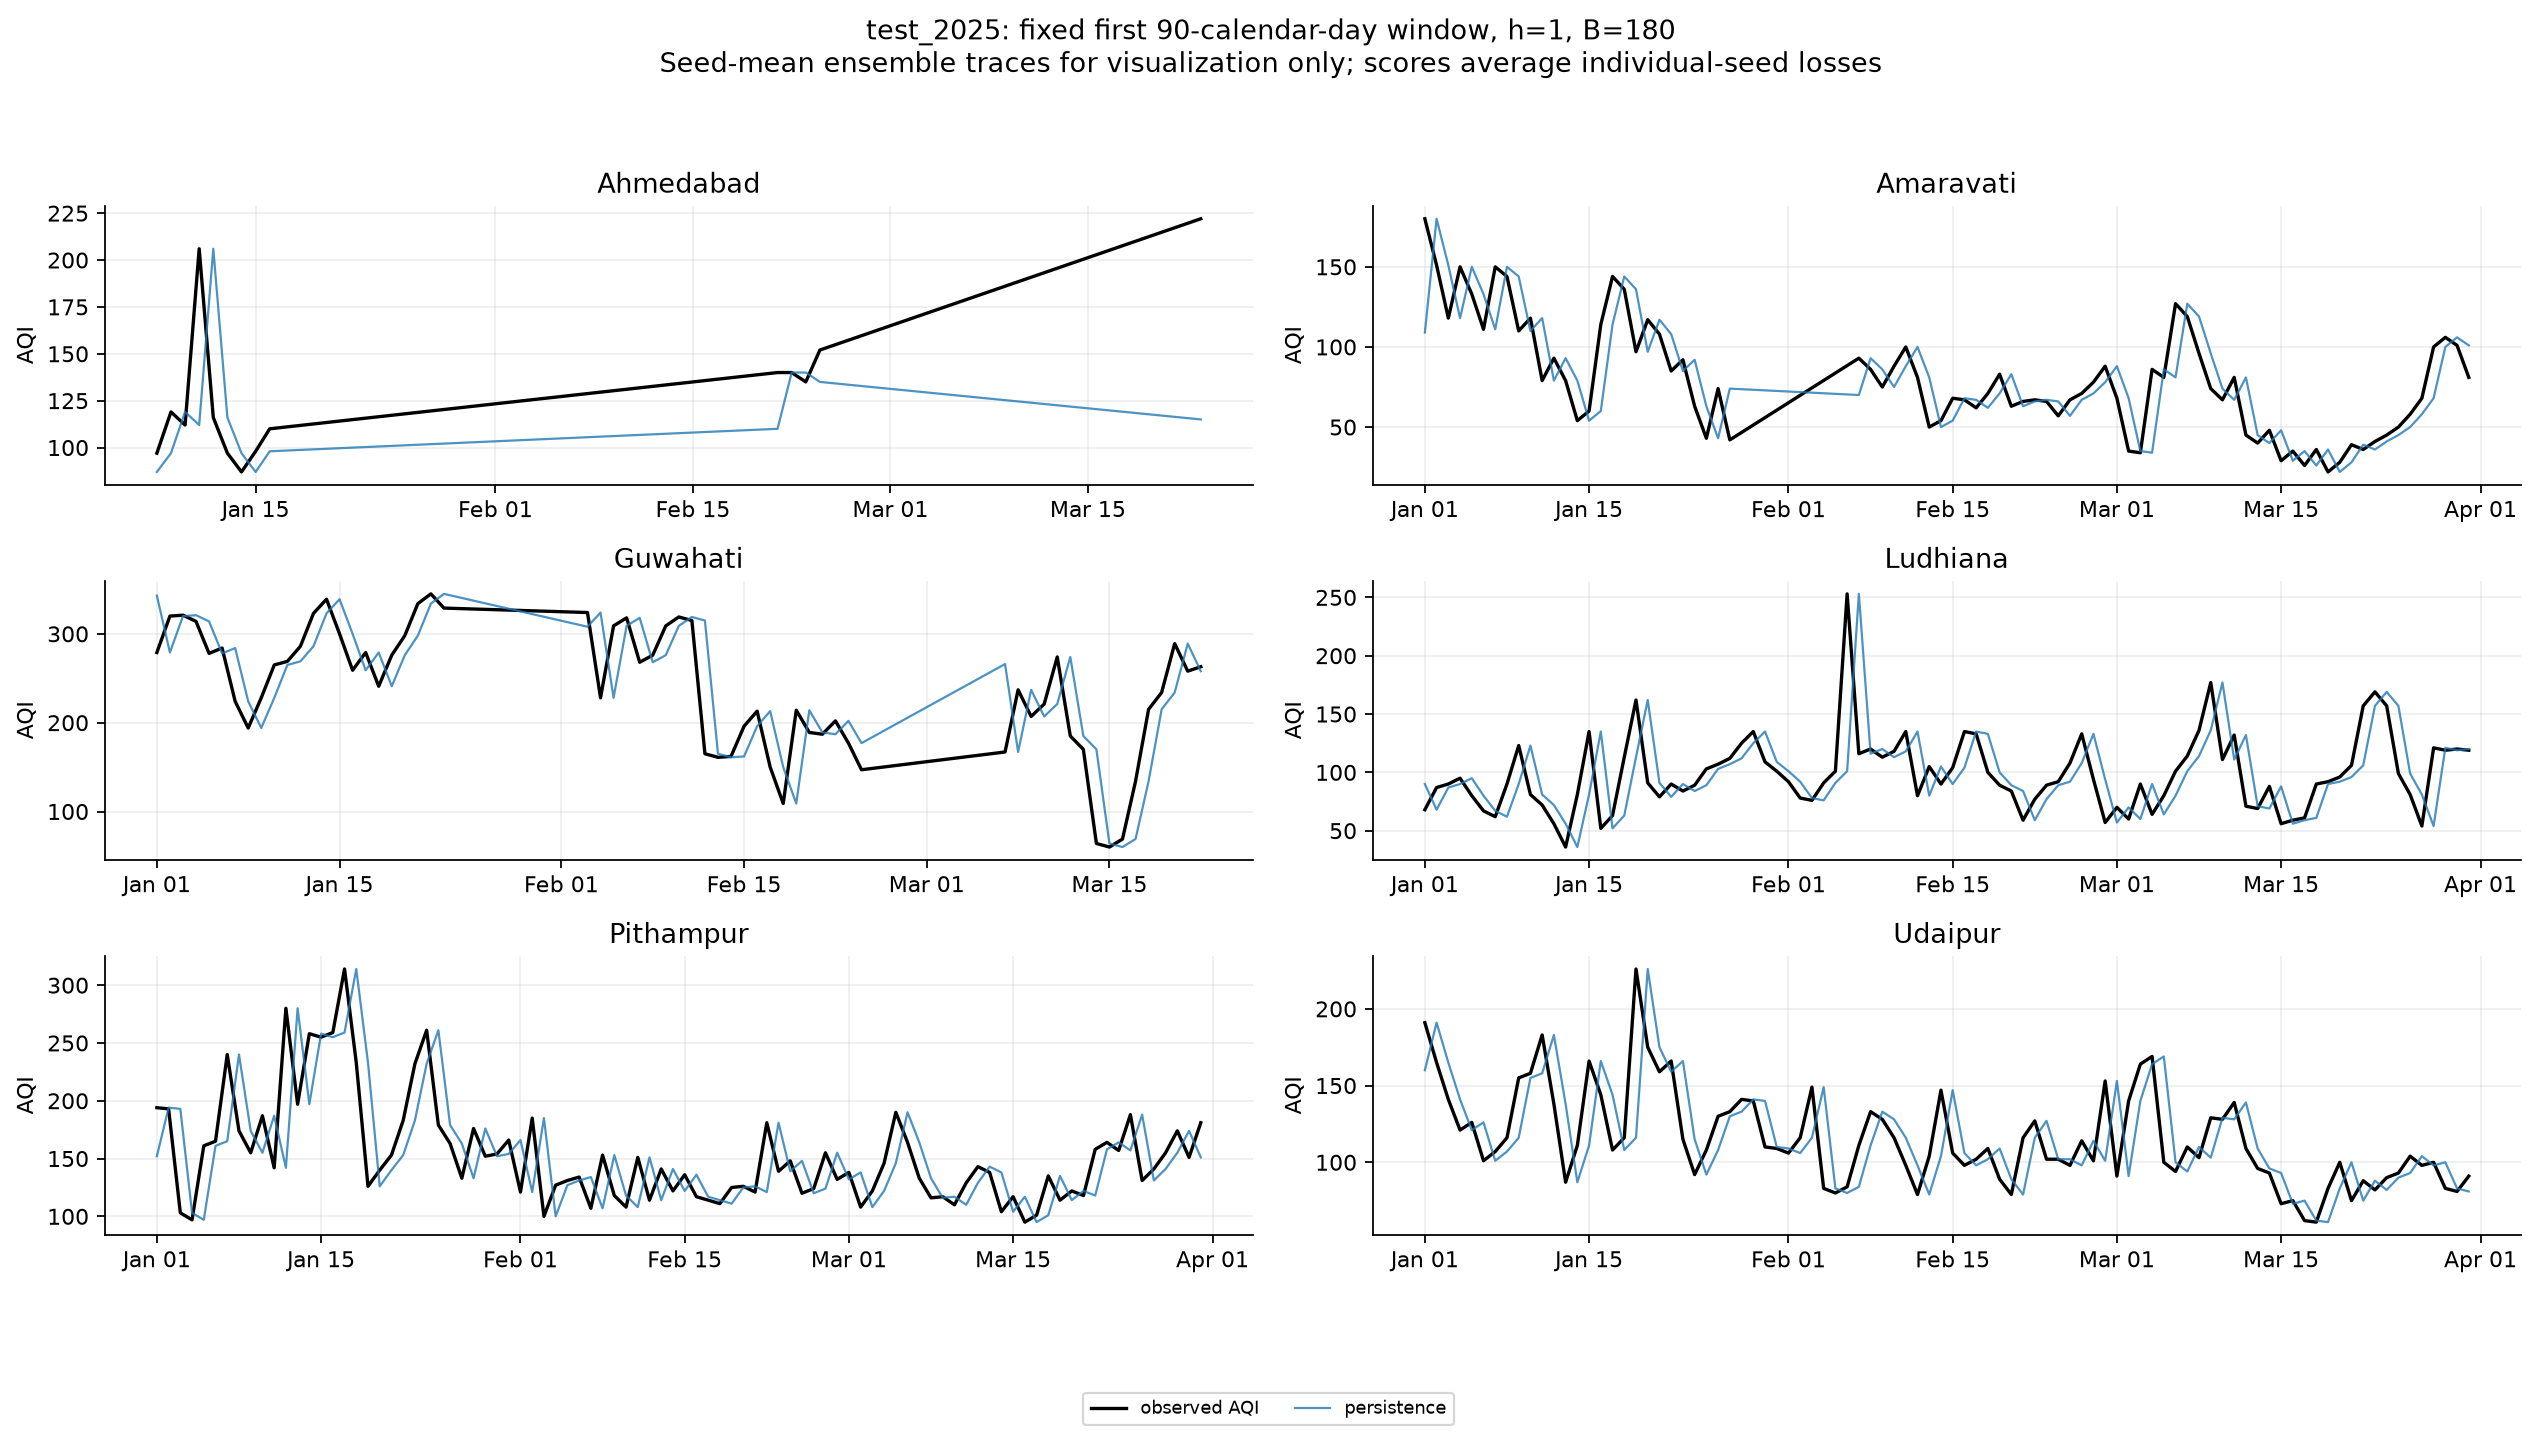

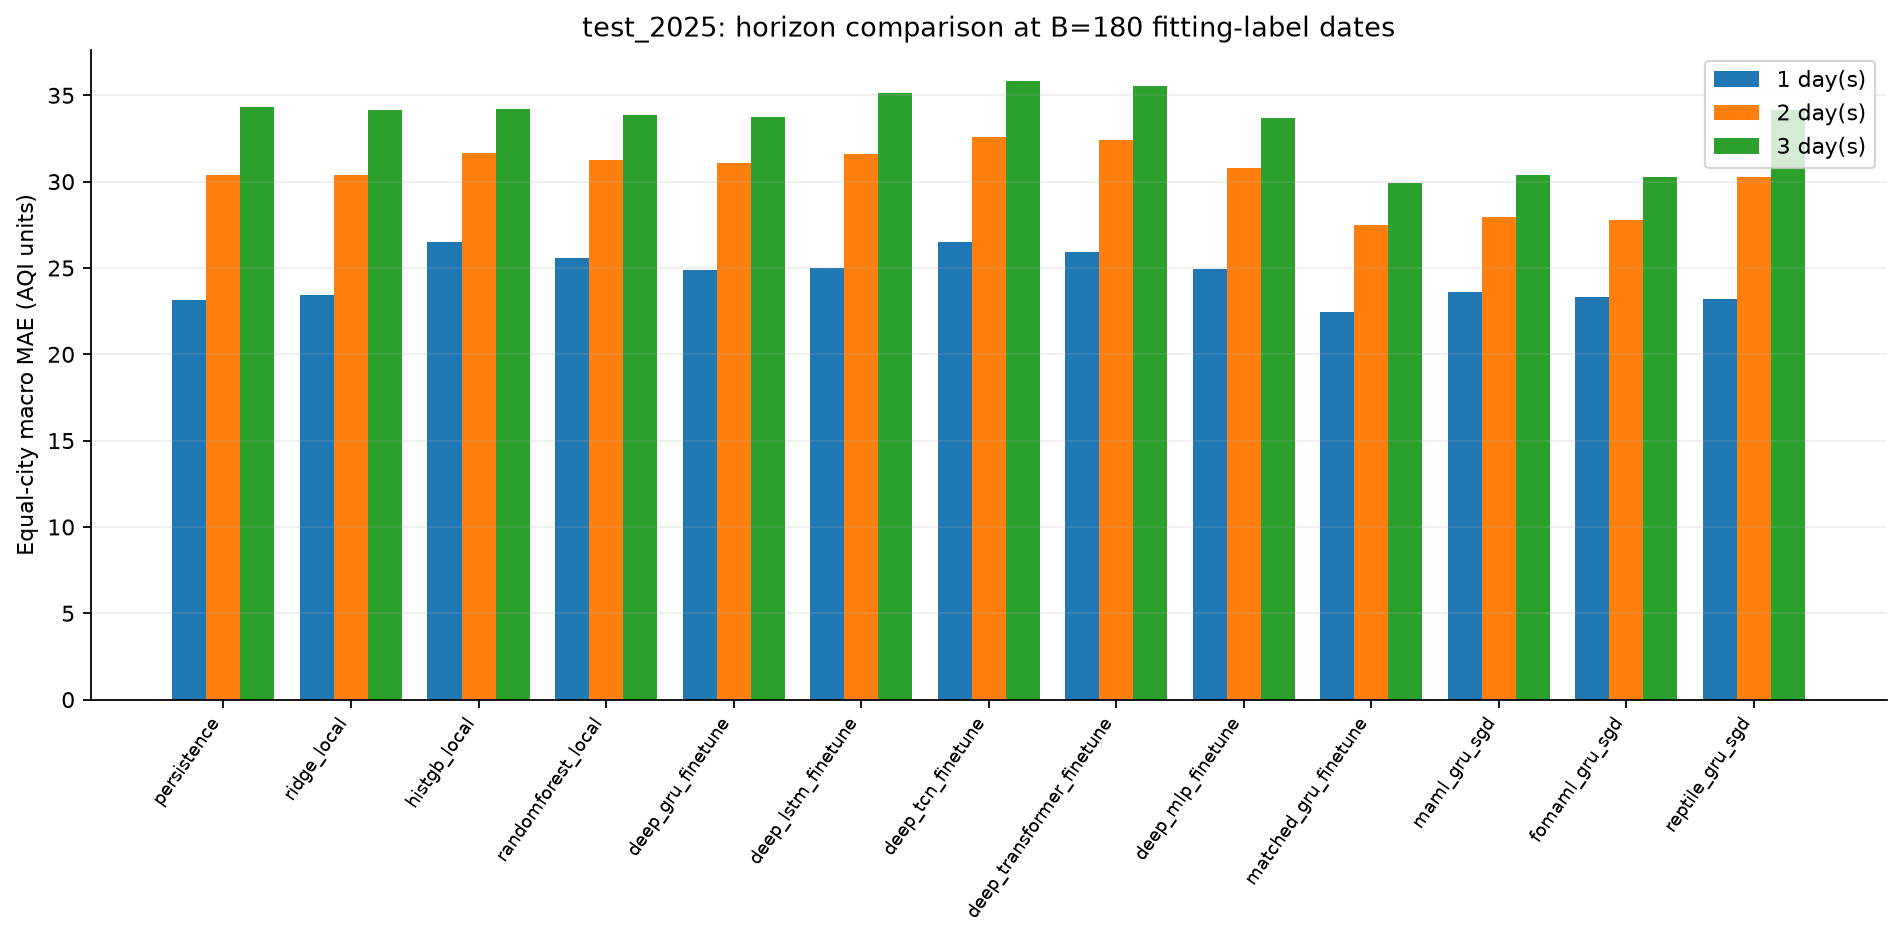

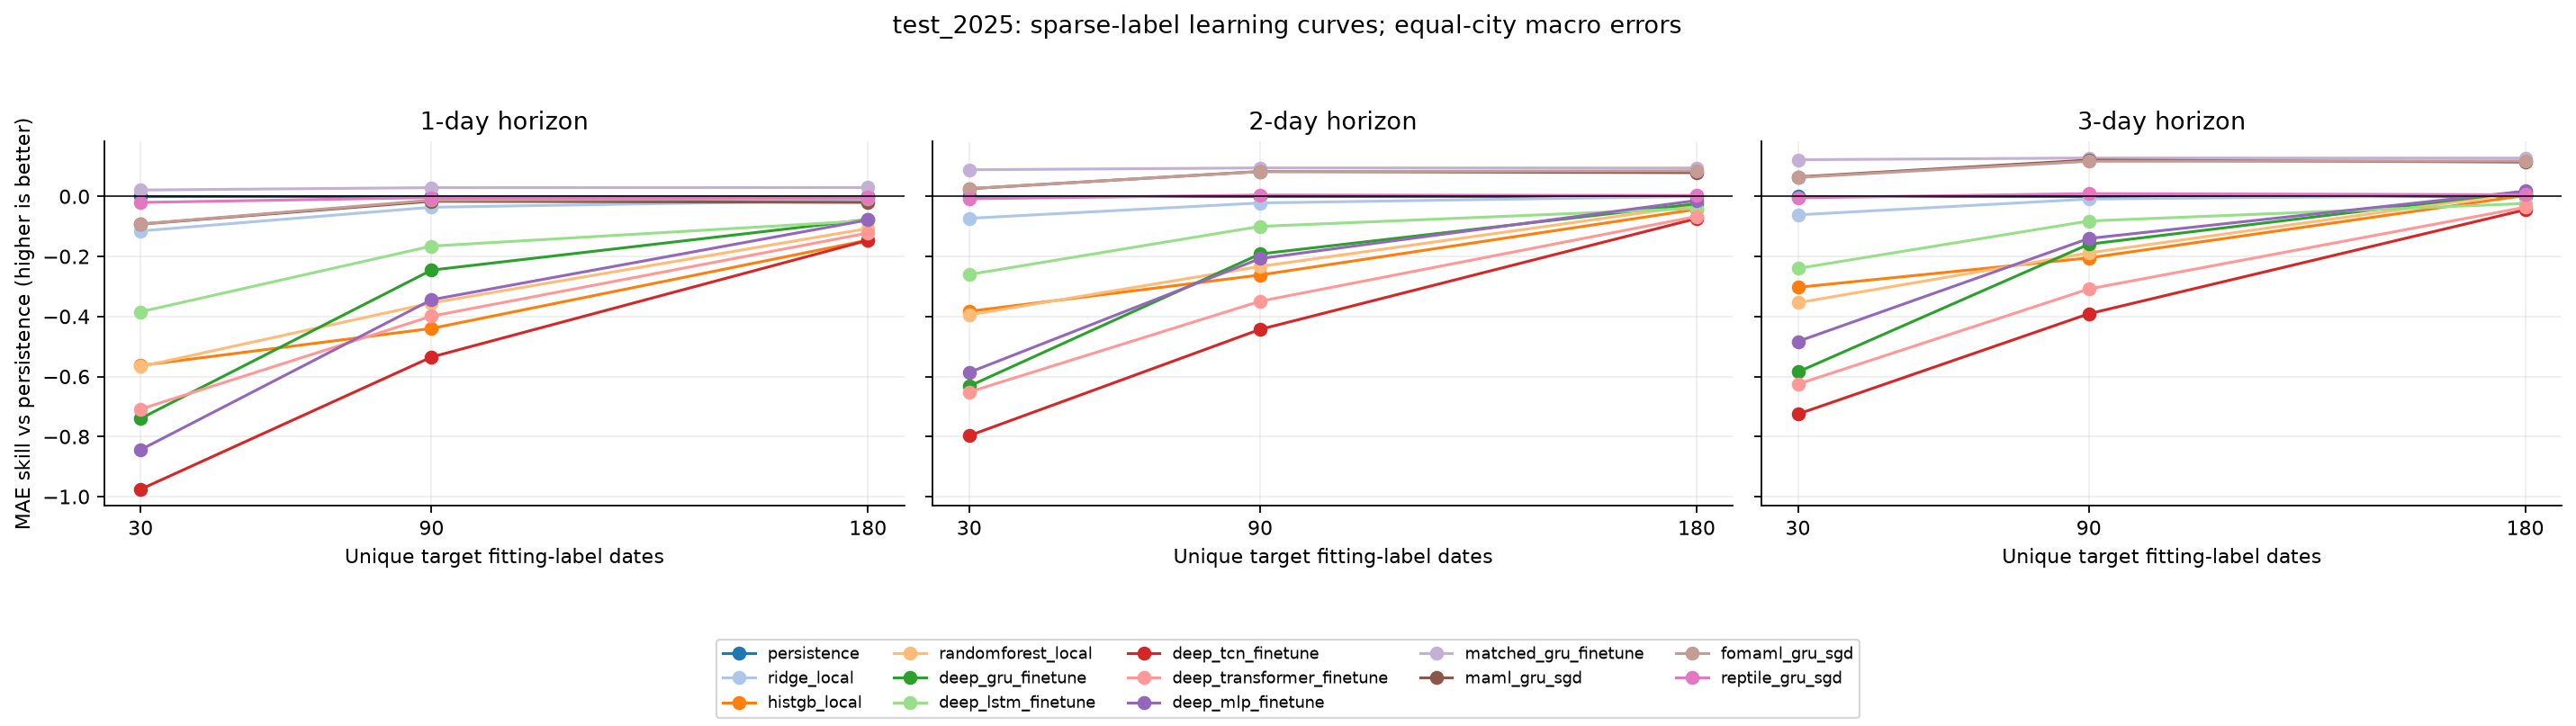

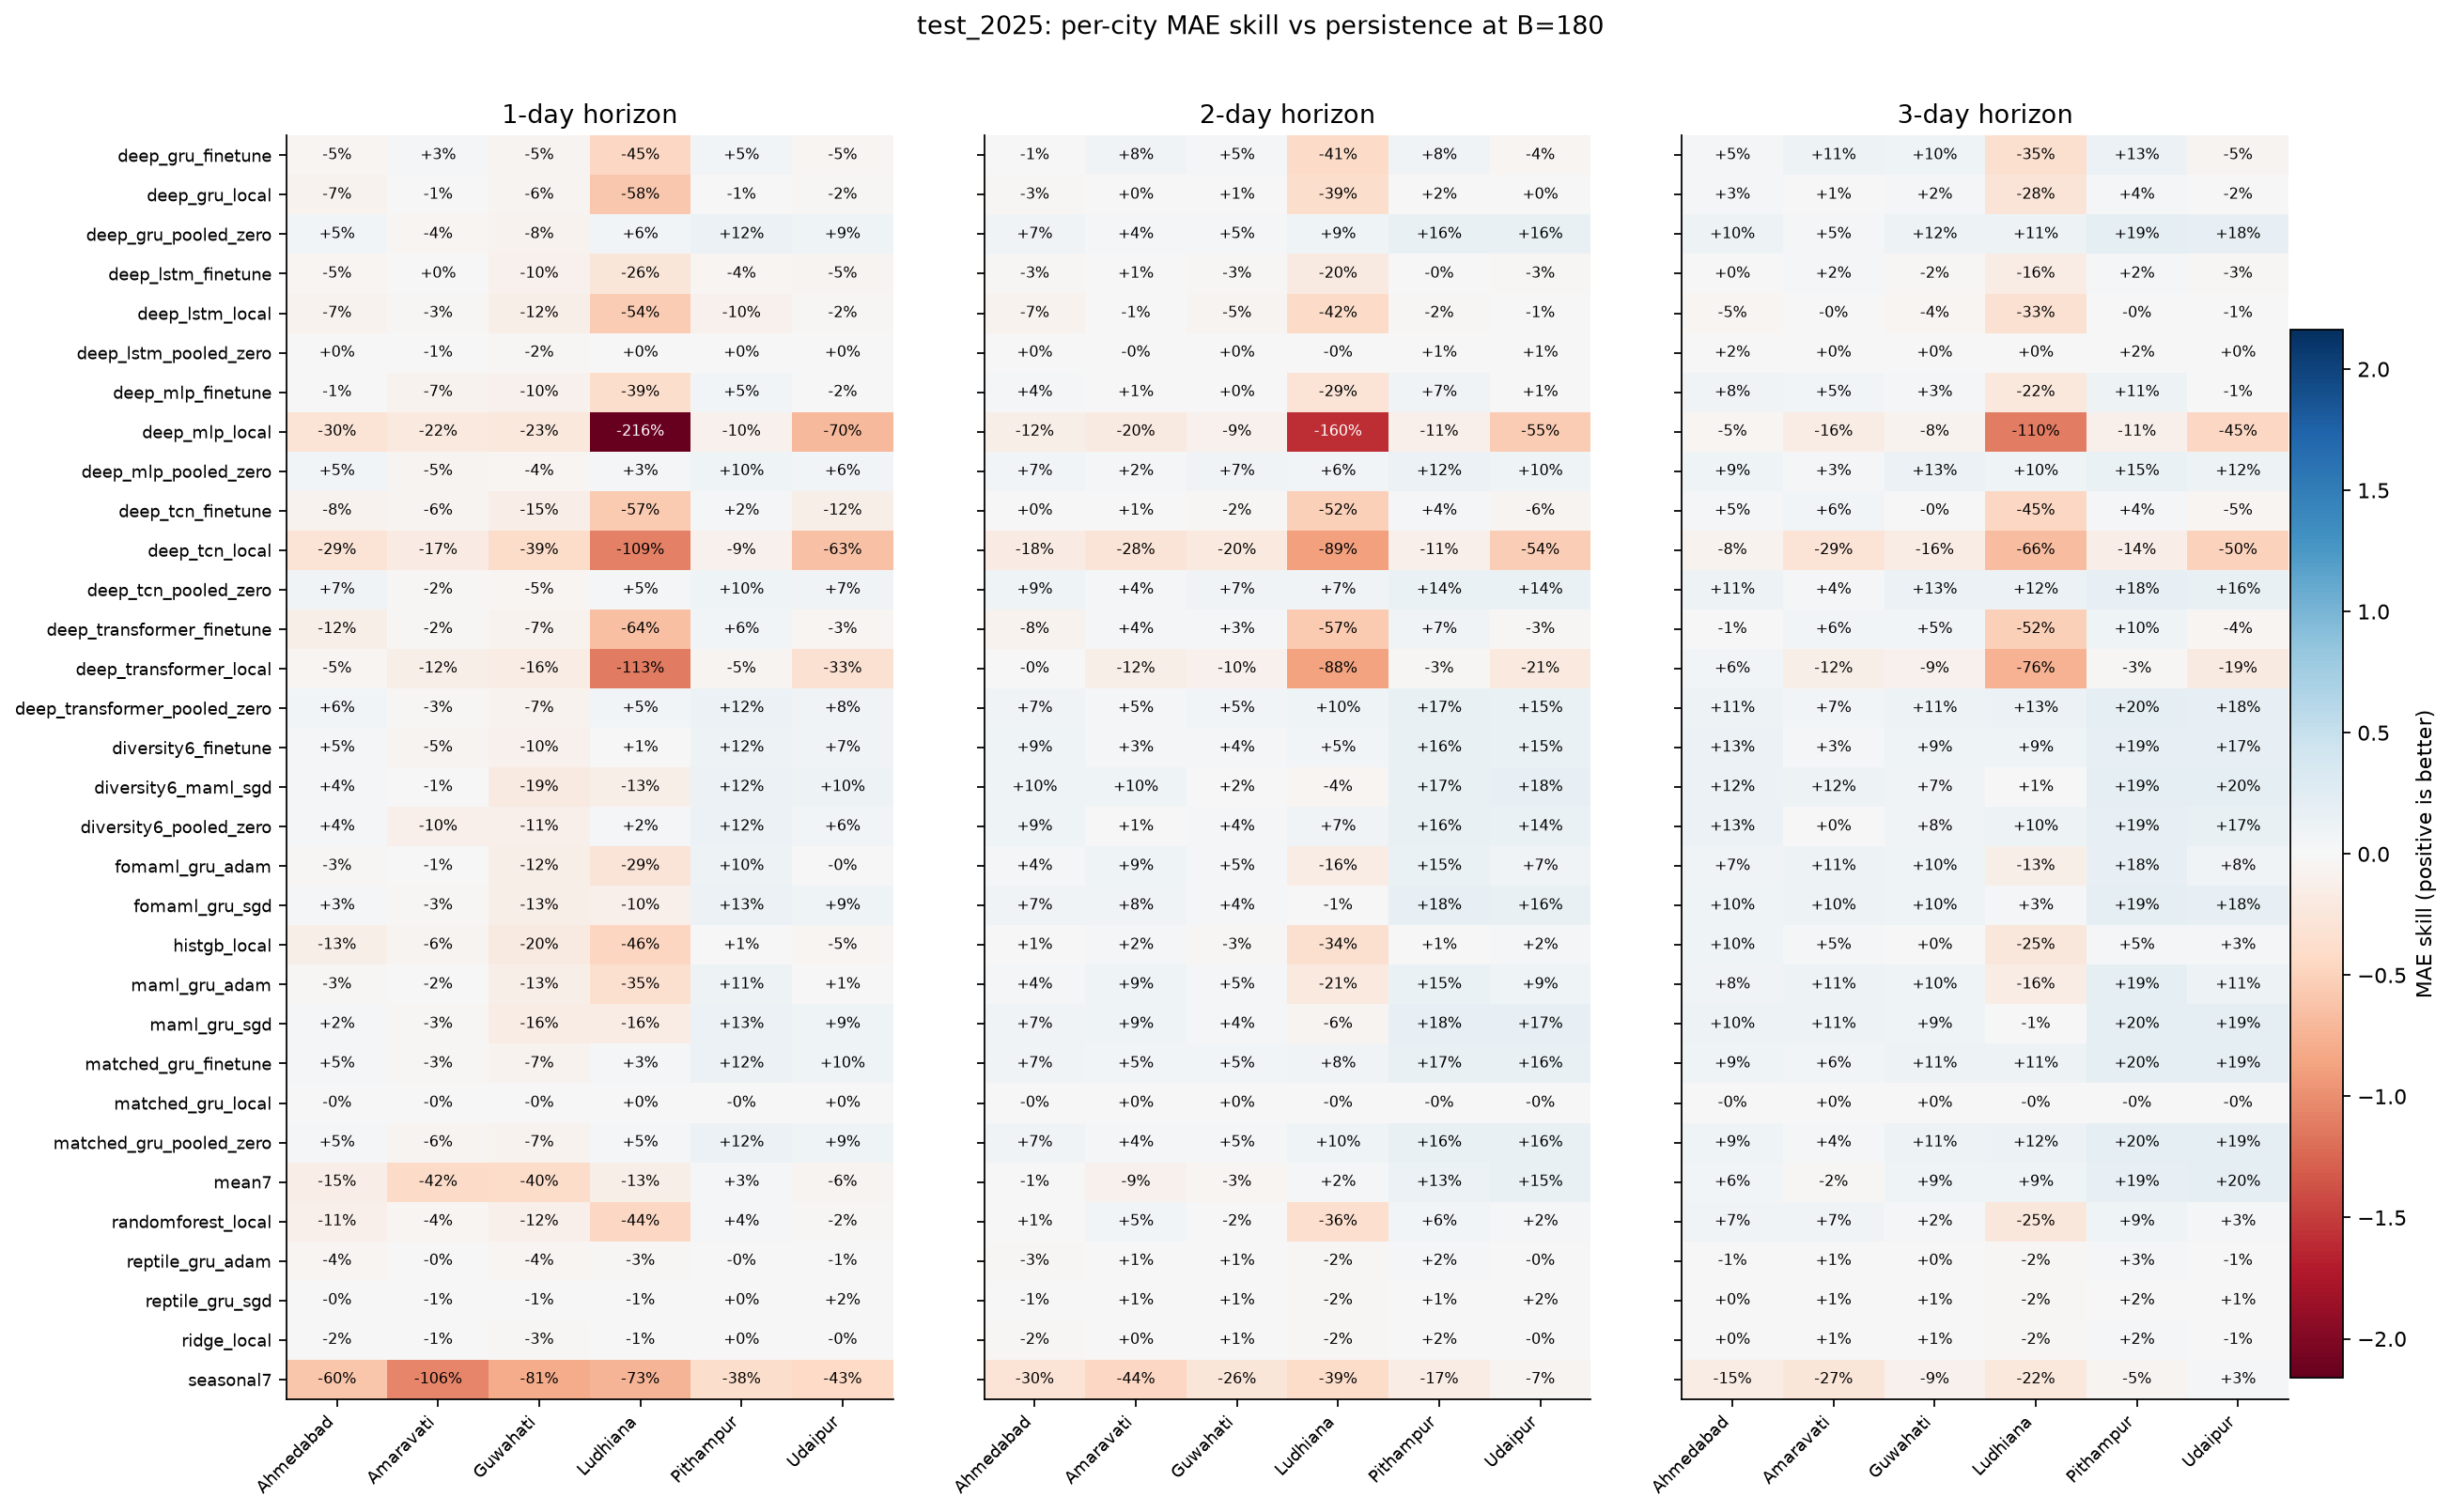

,city,station_id,period,unique_label_dates,examples,first_label,last_label,eligible_fraction_of_calendar
0,Amaravati,1406,adapt,1098,3294,2020-01-04,2023-12-17,NaN
1,Amaravati,1406,secondary_2024,240,720,2024-01-18,2024-12-31,0.655738
2,Amaravati,1406,test_2025,266,798,2025-01-01,2025-12-31,0.728767
3,Guwahati,5073,adapt,1041,3123,2020-01-05,2023-12-14,NaN
4,Guwahati,5073,secondary_2024,177,531,2024-01-27,2024-12-31,0.483607
5,Guwahati,5073,test_2025,135,405,2025-01-01,2025-12-31,0.369863
6,Ahmedabad,308,adapt,1037,3111,2020-01-07,2023-12-31,NaN
7,Ahmedabad,308,secondary_2024,163,489,2024-01-04,2024-12-18,0.445355
8,Ahmedabad,308,test_2025,133,399,2025-01-08,2025-12-31,0.364384
9,Pithampur,1402,adapt,1299,3897,2020-01-04,2023-12-31,NaN


In [10]:
protocol['truth_reference']=pd.concat([f for d in bundle['targets'].values() for k,f in d.items() if k!='adapt'],ignore_index=True).rename(columns={'y':'y_true'})
protocol['eligibility_counts']=pd.read_csv(OUT/'data/eligibility.csv')
summary=analyze_research(predictions,fit_log,OUT/'evaluation',protocol)
display(Markdown((OUT/'evaluation/RESEARCH_RESULTS.md').read_text()))
display(Markdown((OUT/'evaluation/RESULTS.md').read_text().split('## Figures')[0]))
for p in sorted((OUT/'evaluation').glob('*.png')):display(Image(filename=str(p)))
protocol.pop('truth_reference',None);protocol.pop('eligibility_counts',None)


## Conclusions and remaining work
The tables answer whether the larger package improves on simple forecasts, whether full MAML adds value over first-order/ordinary transfer controls, whether adaptation choices change the result, and whether a larger donor pool helps. Mixed and negative findings remain valid. Gains over weak local fits alone do not establish useful transfer.

Coverage/identity limitations, one station per city, retrospective selection, simulated fitting-label scarcity, recency/season confounding, frozen2023 model aging and unknown operational publication latency remain. Finite donor-only searches do not prove globally optimal hyperparameters. A checkpoint at the search limit deserves a convergence caveat. The final synthesis notebook combines these results with the compact reference and independent audits.

Further work should use new predeclared target cities and rolling-origin refits, match total source volume in diversity tests, validate missing-input robustness and issue timing, expand independent meta-training tasks, and separately test weather/peer information under fair availability rules.


## Research sources
The design follows published distinctions between global/local models and gradient-based meta-learning. Citations justify methods, not a claim that these methods must improve AQI.
- [MAML, Finn et al. (2017)](https://proceedings.mlr.press/v70/finn17a.html): task support adaptation and held-out query loss.
- [First-Order Meta-Learning Algorithms, Nichol et al. (2018)](https://arxiv.org/abs/1803.02999): Reptile and first-order MAML are distinct algorithms.
- [Global and Local Forecasting Models, Montero-Manso & Hyndman](https://arxiv.org/abs/2008.00444).
- [Forecasting: Principles and Practice — benchmark methods](https://otexts.com/fpp3/toolbox.html).
- [GRU encoder-decoder, Cho et al.](https://arxiv.org/abs/1406.1078).
- [LSTM, Hochreiter & Schmidhuber](https://doi.org/10.1162/neco.1997.9.8.1735), [Transformer, Vaswani et al.](https://arxiv.org/abs/1706.03762), and [TCN, Bai et al.](https://arxiv.org/abs/1803.01271). These are compact adaptations using seven-day histories, not reproductions of the original papers or evidence of long-memory learning.
- [Random forests, Breiman](https://www.stat.berkeley.edu/~breiman/randomforest2001.pdf) and [gradient boosting, Friedman](https://doi.org/10.1214/aos/1013203451).
- [Forecast evaluation pitfalls and recommendations](https://link.springer.com/article/10.1007/s10618-022-00894-5).
- [scikit-learn Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).
- [Official CPCB archive](https://airquality.cpcb.gov.in/ccr/#/repository/aqi).


In [11]:
import zipfile
with zipfile.ZipFile(str(OUT.parent/'AFML_research_results.zip'),'w',zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob('*'):
        if p.is_file():z.write(p,p.relative_to(OUT.parent))
print('Research artifacts:',OUT)


Research artifacts: /Users/arjun/Downloads/AFML_course_project/results/final_study_20261114/mac_research/afml_research
